
# Построение ML-модели для прогнозирования потребности велосипедов в для проката в Корее за год

Работаем с [данными](https://raw.githubusercontent.com/obulygin/content/main/SeoulBike/seoul_bike_data.csv) сервиса проката велосипедов в Корее за год.

Описание данных:
- Date - дата;
- Rented Bike Count - сколько велосипедов было взято в прокат, целевая переменная;
- Hour - час дня;
- Temperature - температура воздуха в градусах Цельсия;
- Humidity - влажность воздуха;
- Wind Speed - скорость ветра в м/с;
- Visibility - мера различимости объектов на расстоянии в 10 метров;
- Dew point temperature -  температура, зарегистрированная в начале дня, в градусах Цельсия;
- Solar Radiation - интенсивность солнечного света;
- Rainfall - количество осадков в мм;
- Snowfall - количество выпавшего снега в мм;
- Seasons - время года;
- Holiday - является ли день праздничным;
- Functioning Day - маркер, работал ли сервис проката в указанное время.

**Цель работы**: изучить данные и выявить факторы влияющие на спрос велосипедов.

**Задачи**:  
1) Провести предобработку данных: проверить данные на наличие выбросов, ошибочных значений, пропусков, дубликатов и некорректных типов.  
2) Провести EDA: реализовать все уровни анализа (одномерные/многомерные) с использованием визуализаций, изучить распределения и взаимосвязь признаков.  
3) Подготовить данные для построения модели (кодирование признаков, масштабирование, разбиение выборки на обучающую и тестовую).  
4) Реализовать базовую регрессионную модель прогнозирования количества велосипедов, взятых в прокат.  
5) При помощи инструментов Feature Selection и подбора гиперпараметров подобрать наилучшую прогнозную модель по adjusted R2 (основная метрика) и RMSE.

Обязательный критерий: добиться adjusted R2 не менее 85%.

**Дополнительные** (необязательные) **критерии**:  
1) Использовать пайплайны.  
2) Для оптимизизации гиперпараметров использовать HyperOpt.   
3) Добиться adjusted R2 не менее 89%.    


# Загрузка даных

In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error

# Загрузка данных
data = pd.read_csv('https://raw.githubusercontent.com/obulygin/content/main/SeoulBike/seoul_bike_data.csv', encoding='ISO-8859-1')
data

,Date,Rented Bike Count,Hour,Temperature(°C),Humidity(%),Wind speed (m/s),Visibility (10m),Dew point temperature(°C),Solar Radiation (MJ/m2),Rainfall(mm),Snowfall (cm),Seasons,Holiday,Functioning Day
0,01/12/2017,254,0,-5.2,37,2.2,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes
1,01/12/2017,204,1,-5.5,38,0.8,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes
2,01/12/2017,173,2,-6.0,39,1.0,2000,-17.7,0.0,0.0,0.0,Winter,No Holiday,Yes
3,01/12/2017,107,3,-6.2,40,0.9,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes
4,01/12/2017,78,4,-6.0,36,2.3,2000,-18.6,0.0,0.0,0.0,Winter,No Holiday,Yes
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8755,30/11/2018,1003,19,4.2,34,2.6,1894,-10.3,0.0,0.0,0.0,Autumn,No Holiday,Yes
8756,30/11/2018,764,20,3.4,37,2.3,2000,-9.9,0.0,0.0,0.0,Autumn,No Holiday,Yes
8757,30/11/2018,694,21,2.6,39,0.3,1968,-9.9,0.0,0.0,0.0,Autumn,No Holiday,Yes
8758,30/11/2018,712,22,2.1,41,1.0,1859,-9.8,0.0,0.0,0.0,Autumn,No Holiday,Yes


In [ ]:
data.columns

Index(['Date', 'Rented Bike Count', 'Hour', 'Temperature(°C)', 'Humidity(%)',
       'Wind speed (m/s)', 'Visibility (10m)', 'Dew point temperature(°C)',
       'Solar Radiation (MJ/m2)', 'Rainfall(mm)', 'Snowfall (cm)', 'Seasons',
       'Holiday', 'Functioning Day'],
      dtype='object')

# EDA

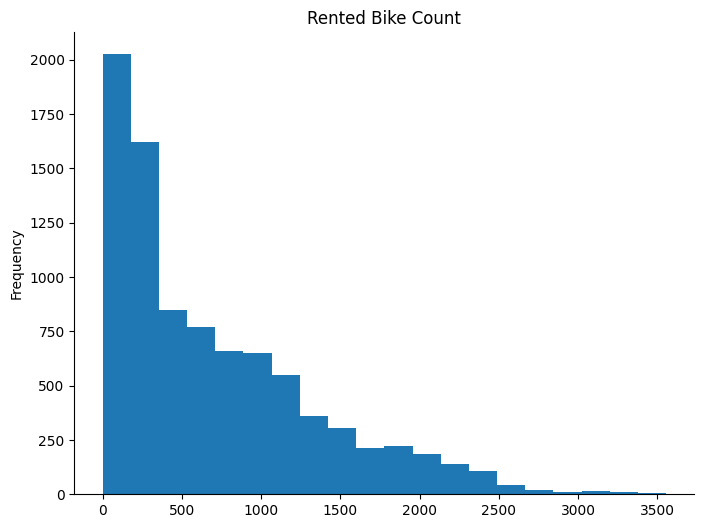

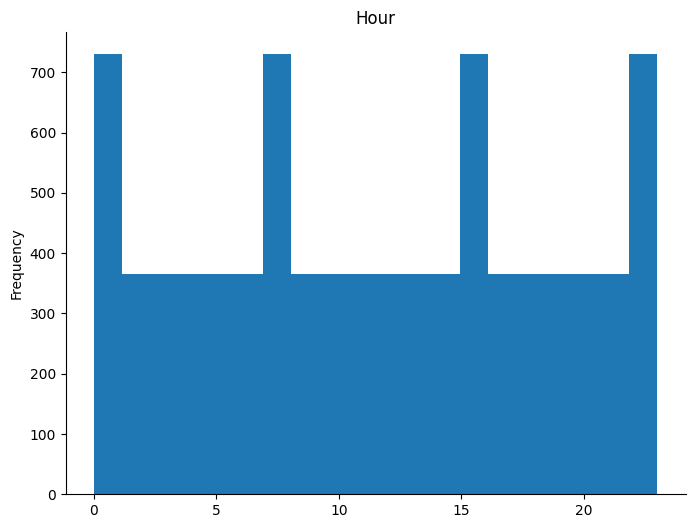

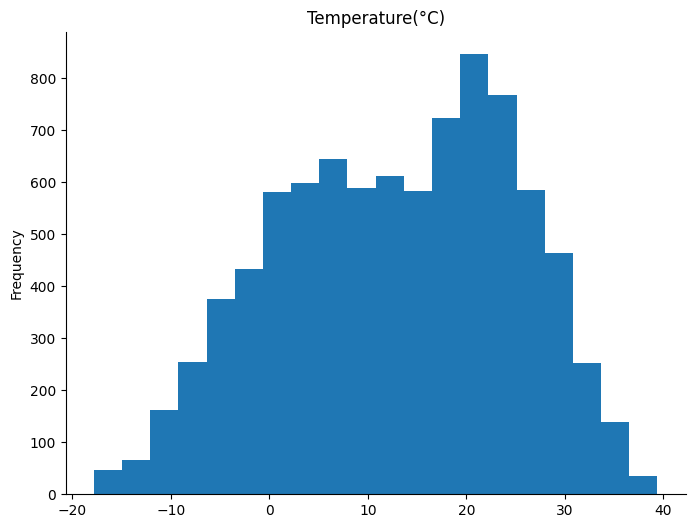

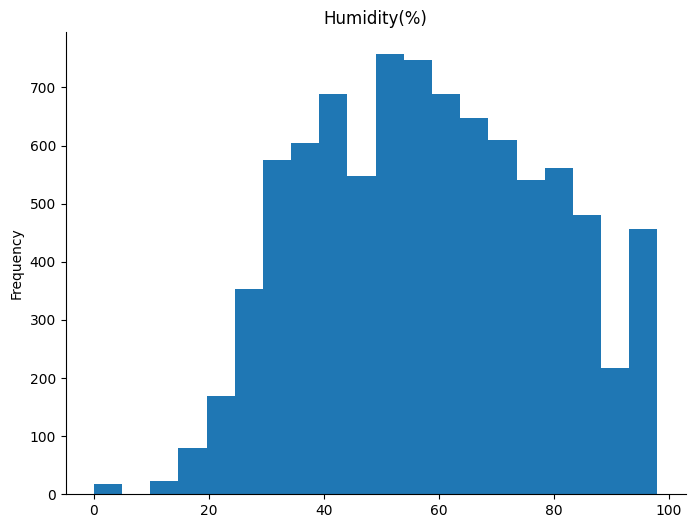

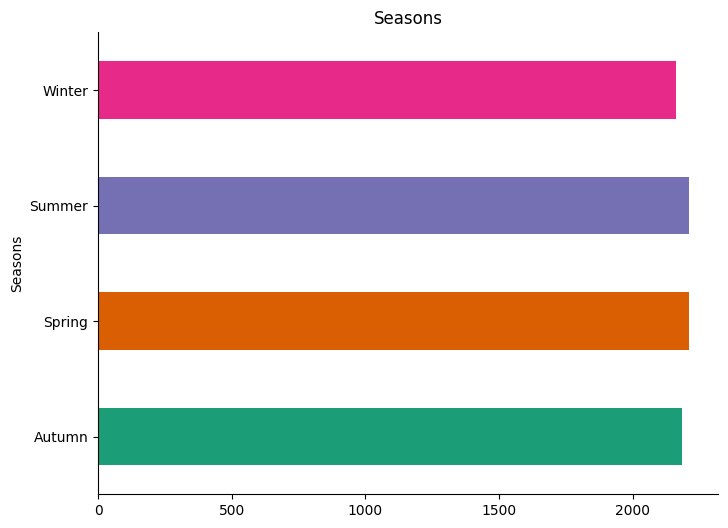

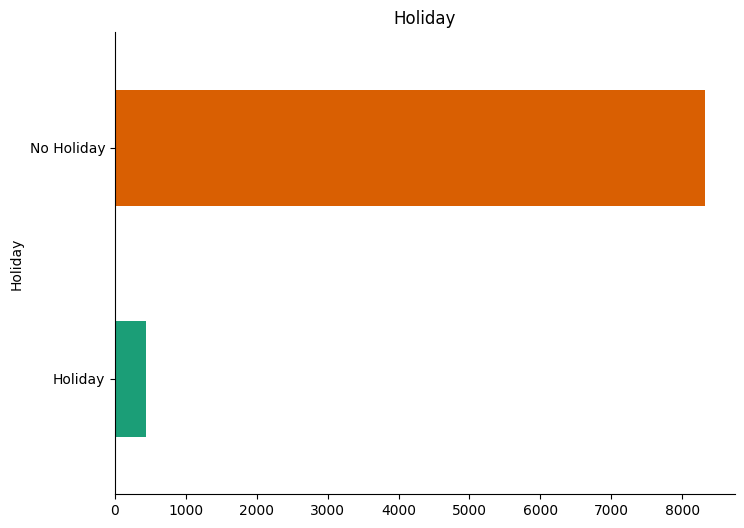

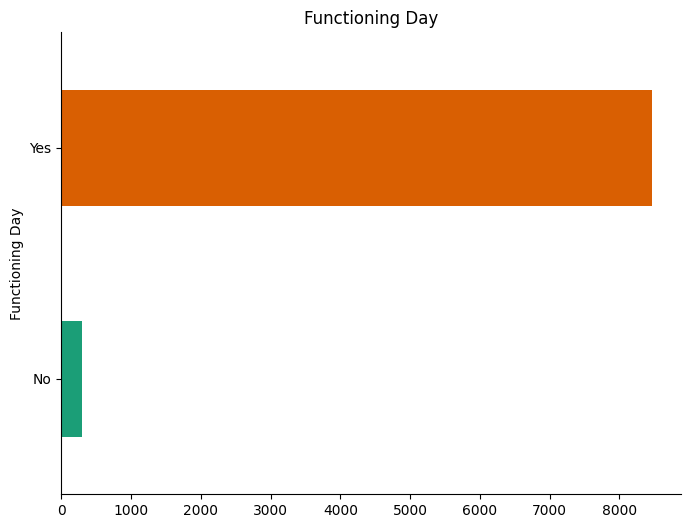

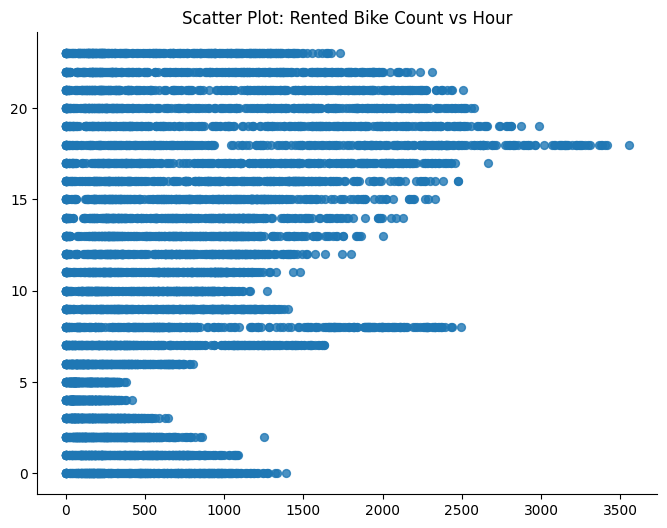

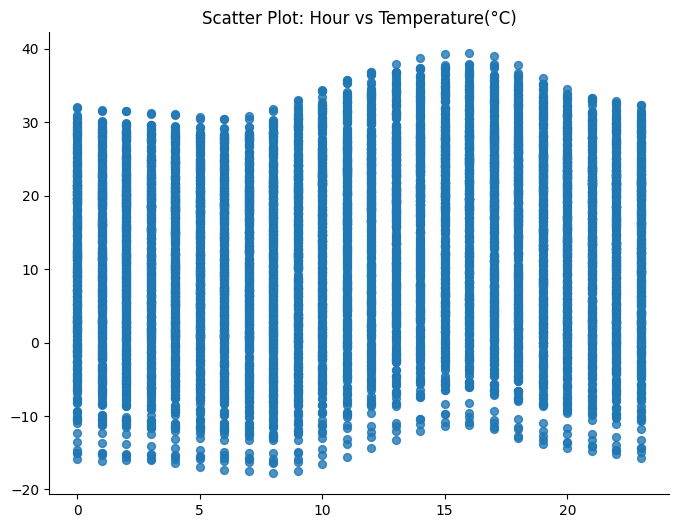

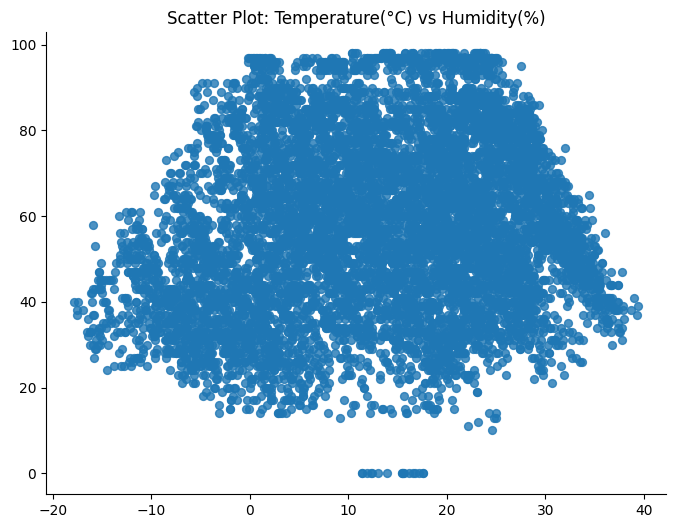

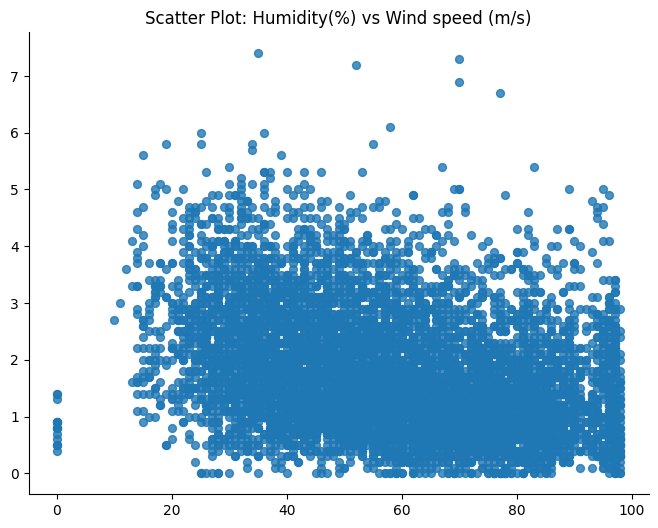

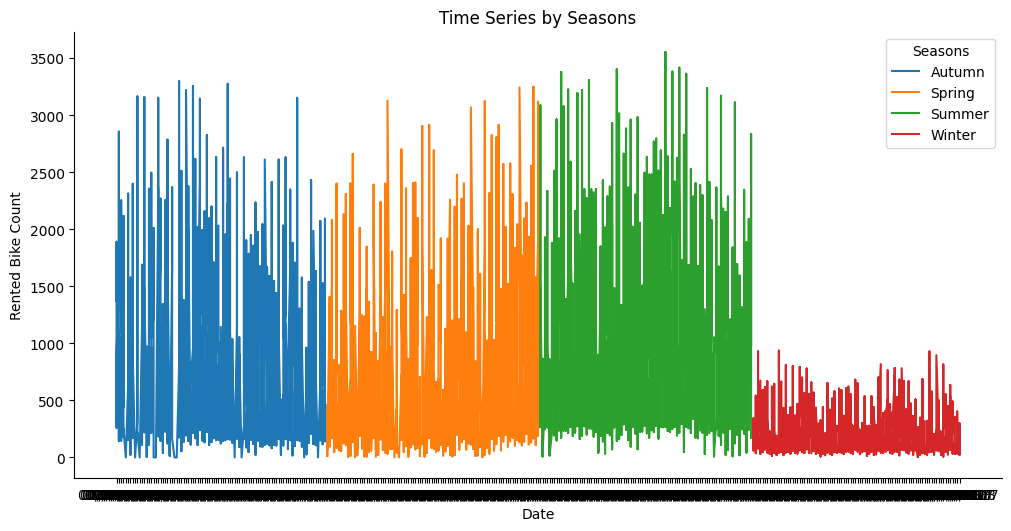

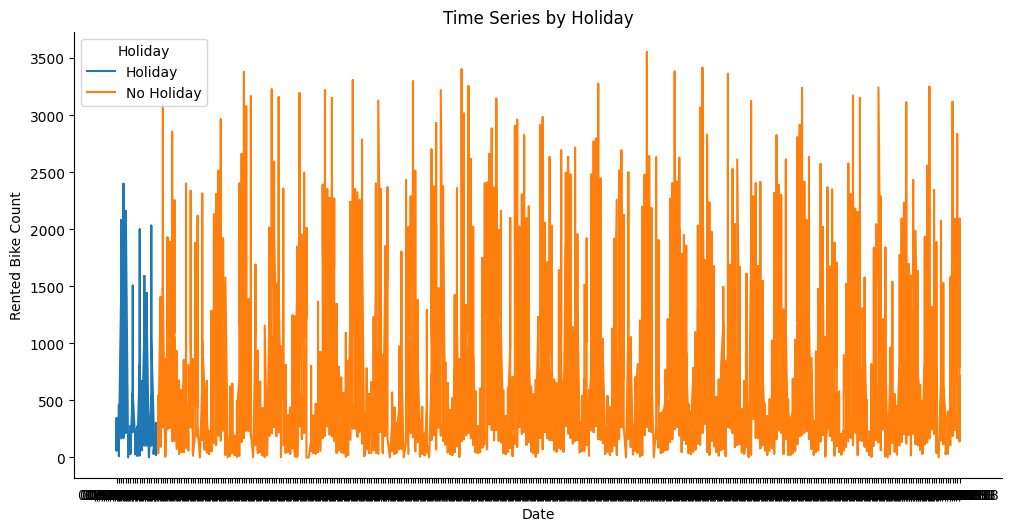

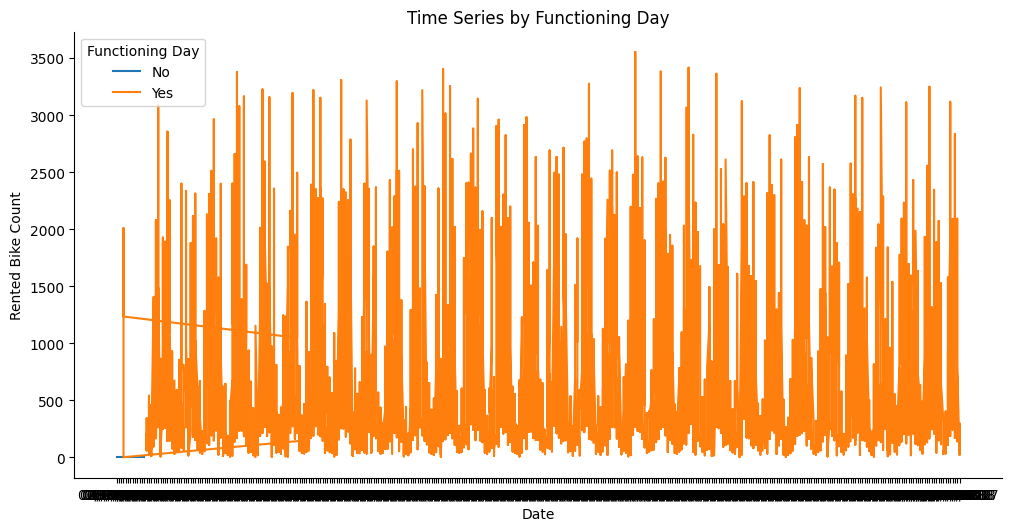

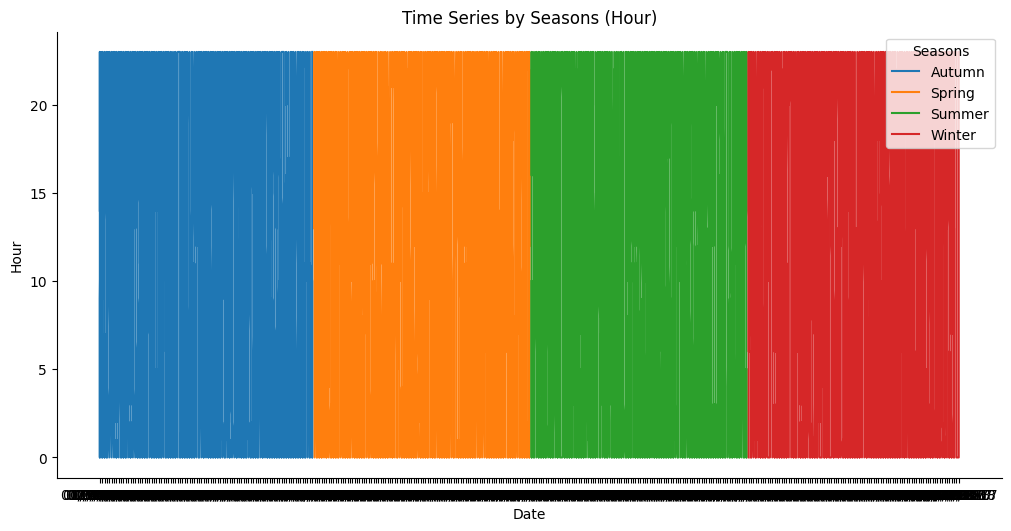

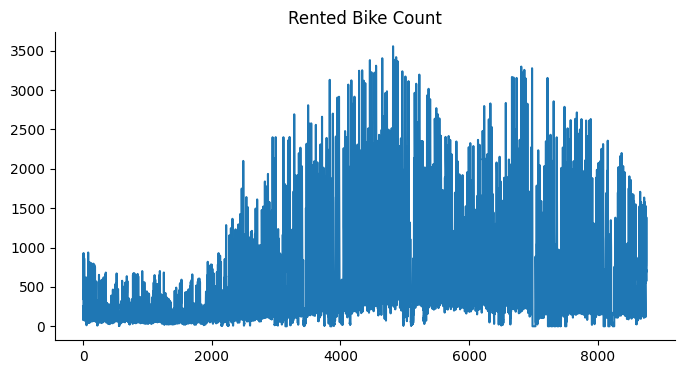

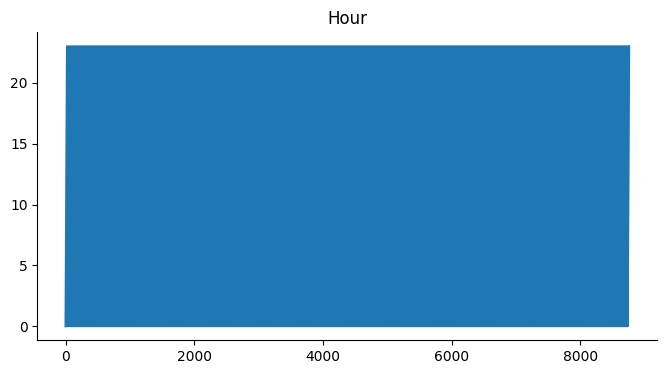

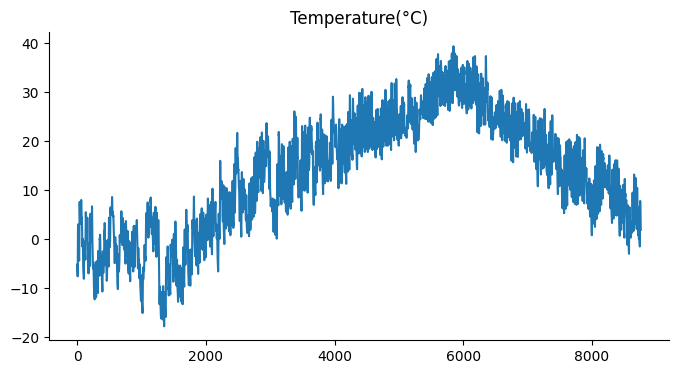

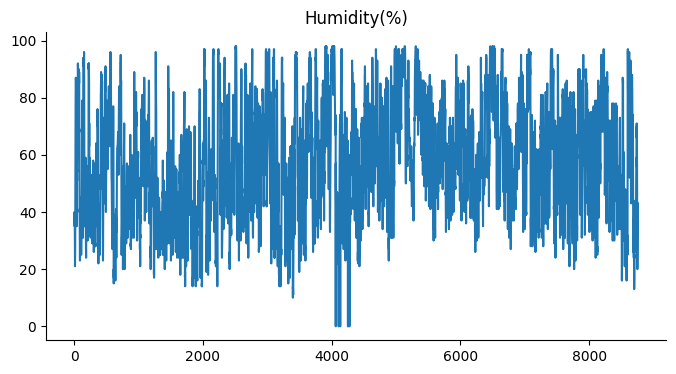

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

def plot_histogram(series, title):
    plt.figure(figsize=(8, 6))
    series.plot(kind='hist', bins=20, title=title)
    plt.gca().spines[['top', 'right']].set_visible(False)
    plt.show()

def plot_barh(series, title):
    plt.figure(figsize=(8, 6))
    series.groupby(series).size().plot(kind='barh', color=sns.palettes.mpl_palette('Dark2'))
    plt.gca().spines[['top', 'right']].set_visible(False)
    plt.title(title)
    plt.show()

def plot_scatter(x, y, title):
    plt.figure(figsize=(8, 6))
    plt.scatter(x, y, s=32, alpha=.8)
    plt.gca().spines[['top', 'right']].set_visible(False)
    plt.title(title)
    plt.show()

def plot_series(df, category_column, date_column, count_column, title):
    fig, ax = plt.subplots(figsize=(10, 5.2), constrained_layout=True)
    df_sorted = df.sort_values(date_column, ascending=True)
    for i, (series_name, series) in enumerate(df_sorted.groupby(category_column)):
        xs = series[date_column]
        ys = series[count_column]
        plt.plot(xs, ys, label=series_name)

    plt.legend(title=category_column)
    sns.despine(fig=fig, ax=ax)
    plt.xlabel(date_column)
    plt.ylabel(count_column)
    plt.title(title)
    plt.show()

def plot_line(series, title):
    plt.figure(figsize=(8, 4))
    series.plot(kind='line', title=title)
    plt.gca().spines[['top', 'right']].set_visible(False)
    plt.show()

# Пример использования функций для построения графиков
plot_histogram(data['Rented Bike Count'], 'Rented Bike Count')
plot_histogram(data['Hour'], 'Hour')
plot_histogram(data['Temperature(°C)'], 'Temperature(°C)')
plot_histogram(data['Humidity(%)'], 'Humidity(%)')
plot_barh(data['Seasons'], 'Seasons')
plot_barh(data['Holiday'], 'Holiday')
plot_barh(data['Functioning Day'], 'Functioning Day')
plot_scatter(data['Rented Bike Count'], data['Hour'], 'Scatter Plot: Rented Bike Count vs Hour')
plot_scatter(data['Hour'], data['Temperature(°C)'], 'Scatter Plot: Hour vs Temperature(°C)')
plot_scatter(data['Temperature(°C)'], data['Humidity(%)'], 'Scatter Plot: Temperature(°C) vs Humidity(%)')
plot_scatter(data['Humidity(%)'], data['Wind speed (m/s)'], 'Scatter Plot: Humidity(%) vs Wind speed (m/s)')
plot_series(data, 'Seasons', 'Date', 'Rented Bike Count', 'Time Series by Seasons')
plot_series(data, 'Holiday', 'Date', 'Rented Bike Count', 'Time Series by Holiday')
plot_series(data, 'Functioning Day', 'Date', 'Rented Bike Count', 'Time Series by Functioning Day')
plot_series(data, 'Seasons', 'Date', 'Hour', 'Time Series by Seasons (Hour)')
plot_line(data['Rented Bike Count'], 'Rented Bike Count')
plot_line(data['Hour'], 'Hour')
plot_line(data['Temperature(°C)'], 'Temperature(°C)')
plot_line(data['Humidity(%)'], 'Humidity(%)')

Датасет: seoul_bike_data

Количество строк датасета: 8760
Количество столбцов датасета: 14

Пропущенные значения:
Series([], dtype: int64)

Количество дубликатов: 0


<ipython-input-170-f452fcc28191>:24: FutureWarning: The default value of regex will change from True to False in a future version.
  data.columns = data.columns.str.replace('_(?=[^_]*$)', '')


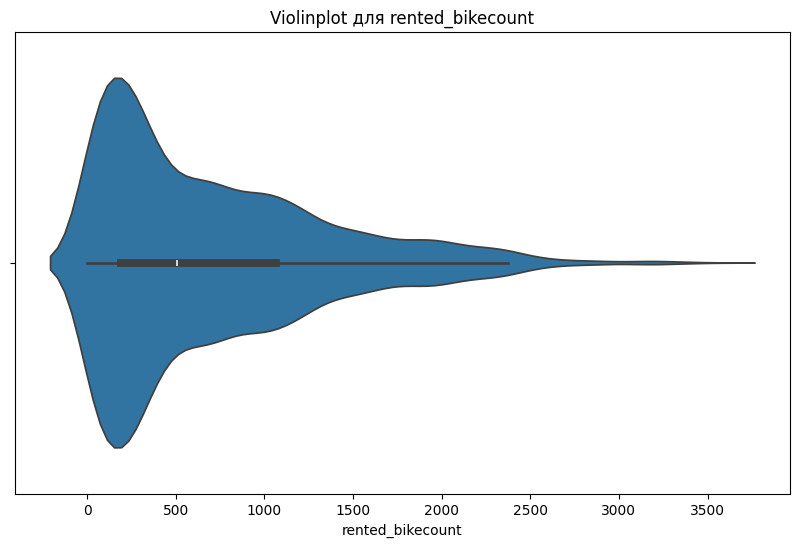

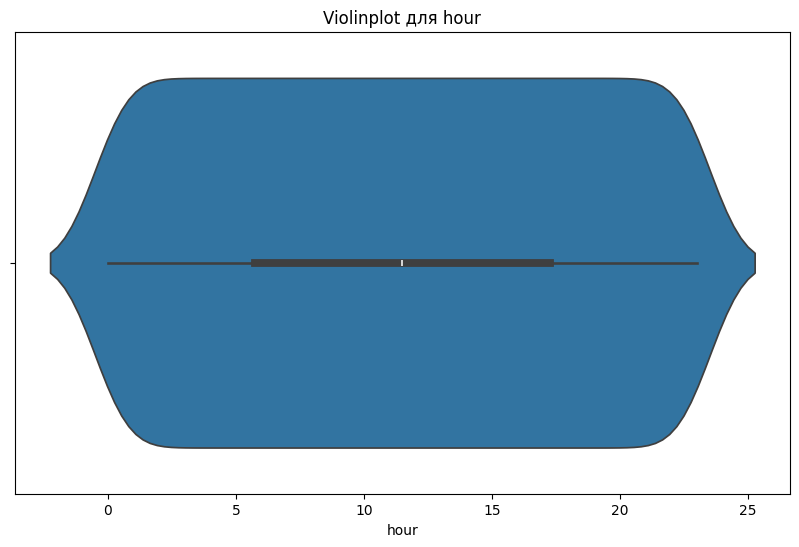

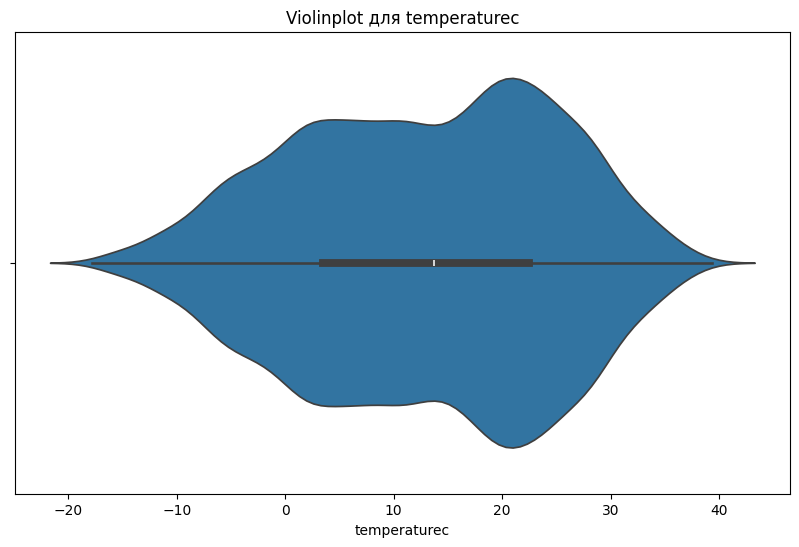

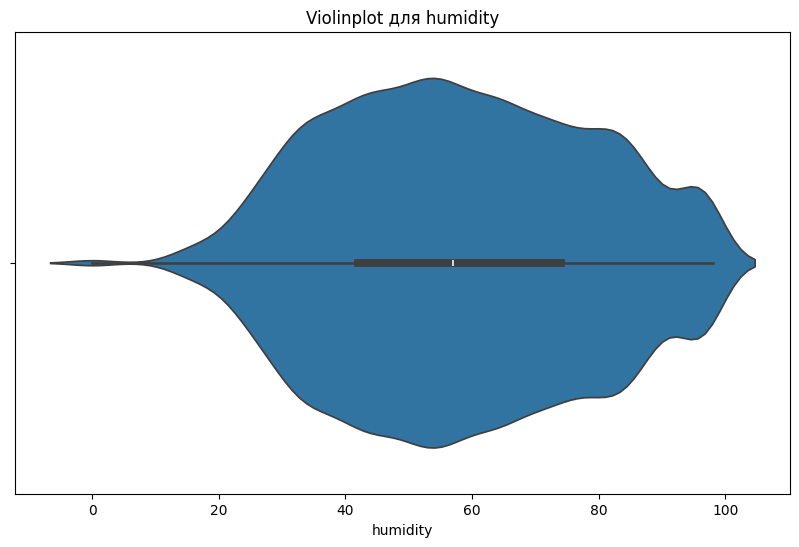

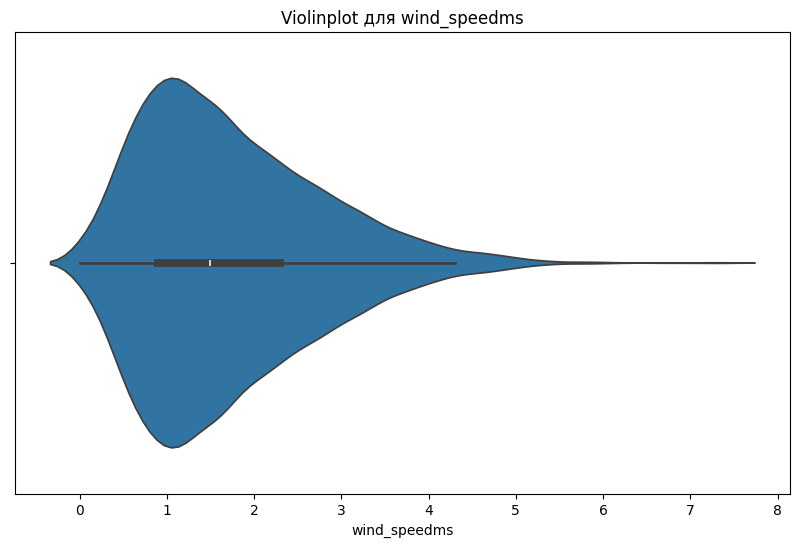

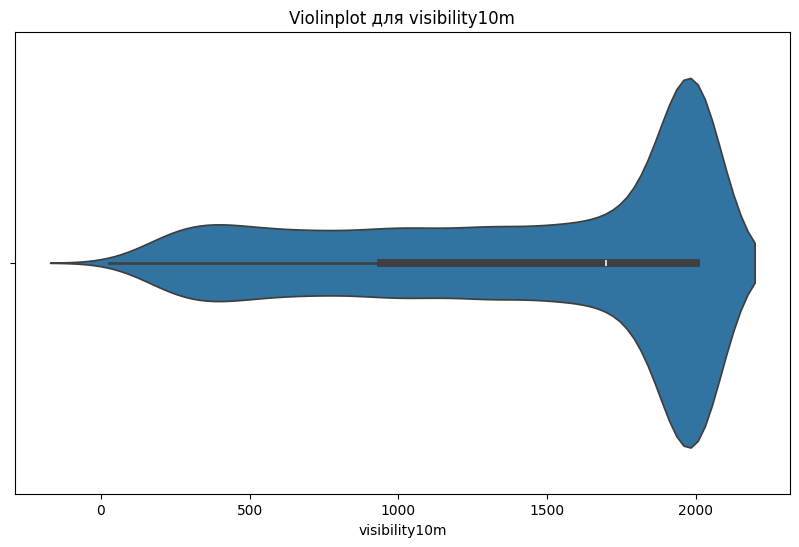

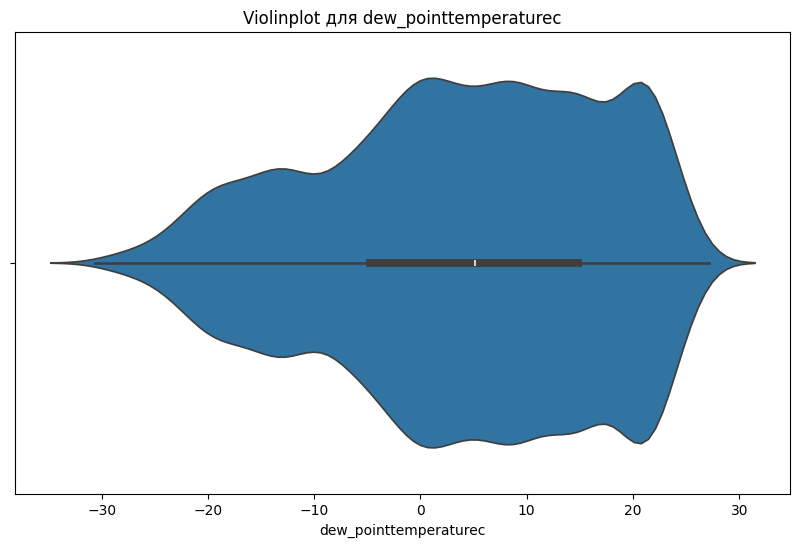

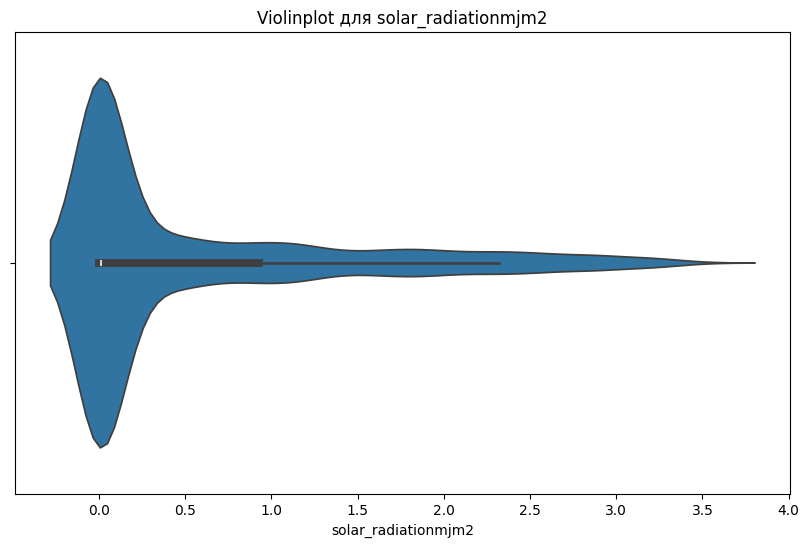

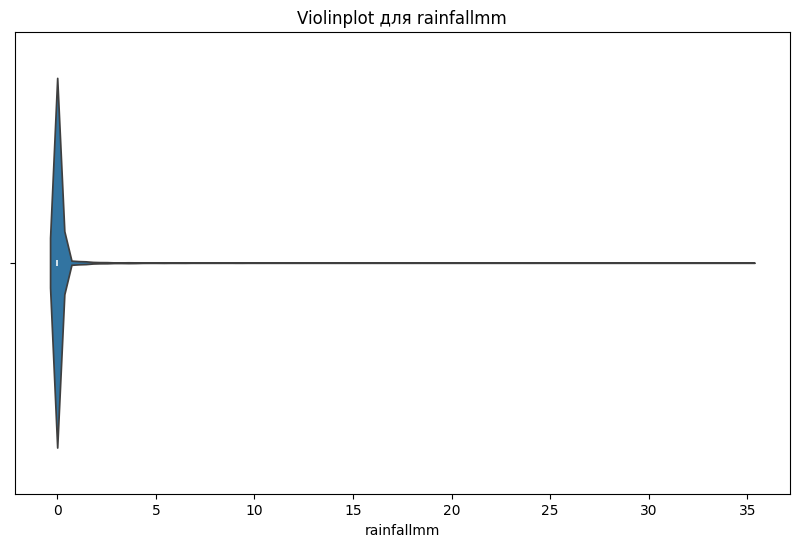

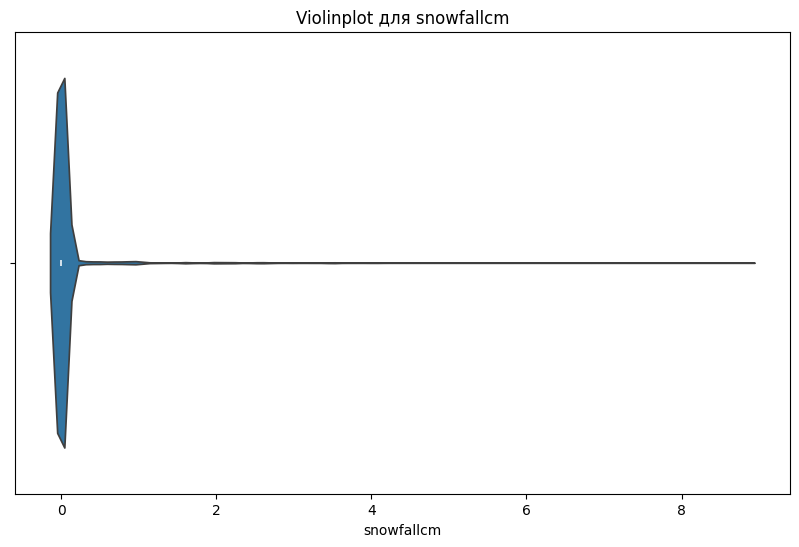


Типы данных:
date                      object
rented_bikecount           int64
hour                       int64
temperaturec             float64
humidity                   int64
wind_speedms             float64
visibility10m              int64
dew_pointtemperaturec    float64
solar_radiationmjm2      float64
rainfallmm               float64
snowfallcm               float64
seasons                   object
holiday                   object
functioningday            object
dtype: object


In [ ]:
import re

def data_preprocessing(data):
    # Вывод информации о датасете
    print(f"Датасет: {data.name}")
    print()

    # Вывод количества строк и столбцов датасета
    num_rows, num_columns = data.shape
    print(f"Количество строк датасета: {num_rows}")
    print(f"Количество столбцов датасета: {num_columns}")

    # Приведение названий столбцов к нижнему регистру
    data.columns = data.columns.str.lower()

    # Замена пробелов между словами на нижнее подчеркивание
    data.columns = data.columns.str.replace(' ', '_')

    # Удаление скобок и других лишних символов
    data.columns = data.columns.str.replace('[^a-zA-Z0-9_]', '', regex=True)
    data.columns = data.columns.str.replace('\(.*\)', '', regex=True)  # Удаление содержимого внутри скобок

    # Удаление нижних подчеркиваний в конце последнего слова в названии столбцов
    data.columns = data.columns.str.replace('_(?=[^_]*$)', '')

    # Приведение столбца с датой к традиционному формату
    if 'Date' in data.columns:
        data['Date'] = pd.to_datetime(data['Date'], format='%Y-%m-%d')

    # Проверка наличия пропущенных значений
    missing_values = data.isnull().sum()
    print("\nПропущенные значения:")
    print(missing_values[missing_values > 0])

    # Проверка наличия дубликатов
    duplicate_rows = data.duplicated()
    print("\nКоличество дубликатов:", duplicate_rows.sum())

    # Проверка наличия выбросов и ошибочных значений с использованием boxplot и violinplot
    numerical_columns = data.select_dtypes(include=[np.number]).columns
    for column in numerical_columns:
        plt.figure(figsize=(10, 6))
        sns.violinplot(x=data[column])
        plt.title(f'Violinplot для {column}')
        plt.show()

    # Проверка типов данных
    print("\nТипы данных:")
    print(data.dtypes)

# Загрузка данных
# data = pd.read_csv('https://raw.githubusercontent.com/obulygin/content/main/SeoulBike/seoul_bike_data.csv', encoding='ISO-8859-1')
data.name = 'seoul_bike_data'

# Вызов функции для проведения предобработки
data_preprocessing(data)

In [ ]:
list(data.columns)

['date',
 'rented_bikecount',
 'hour',
 'temperaturec',
 'humidity',
 'wind_speedms',
 'visibility10m',
 'dew_pointtemperaturec',
 'solar_radiationmjm2',
 'rainfallmm',
 'snowfallcm',
 'seasons',
 'holiday',
 'functioningday']

In [ ]:
data.describe()

,rented_bikecount,hour,temperaturec,humidity,wind_speedms,visibility10m,dew_pointtemperaturec,solar_radiationmjm2,rainfallmm,snowfallcm
count,8760.000000,8760.000000,8760.000000,8760.000000,8760.000000,8760.000000,8760.000000,8760.000000,8760.000000,8760.000000
mean,704.602055,11.500000,12.882922,58.226256,1.724909,1436.825799,4.073813,0.569111,0.148687,0.075068
std,644.997468,6.922582,11.944825,20.362413,1.036300,608.298712,13.060369,0.868746,1.128193,0.436746
min,0.000000,0.000000,-17.800000,0.000000,0.000000,27.000000,-30.600000,0.000000,0.000000,0.000000
25%,191.000000,5.750000,3.500000,42.000000,0.900000,940.000000,-4.700000,0.000000,0.000000,0.000000
50%,504.500000,11.500000,13.700000,57.000000,1.500000,1698.000000,5.100000,0.010000,0.000000,0.000000
75%,1065.250000,17.250000,22.500000,74.000000,2.300000,2000.000000,14.800000,0.930000,0.000000,0.000000
max,3556.000000,23.000000,39.400000,98.000000,7.400000,2000.000000,27.200000,3.520000,35.000000,8.800000


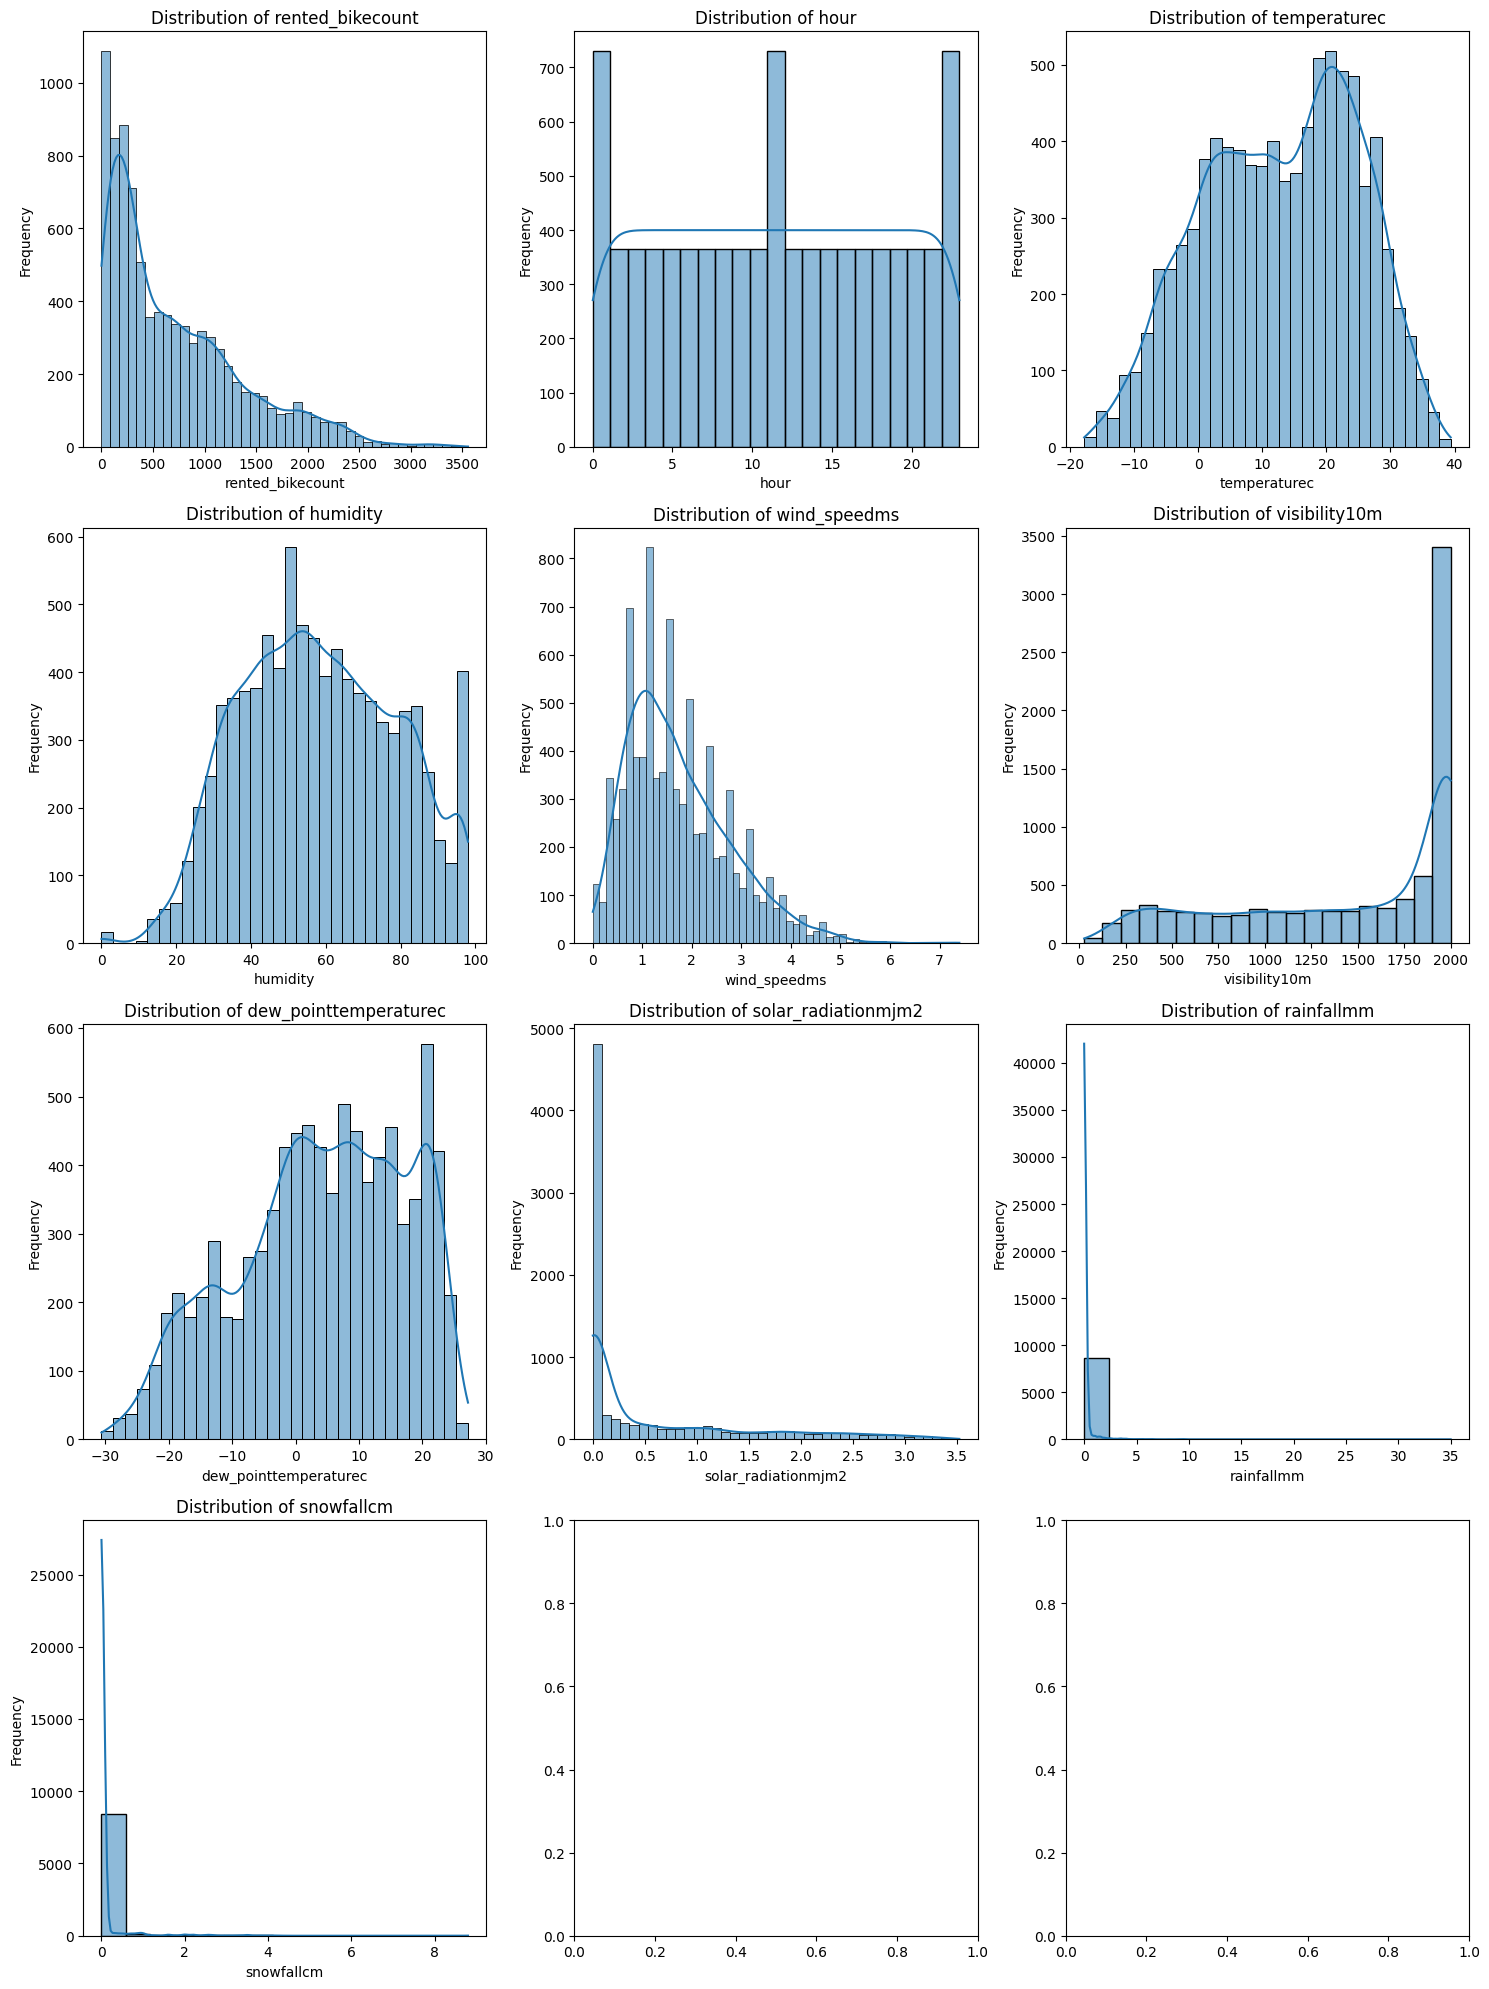

In [ ]:
def visualize_distribution(data):
    # Определение числовых признаков
    numerical_columns = data.select_dtypes(include=[np.number]).columns

    # Создание сетки графиков
    num_plots = len(numerical_columns)
    num_cols = 3  # количество столбцов в сетке
    num_rows = (num_plots // num_cols) + (num_plots % num_cols)  # вычисление количества строк

    # Размер сетки
    fig, axes = plt.subplots(num_rows, num_cols, figsize=(15, 5 * num_rows))

    # Проход по числовым признакам и отрисовка гистограмм
    for i, column in enumerate(numerical_columns):
        ax = axes[i // num_cols, i % num_cols] if num_rows > 1 else axes[i % num_cols]
        sns.histplot(data[column], kde=True, ax=ax)
        ax.set_title(f'Distribution of {column}')
        ax.set_xlabel(column)
        ax.set_ylabel('Frequency')

    # Размещение графиков в сетке
    plt.tight_layout()
    plt.show()

# Использование функции для визуализации распределения данных
visualize_distribution(data)

In [ ]:
def check_missing_values(data):

    # Проверка наличия пустых значений
    missing_values = data.isnull().sum()

    if missing_values.sum() == 0:
        print("В датасете нет пустых значений.")
    else:
        print("Пустые значения в датасете:")
        print(missing_values[missing_values > 0])

    # Проверка наличия отрицательных значений
    numeric_columns = data.select_dtypes(include=[np.number]).columns
    negative_values = (data[numeric_columns] < 0).sum()

    if negative_values.sum() == 0:
        print("\nВ датасете нет отрицательных значений.")
    else:
        print("\nОтрицательные значения в датасете:")
        print(negative_values[negative_values > 0])

# Пример использования
check_missing_values(data)

В датасете нет пустых значений.

Отрицательные значения в датасете:
temperaturec             1433
dew_pointtemperaturec    3138
dtype: int64


In [ ]:
sns.pairplot(data)

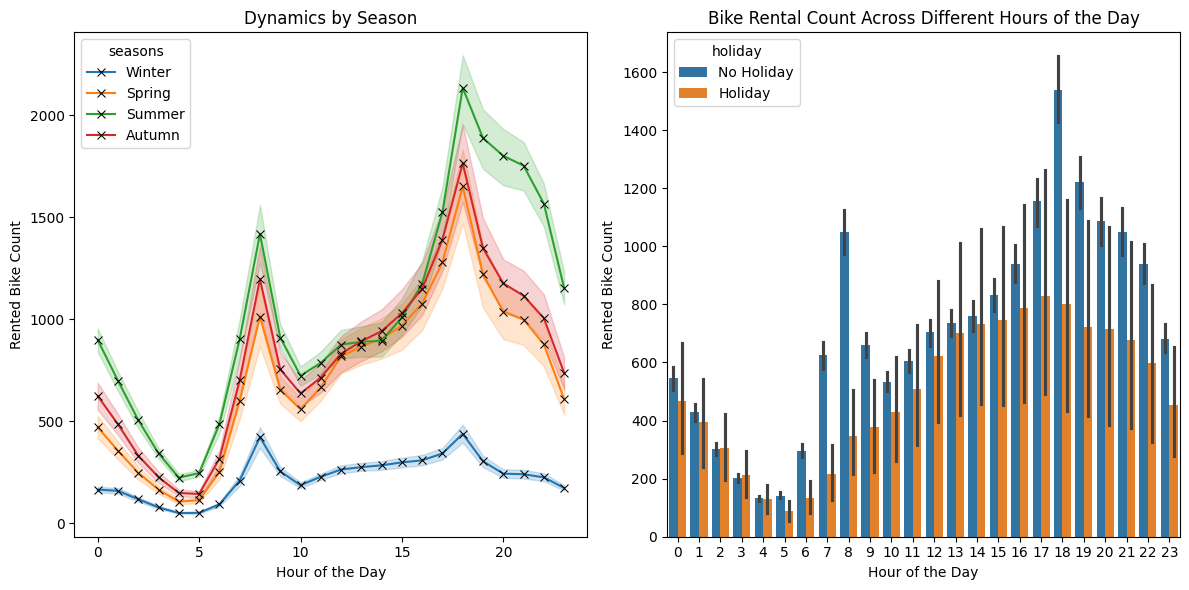

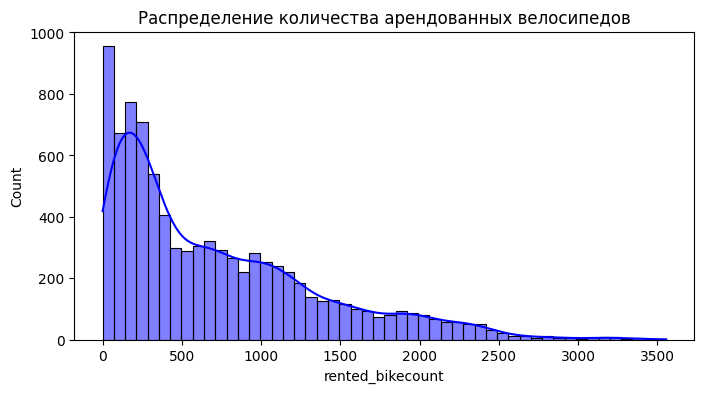

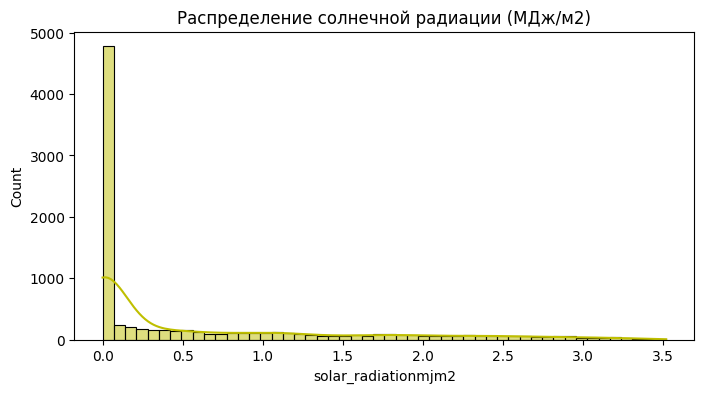

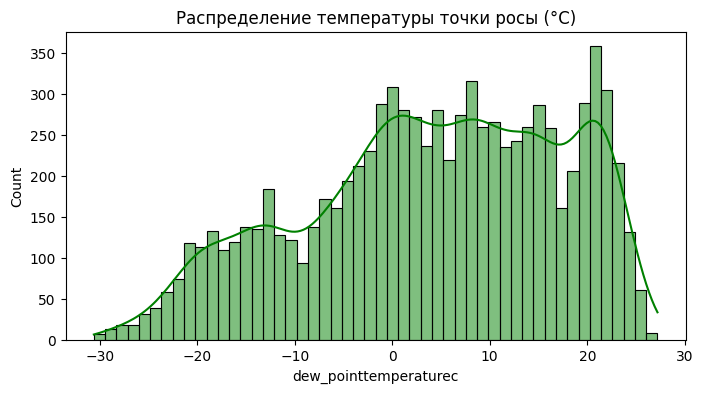

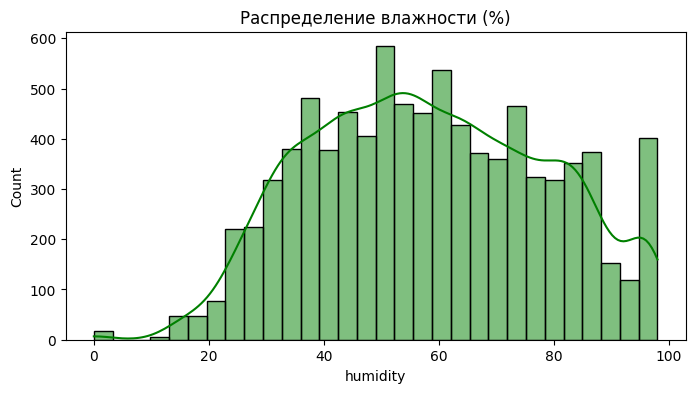

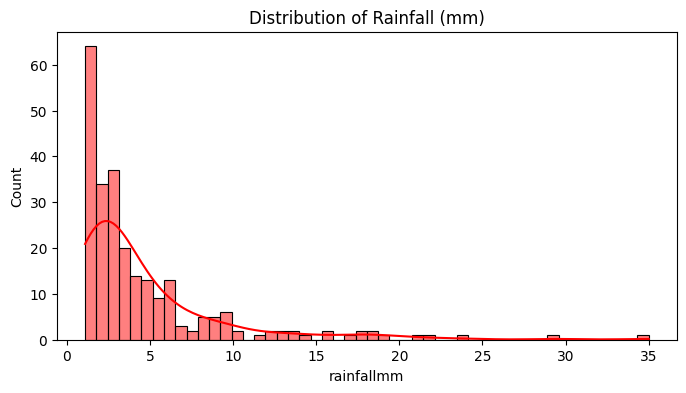

Доля дней с дождем: 13.18 %


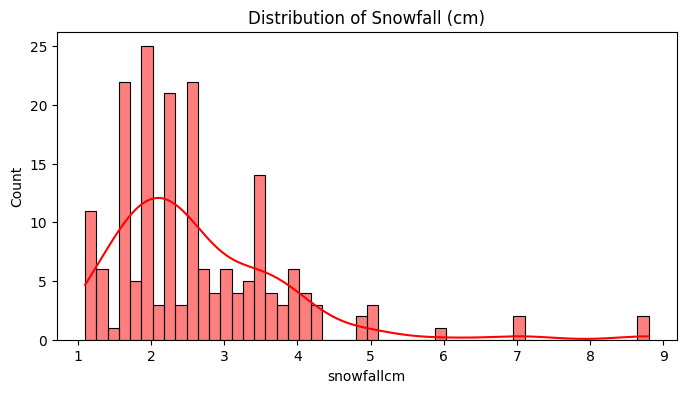

Доля снежных дней: 5.69 %


In [ ]:
def plot_data_distribution(data, column, color, bins=50, title=None):
    if column == 'rainfallmm':
        rain_plot = plt.figure(figsize=(8, 4))
        sns.histplot(data[column].loc[data[column] > 1], kde=True, bins=50, color='r')
        plt.title('Distribution of Rainfall (mm)')
        plt.show()
        print(f"Доля дней с дождем: {(data[column].loc[data[column] > 1].sum() / len(data[column]) * 100).round(2)} %")

    elif column == 'snowfallcm':
        snow_plot = plt.figure(figsize=(8, 4))
        sns.histplot(data[column].loc[data[column] > 1], kde=True, bins=50, color='r')
        plt.title('Distribution of Snowfall (cm)')
        plt.show()
        print(f"Доля снежных дней: {(data[column].loc[data[column] > 1].sum() / len(data[column]) * 100).round(2)} %")

    else:
        distr_plot = plt.figure(figsize=(8, 4))
        sns.histplot(data[column], kde=True, bins=bins, color=color)
        plt.title(f'Distribution of {column}' if title is None else title)
        plt.show()

    return None

def plot_rented_bike_count(data):
    plt.figure(figsize=(12, 6))

    # Динамика по сезонам
    plt.subplot(1, 2, 1)
    sns.lineplot(x=data['hour'], y=data['rented_bikecount'], hue=data['seasons'], marker="x", markeredgecolor="black")
    plt.title('Dynamics by Season')
    plt.xlabel('Hour of the Day')
    plt.ylabel('Rented Bike Count')

    # Аренда по часам в течение недели
    plt.subplot(1, 2, 2)
    sns.barplot(x=data['hour'], y=data['rented_bikecount'], hue=data['holiday'])
    plt.title('Bike Rental Count Across Different Hours of the Day')
    plt.xlabel('Hour of the Day')
    plt.ylabel('Rented Bike Count')

    plt.tight_layout()
    plt.show()

    plot_data_distribution(data, 'rented_bikecount', 'b', title='Распределение количества арендованных велосипедов')
    plot_data_distribution(data, 'solar_radiationmjm2', 'y', title='Распределение солнечной радиации (МДж/м2)')
    plot_data_distribution(data, 'dew_pointtemperaturec', 'g', title='Распределение температуры точки росы (°C)')
    plot_data_distribution(data, 'humidity', 'g', bins=30, title='Распределение влажности (%)')
    plot_data_distribution(data, 'rainfallmm', 'g', bins=30)
    plot_data_distribution(data, 'snowfallcm', 'g', bins=30)

    return None

plot_rented_bike_count(data)

interval columns not set, guessing: ['rented_bikecount', 'hour', 'temperaturec', 'humidity', 'wind_speedms', 'visibility10m', 'dew_pointtemperaturec', 'solar_radiationmjm2', 'rainfallmm', 'snowfallcm']
Функции 'date' и 'holiday' сильно коррелируют со значением phik корреляции 1.00
Функции 'date' и 'seasons' сильно коррелируют со значением phik корреляции 1.00
Функции 'date' и 'functioningday' сильно коррелируют со значением phik корреляции 1.00
Функции 'date' и 'dew_pointtemperaturec' сильно коррелируют со значением phik корреляции 0.97
Функции 'date' и 'temperaturec' сильно коррелируют со значением phik корреляции 0.94
Функции 'temperaturec' и 'dew_pointtemperaturec' сильно коррелируют со значением phik корреляции 0.89
Функции 'date' и 'snowfallcm' сильно коррелируют со значением phik корреляции 0.84
Функции 'date' и 'visibility10m' сильно коррелируют со значением phik корреляции 0.81
Функции 'temperaturec' и 'seasons' сильно коррелируют со значением phik корреляции 0.81
Функции 'date

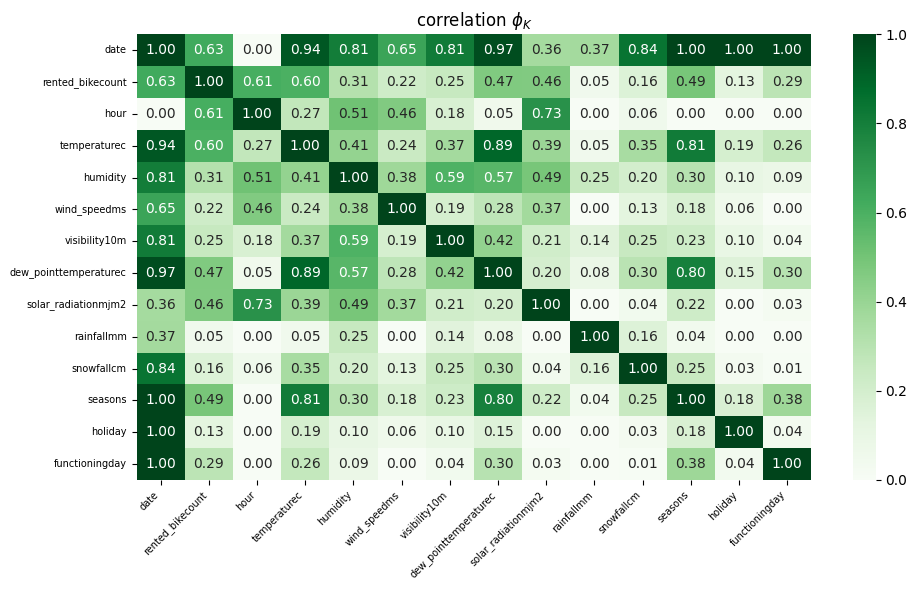

In [ ]:
!pip install phik
from phik import phik_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# Рассчитаем матрицу корреляции phik
phik_overview = phik_matrix(data)

# Функция для построения корреляционной матрицы и отображения статистики
def plot_correlation_matrix(correlation_matrix, x_labels, y_labels, vmin, vmax, color_map, title, fontsize_factor, figsize):
    plt.figure(figsize=figsize)
    sns.heatmap(correlation_matrix, annot=True, fmt=".2f", cmap=color_map, vmin=vmin, vmax=vmax)
    plt.title(title)
    plt.xticks(np.arange(len(x_labels)) + 0.5, x_labels, rotation=45, ha='right', fontsize=int(fontsize_factor * 10))
    plt.yticks(np.arange(len(y_labels)) + 0.5, y_labels, rotation=0, fontsize=int(fontsize_factor * 10))
    plt.tight_layout()

    # Отображение статистики для наиболее коррелирующих признаков
    most_correlated = find_most_correlated(correlation_matrix, threshold=0.8)  # Регулируем порог по мере необходимости
    display_statistics(data, most_correlated)

def find_most_correlated(correlation_matrix, threshold):
    # Нахадим индексы сильно коррелирующих пар
    indices = np.where(np.abs(correlation_matrix) > threshold)
    pairs = list(zip(indices[0], indices[1]))

    # Отфильтруем диагональ и дубликаты
    unique_pairs = set(tuple(sorted(pair)) for pair in pairs if pair[0] != pair[1])

    # Возвращаем наиболее коррелирующие пары
    return sorted(unique_pairs, key=lambda x: correlation_matrix[x[0], x[1]], reverse=True)

def display_statistics(data, most_correlated):
    for pair in most_correlated:
        feature1, feature2 = data.columns[pair[0]], data.columns[pair[1]]
        correlation_value = phik_overview.iloc[pair[0], pair[1]]
        print(f"Функции '{feature1}' и '{feature2}' сильно коррелируют со значением phik корреляции {correlation_value:.2f}")

# Построим матрицу корреляции phik и отобразите статистику
plot_correlation_matrix(phik_overview.values,
                        x_labels=phik_overview.columns,
                        y_labels=phik_overview.index,
                        vmin=0, vmax=1, color_map="Greens",
                        title=r"correlation $\phi_K$",
                        fontsize_factor=0.7,
                        figsize=(10, 6))
plt.tight_layout()
plt.show()

***Предварительные выводы по EDA:***

1. Количество велосипедов, сданных в аренду является целевым показателем. На графике видно, что распределение сильно скошено вправо, есть выбросы в районе 3000
2. В подавляющем количестве дней солнечная активность была равно нулю, и лишь в некоторые дни оно было значимым. При активном солнце также наблюдается тенденция брать велосипеды реже.
3. Распределение температуры точки росы выглядит примерно нормальным.
4. Распределение влажности говорит о том, клиентов больше, когда влажность находится в средних значениях. Смущает наличие показателей влажности 0: нужно их рассмотреть внимательнее.
5. Во время дождя, снегопада велосипеды арендуют реже. Их также реже арендуют при температуре менее 10 и более 35 градусов (это верно и в отношении утренней температуры).
7. В будние дни есть пики в 7-8 утра и 17-19 вечера. Скорее всего, люди берут велосипед до/после работы. В выходные данных пиков не наблюдается. И, в целом, в выходные дни меньше велосипедов берут в аренду.
8. Линейный график иллюстрирует изменение количества взятых напрокат велосипедов в разные часы дня с четкими закономерностями для каждого сезона. Динамика по сезонам схожая, за исключением зимы, когда велосипеды арендуют реже и оба пика более сглажены.
Ожидаемо, в осенние и летние месяцы велосипеды берут чаще.

В целом эти визуализации дают представление о распределении и закономерностях в наборе данных. Дальнейший анализ будет включать изучение корреляций, выявление выбросов и изучение дополнительных переменных, чтобы получить полное представление о данных о прокате велосипедов.

# Предобработка данных

In [ ]:
data.head()

,date,rented_bikecount,hour,temperaturec,humidity,wind_speedms,visibility10m,dew_pointtemperaturec,solar_radiationmjm2,rainfallmm,snowfallcm,seasons,holiday,functioningday
0,01/12/2017,254,0,-5.2,37,2.2,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes
1,01/12/2017,204,1,-5.5,38,0.8,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes
2,01/12/2017,173,2,-6.0,39,1.0,2000,-17.7,0.0,0.0,0.0,Winter,No Holiday,Yes
3,01/12/2017,107,3,-6.2,40,0.9,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes
4,01/12/2017,78,4,-6.0,36,2.3,2000,-18.6,0.0,0.0,0.0,Winter,No Holiday,Yes


Предварительный анализ графиков позволил установить, что в дни, когда сервис не работал, не было арендовано ни одного байка, поэтому можно смело удалить строки, когда сервис не работал, а после и сам столбец 'functioning_day', как создающий шум в данных:

In [ ]:
# Шаг 1: Удаление строк, когда сервис не работал
data = data[data['functioningday'] == 'Yes']

# Шаг 2: Удаление столбца "functioningday"
data = data.drop(columns=['functioningday'])

# Вывод информации о датасете после удалений
print("Количество строк и столбцов после удалений:", data.shape)
print("\nПример первых 5 строк после удалений:")
print(data.head())

Количество строк и столбцов после удалений: (8465, 13)

Пример первых 5 строк после удалений:
         date  rented_bikecount  hour  temperaturec  humidity  wind_speedms  \
0  01/12/2017               254     0          -5.2        37           2.2   
1  01/12/2017               204     1          -5.5        38           0.8   
2  01/12/2017               173     2          -6.0        39           1.0   
3  01/12/2017               107     3          -6.2        40           0.9   
4  01/12/2017                78     4          -6.0        36           2.3   

   visibility10m  dew_pointtemperaturec  solar_radiationmjm2  rainfallmm  \
0           2000                  -17.6                  0.0         0.0   
1           2000                  -17.6                  0.0         0.0   
2           2000                  -17.7                  0.0         0.0   
3           2000                  -17.6                  0.0         0.0   
4           2000                  -18.6            

Приведем признак даты из формата "object" в формат "datetime"

In [ ]:
# Преобразование столбца "date" из формата "object" в формат "datetime"
data['date'] = pd.to_datetime(data['date'], dayfirst=True)

Для возможности разностороннего изучения и построения моделей на разных данных создадим копию датафрейма.

In [ ]:
# Создание копии датасета
data_copy = data.copy()

In [ ]:
# Добавление нового столбца "часть суток"
bins = [0, 6, 12, 18, 24]  # Определяем границы для группировки: ночь, утро, день, вечер
labels = ['night', 'morning', 'day', 'evening']
data_copy['part_of_day'] = pd.cut(data_copy['hour'], bins=bins, labels=labels, right=False)

# Вывод информации о новом датасете
print("Количество строк и столбцов в новом датасете:", data_copy.shape)
print("\nПример первых 5 строк нового датасета:")
print(data_copy.head())

# Добавление столбцев "Month" и "WeekDay"
data_copy['Month'] = data_copy['date'].dt.month
data_copy['WeekDay'] = data_copy['date'].dt.day_name()

# Добавление закодированного столбца "WeekDayEncoding"
map_day = {'Monday': 1, 'Tuesday': 2, 'Wednesday': 3, 'Thursday': 4, 'Friday': 5, 'Saturday': 6, 'Sunday': 7}
data_copy['WeekDayEncoding'] = data_copy['WeekDay'].map(map_day)

# Удаление неактуальных столбцов 'date' и 'hour'
data_copy = data_copy.drop(['date', 'WeekDay'], axis=1)

# Вывод информации о новом датасете
print("Количество строк и столбцов в новом датасете:", data_copy.shape)
print("\nПример первых 5 строк нового датасета:")
print(data_copy.head())

Количество строк и столбцов в новом датасете: (8465, 14)

Пример первых 5 строк нового датасета:
        date  rented_bikecount  hour  temperaturec  humidity  wind_speedms  \
0 2017-12-01               254     0          -5.2        37           2.2   
1 2017-12-01               204     1          -5.5        38           0.8   
2 2017-12-01               173     2          -6.0        39           1.0   
3 2017-12-01               107     3          -6.2        40           0.9   
4 2017-12-01                78     4          -6.0        36           2.3   

   visibility10m  dew_pointtemperaturec  solar_radiationmjm2  rainfallmm  \
0           2000                  -17.6                  0.0         0.0   
1           2000                  -17.6                  0.0         0.0   
2           2000                  -17.7                  0.0         0.0   
3           2000                  -17.6                  0.0         0.0   
4           2000                  -18.6               

In [ ]:
# Приведение названий столбцов к нижнему регистру
data_copy.columns = data_copy.columns.str.lower()

# Вывод первых 5 строк с новыми названиями столбцов
data_copy.head()

,rented_bikecount,hour,temperaturec,humidity,wind_speedms,visibility10m,dew_pointtemperaturec,solar_radiationmjm2,rainfallmm,snowfallcm,seasons,holiday,part_of_day,month,weekdayencoding
0,254,0,-5.2,37,2.2,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,night,12,5
1,204,1,-5.5,38,0.8,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,night,12,5
2,173,2,-6.0,39,1.0,2000,-17.7,0.0,0.0,0.0,Winter,No Holiday,night,12,5
3,107,3,-6.2,40,0.9,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,night,12,5
4,78,4,-6.0,36,2.3,2000,-18.6,0.0,0.0,0.0,Winter,No Holiday,night,12,5


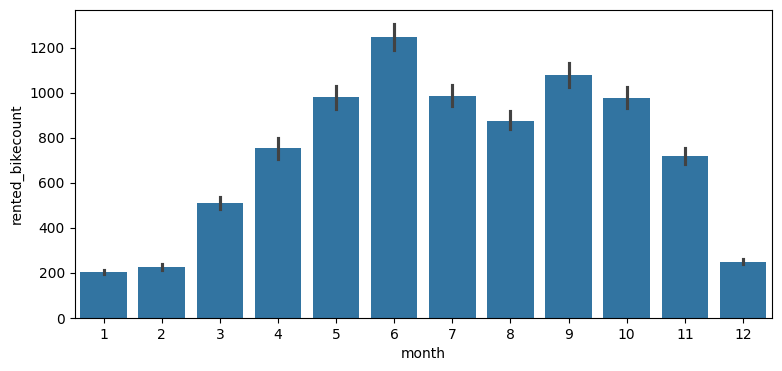

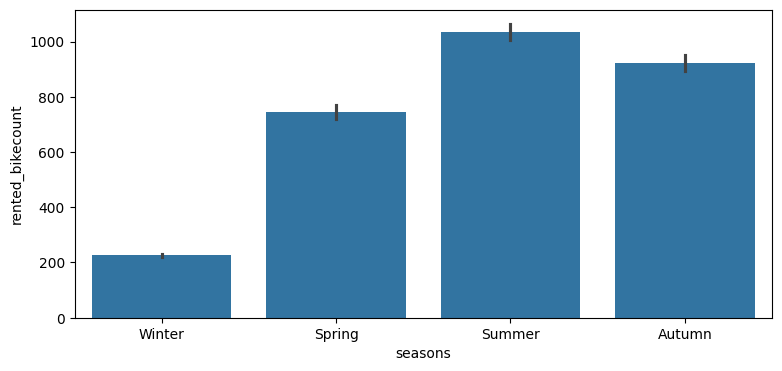

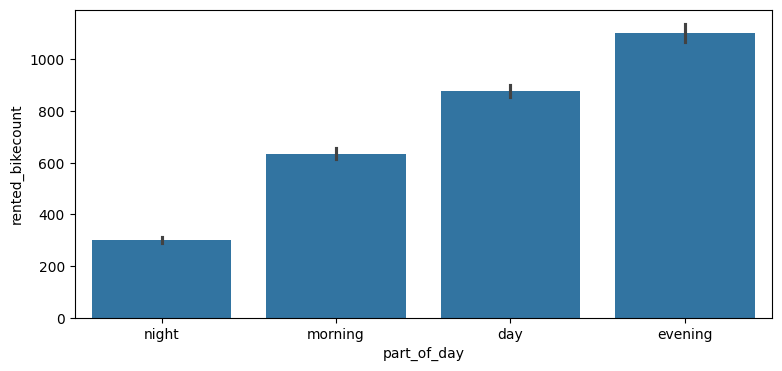

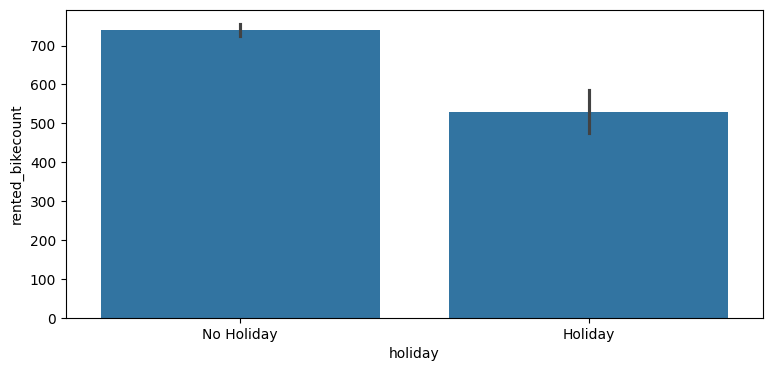

In [ ]:
# Функция для построения гистограмм
def plot_bar(data, x, y):
    plt.figure(figsize=(9,4))
    sns.barplot(x=x, y=y, data=data)
    plt.show()

# Построим гистограммы парами
plot_bar(data_copy, data_copy['month'], data_copy['rented_bikecount'])
plot_bar(data_copy, data_copy['seasons'], data_copy['rented_bikecount'])
plot_bar(data_copy, data_copy['part_of_day'], data_copy['rented_bikecount'])
plot_bar(data_copy, data_copy['holiday'], data_copy['rented_bikecount'])

В лидерах июнь и сентябрь. Реже всего арендуют в зимние месяцы. Также наиболее активно арендуют летом и осенью. Активнее арендуют днем и вечером.

Обработаем ранее вызвавший признак влажности равный нулю, ведь такого абсолютного показателя влажности нет. Поэтому делаем вывод, что это некорректные данные.

In [ ]:
# Рассчитаем среднее значение влажности, исключая 0 значений
humidity_mean = np.mean(data[data['humidity'] != 0]['humidity'])

# Заменим 0 значения средним значением'humidity' средним значением
data.loc[data['humidity'] == 0, 'humidity'] = humidity_mean

# Кодировка признаков

Изначально было неясно, как обрабатывать т.н. циклические признаки (идентификаторы дня, месяца, часа). Если использовать OneHot-кодирование для этих признаков, то размерность набора данных значительно увеличивается. Однако если просто записать признак в одну колонку, то возникают неверные соотношения размерности (например, 23 и 0 часов, 12 и 1 месяц). Мне удалось найти решение предложенное на сайте https://www.avanwyk.com/encoding-cyclical-features-for-deep-learning/. В нем предлагается кодировать такие признаки в виде двух столбцов - sin и cos.

In [ ]:
data_copy['hour_sin'] = np.sin(2 * np.pi * data_copy['hour']/24.0)
data_copy['hour_cos'] = np.cos(2 * np.pi * data_copy['hour']/24.0)

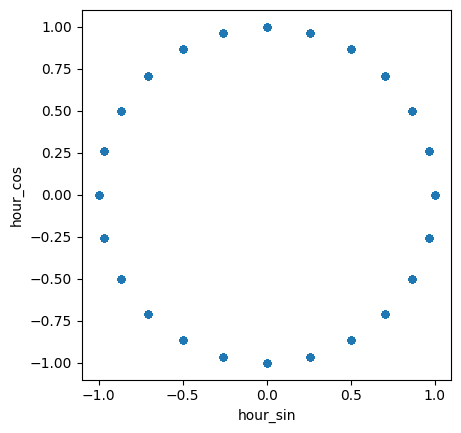

In [ ]:
ax = data_copy.plot.scatter('hour_sin', 'hour_cos').set_aspect('equal')

In [ ]:
data_copy['day_sin'] = np.sin(2 * np.pi * data_copy['weekdayencoding']/7)
data_copy['day_cos'] = np.cos(2 * np.pi * data_copy['weekdayencoding']/7)

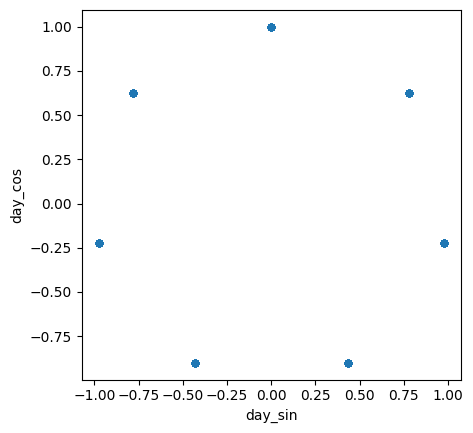

In [ ]:
ax = data_copy.plot.scatter('day_sin', 'day_cos').set_aspect('equal')

In [ ]:
data_copy.drop(columns=['month', 'weekdayencoding', 'hour'],inplace=True)
data_copy.head(3)

,rented_bikecount,temperaturec,humidity,wind_speedms,visibility10m,dew_pointtemperaturec,solar_radiationmjm2,rainfallmm,snowfallcm,seasons,holiday,part_of_day,hour_sin,hour_cos,day_sin,day_cos
0,254,-5.2,37,2.2,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,night,0.000000,1.000000,-0.974928,-0.222521
1,204,-5.5,38,0.8,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,night,0.258819,0.965926,-0.974928,-0.222521
2,173,-6.0,39,1.0,2000,-17.7,0.0,0.0,0.0,Winter,No Holiday,night,0.500000,0.866025,-0.974928,-0.222521


In [ ]:
# Выполняем горячее кодирование 'seasons', 'holiday', 'part_of_day' с использованием оригинальных имен столбцов в качестве префикса
data_copy = pd.get_dummies(data_copy, columns=['seasons', 'holiday', 'part_of_day'], drop_first=True, prefix=None, prefix_sep='_')
data_copy.shape

(8465, 20)

In [ ]:
# Заменяем 'seasons', 'holiday', 'part_of_day' в названиях столбцов
data_copy.columns = data_copy.columns.str.replace('seasons_', '').str.replace('holiday_', '').str.replace('part_of_day_', '')

In [ ]:
# Приведение названий столбцов к нижнему регистру
data_copy.columns = data_copy.columns.str.lower()

# Вывод первых 5 строк с новыми названиями столбцов
data_copy.head()

,rented_bikecount,temperaturec,humidity,wind_speedms,visibility10m,dew_pointtemperaturec,solar_radiationmjm2,rainfallmm,snowfallcm,hour_sin,hour_cos,day_sin,day_cos,spring,summer,winter,no holiday,morning,day,evening
0,254,-5.2,37,2.2,2000,-17.6,0.0,0.0,0.0,0.000000,1.000000,-0.974928,-0.222521,0,0,1,1,0,0,0
1,204,-5.5,38,0.8,2000,-17.6,0.0,0.0,0.0,0.258819,0.965926,-0.974928,-0.222521,0,0,1,1,0,0,0
2,173,-6.0,39,1.0,2000,-17.7,0.0,0.0,0.0,0.500000,0.866025,-0.974928,-0.222521,0,0,1,1,0,0,0
3,107,-6.2,40,0.9,2000,-17.6,0.0,0.0,0.0,0.707107,0.707107,-0.974928,-0.222521,0,0,1,1,0,0,0
4,78,-6.0,36,2.3,2000,-18.6,0.0,0.0,0.0,0.866025,0.500000,-0.974928,-0.222521,0,0,1,1,0,0,0


In [ ]:
! pip install phik

/usr/local/lib/python3.10/dist-packages/phik/data_quality.py:59: UserWarning: The number of unique values of variable rented_bikecount is large: 2165. Are you sure this is not an interval variable? Analysis for pairs of variables including rented_bikecount can be slow.
  warnings.warn(
/usr/local/lib/python3.10/dist-packages/phik/data_quality.py:59: UserWarning: The number of unique values of variable rented_bikecount is large: 2165. Are you sure this is not an interval variable? Analysis for pairs of variables including rented_bikecount can be slow.
  warnings.warn(
/usr/local/lib/python3.10/dist-packages/phik/data_quality.py:59: UserWarning: The number of unique values of variable rented_bikecount is large: 2165. Are you sure this is not an interval variable? Analysis for pairs of variables including rented_bikecount can be slow.
  warnings.warn(
/usr/local/lib/python3.10/dist-packages/phik/data_quality.py:59: UserWarning: The number of unique values of variable rented_bikecount is l

Таблица корреляции с целевой переменной 'rented_bikecount':


,Column,Pearson,Spearman,Kendall,Phik
0,temperaturec,0.562740,0.611726,0.428539,0.528120
4,dew_pointtemperaturec,0.400263,0.410788,0.279408,0.000000
18,evening,0.334977,0.267866,0.218798,0.508252
13,summer,0.282001,0.294521,0.240571,0.504399
5,solar_radiationmjm2,0.273862,0.409508,0.293117,0.733622
3,visibility10m,0.212323,0.198904,0.138523,0.000000
17,day,0.133092,0.196435,0.160452,0.388957
2,wind_speedms,0.125022,0.154984,0.105914,0.000000
15,no holiday,0.070070,0.088731,0.072477,0.000000
12,spring,0.015580,0.026975,0.022033,0.188488


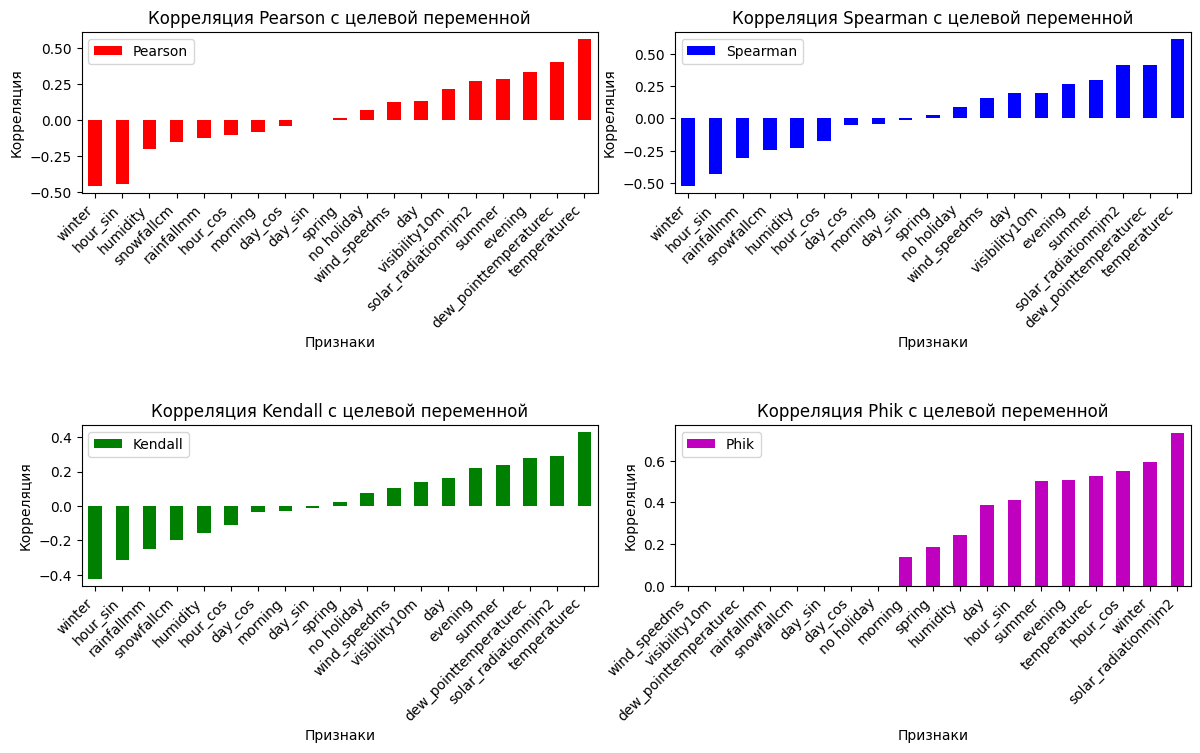


Два самых высоко коррелируемых признака с целевой переменной 'rented_bikecount':
['temperaturec', 'winter']


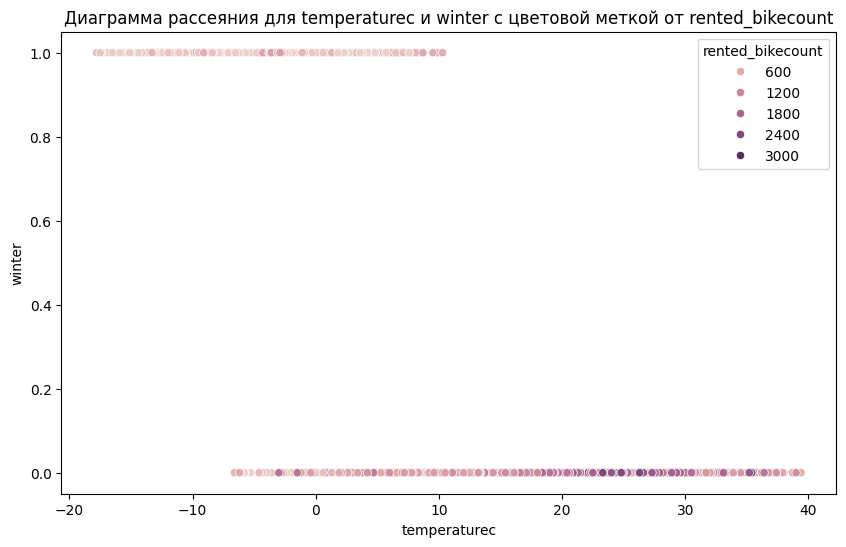

In [ ]:
from scipy import stats
from phik import phik_matrix  # Убедитесь, что у вас установлена библиотека phik

def correlation_analysis(data_copy, target_column_name, sort_method='Pearson', apply_abs=False):
    """
    Функция для анализа корреляции различных типов (Pearson, Spearman, Kendall, Phi_k) с целевой переменной.

    Параметры:
    - data: pd.DataFrame, датафрейм с данными.
    - target_column_name: str, название целевой переменной.
    - sort_method: str, тип корреляции, по которому осуществляется сортировка (по умолчанию 'Pearson').
    - apply_abs: bool, если True, выводит значения корреляции по модулю (по умолчанию False).

    Возвращает:
    - None, выводит таблицу корреляций, графики и другую информацию.
    """
    # Инициализация целевой переменной
    target_column = data_copy[target_column_name]
    sort_method = sort_method.title()

    # Список для хранения корреляций
    correlation_data = []

    # Список колонок для использования в phik
    interval_cols = [col for col in data_copy.columns if col != target_column_name]

    # Рассчет корреляций
    for column in data_copy.columns:
        if column != target_column_name:
            pearson_corr = stats.pearsonr(target_column, data_copy[column])[0]
            spearman_corr = stats.spearmanr(target_column, data_copy[column]).correlation
            kendall_corr = stats.kendalltau(target_column, data_copy[column]).correlation
            phik_corr = phik_matrix(data_copy, interval_cols=interval_cols)[target_column_name][column]

            # Применение модуля
            if apply_abs:
                pearson_corr = abs(pearson_corr)
                spearman_corr = abs(spearman_corr)
                kendall_corr = abs(kendall_corr)

            # Добавление значений корреляционных коэффициентов различных типов в список
            correlation_data.append((column, pearson_corr, spearman_corr, kendall_corr, phik_corr))

    # Создание датафрейма с корреляциями
    correlation_df = pd.DataFrame(correlation_data, columns=['Column', 'Pearson', 'Spearman', 'Kendall', 'Phik'])
    correlation_df_sorted = correlation_df.sort_values(by=sort_method, ascending=False)

    # Вывод таблицы корреляций
    print(f"Таблица корреляции с целевой переменной '{target_column_name}':")
    display(correlation_df_sorted)

    # Графики корреляций
    fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(12, 8))
    for i, (corr_method, ax) in enumerate(zip(['Pearson', 'Spearman', 'Kendall', 'Phik'], axes.flatten()), start=2):
        corr_with_target = correlation_df.sort_values(by=corr_method)
        corr_with_target.plot(x='Column', y=corr_method, kind='bar', ax=ax, color=['r', 'b', 'g', 'm'][i-2])
        ax.set_xlabel('Признаки')
        ax.set_ylabel('Корреляция')
        ax.set_title(f'Корреляция {corr_method} с целевой переменной')
    fig.tight_layout(pad=1)

    for ax in axes.flat:
        ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right')

    plt.show()

    # Топ 2 признака с самой высокой корреляцией
    top_correlation = correlation_df.set_index('Column')
    sorted_columns = top_correlation[sort_method].abs().sort_values(ascending=False)
    top_columns_names = sorted_columns.index[:2].tolist()

    # Выводим информацию о двух самых высоких коррелирующих признаках
    print(f"\nДва самых высоко коррелируемых признака с целевой переменной '{target_column_name}':")
    print(top_columns_names)

    # Диаграмма рассеяния для двух признаков с высокой корреляцией
    scatter_plot_columns = top_columns_names[:2]
    plt.figure(figsize=(10, 6))
    sns.scatterplot(x=data_copy[scatter_plot_columns[0]], y=data_copy[scatter_plot_columns[1]], hue=data_copy['rented_bikecount'])
    plt.title(f"Диаграмма рассеяния для {scatter_plot_columns[0]} и {scatter_plot_columns[1]} с цветовой меткой от {'rented_bikecount'}")
    plt.show()

# Пример использования функции
correlation_analysis(data_copy, 'rented_bikecount', sort_method='Pearson', apply_abs=False)

In [ ]:
def find_multicollinearity(data_copy, sort_method='pearson', threshold=0.9):
    """
    Функция находит мультиколлинеарные признаки в датафрейме.

    Параметры:
    - data_copy: pd.DataFrame, датафрейм с данными.
    - sort_method: str, метод сортировки корреляционной матрицы ('pearson', 'kendall', 'spearman').
    - threshold: float, порог для определения мультиколлинеарности (по умолчанию 0.9).

    Возвращает:
    - str, описание метода корреляции.
    - list, пары признаков, являющихся мультиколлинеарными.
    """
    # Приведение метода сортировки к нижнему регистру
    sort_method = sort_method.lower()

    # Расчет корреляционной матрицы в зависимости от выбранного метода
    if sort_method in ['pearson', 'kendall', 'spearman']:
        corr_matrix = data_copy.corr(method=sort_method).abs()
    else:
        interval_cols = [col for col in data_copy.columns]
        corr_matrix = phik_matrix(data_copy, interval_cols=interval_cols)

    multicollinear_features = []

    # Поиск мультиколлинеарных признаков
    n = corr_matrix.shape[0]
    for i in range(n):
        for j in range(i+1, n):
            if corr_matrix.iloc[i, j] > threshold:
                feature1 = corr_matrix.columns[i]
                feature2 = corr_matrix.columns[j]
                multicollinear_features.append((feature1, feature2))

    return f"КОРРЕЛЯЦИЯ {sort_method.upper()}", multicollinear_features

# Пример использования функции
correlation_method, multicollinear_features = find_multicollinearity(data_copy, sort_method='pearson', threshold=0.9)
print(correlation_method)
print(multicollinear_features)
correlation_method, multicollinear_features = find_multicollinearity(data_copy, sort_method='kendall', threshold=0.9)
print(correlation_method)
print(multicollinear_features)
correlation_method, multicollinear_features = find_multicollinearity(data_copy, sort_method='spearman', threshold=0.9)
print(correlation_method)
print(multicollinear_features)

КОРРЕЛЯЦИЯ PEARSON
[('temperaturec', 'dew_pointtemperaturec')]
КОРРЕЛЯЦИЯ KENDALL
[]
КОРРЕЛЯЦИЯ SPEARMAN
[('temperaturec', 'dew_pointtemperaturec')]


Выбросы в столбце 'rented_bikecount':
Количество выбросов: 152
Процент выбросов от общего количества наблюдений: 1.80%
Значения выбросов: 2401, 2402, 2401, 2404, 2692, 2807, 2574, 2577, 2558, 2661, 2392, 3130, 2405, 2701, 2410, 2906, 2915, 2479, 2439, 2403, 3069, 2450, 3123, 2454, 2825, 2916, 3245, 2656, 3251, 2650, 3119, 2534, 3088, 2505, 2514, 2460, 3380, 2788, 2508, 3227, 2615, 2404, 3221, 2649, 3309, 2797, 2476, 2431, 2495, 3404, 2873, 2579, 2505, 2474, 2664, 2479, 2404, 2962, 2460, 2891, 2984, 2441, 2451, 2475, 2497, 2435, 2474, 2481, 2429, 2515, 2430, 3556, 2809, 2525, 2440, 3384, 2741, 2519, 3418, 2811, 2556, 2436, 3365, 2732, 2493, 3238, 2779, 2456, 3172, 2487, 3113, 2602, 2965, 2598, 2398, 3080, 2637, 2415, 2594, 3196, 2557, 2931, 3016, 2884, 2636, 2770, 2692, 2640, 2419, 2405, 2416, 2481, 2797, 2628, 2830, 2528, 2836, 3166, 2491, 3160, 2468, 2497, 3154, 3298, 2518, 3222, 2455, 2391, 3256, 2443, 3146, 2826, 3277, 2489, 3154, 2422, 2432, 2397, 2857, 2400, 2787, 2514, 2618, 2635

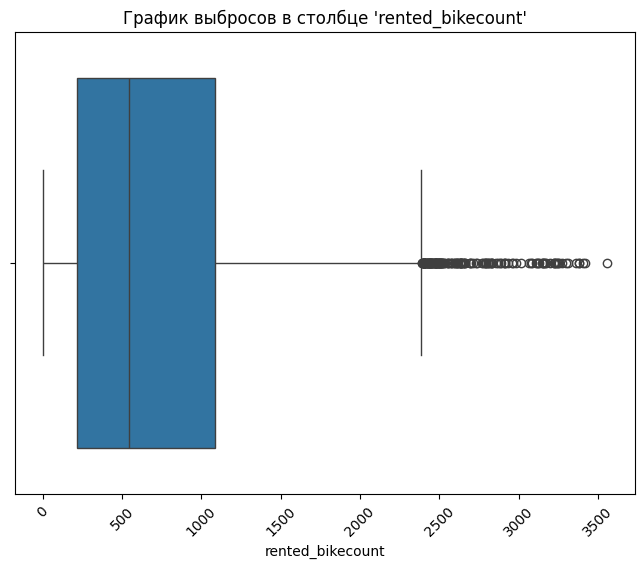

***************************************************************************

В столбце 'temperaturec' нет выбросов.
***************************************************************************

В столбце 'humidity' нет выбросов.
***************************************************************************

Выбросы в столбце 'wind_speedms':
Количество выбросов: 154
Процент выбросов от общего количества наблюдений: 1.82%
Значения выбросов: 4.5, 4.8, 5.4, 4.5, 5.8, 4.7, 5.3, 4.5, 4.5, 4.7, 5.1, 4.5, 4.6, 5.1, 4.5, 5.0, 4.4, 4.9, 4.7, 5.0, 4.7, 4.5, 4.4, 6.7, 4.6, 4.6, 5.0, 4.4, 4.5, 4.6, 4.5, 4.5, 4.7, 5.3, 4.8, 4.5, 4.5, 4.6, 6.0, 4.7, 5.2, 4.6, 4.5, 4.5, 4.8, 4.6, 4.6, 4.4, 4.8, 4.9, 4.7, 4.6, 4.4, 4.5, 4.4, 4.7, 4.5, 4.9, 5.0, 5.6, 5.1, 5.8, 4.4, 4.5, 4.4, 5.3, 4.6, 4.4, 5.0, 4.9, 5.3, 4.6, 4.7, 6.0, 4.5, 4.8, 5.2, 4.7, 4.7, 4.7, 4.5, 4.4, 4.6, 4.4, 5.3, 4.6, 4.9, 4.9, 4.9, 4.8, 4.5, 4.7, 5.0, 4.7, 5.3, 4.6, 5.1, 7.4, 4.8, 5.8, 5.6, 7.2, 5.8, 6.1, 7.3, 5.4, 4.6, 5.1, 4.9, 4.8, 4.4, 4.7, 4

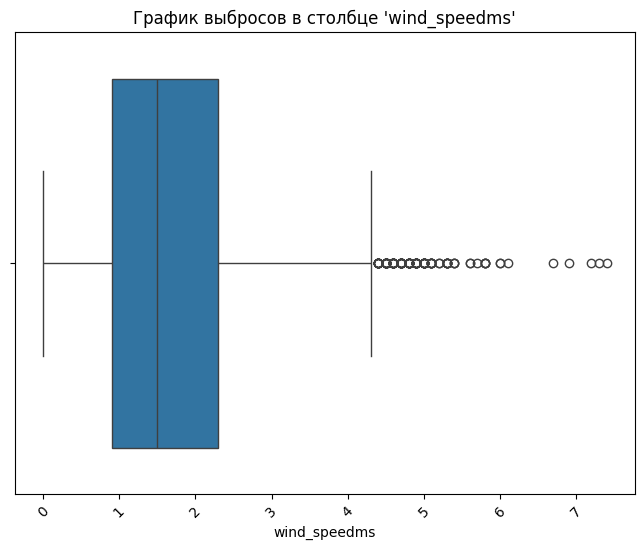

***************************************************************************

В столбце 'visibility10m' нет выбросов.
***************************************************************************

В столбце 'dew_pointtemperaturec' нет выбросов.
***************************************************************************

Выбросы в столбце 'solar_radiationmjm2':
Количество выбросов: 620
Процент выбросов от общего количества наблюдений: 7.32%
Значения выбросов: 2.35, 2.46, 2.39, 2.49, 2.36, 2.5, 2.52, 2.35, 2.48, 2.43, 2.49, 2.95, 2.86, 2.54, 2.61, 2.83, 2.74, 2.48, 2.56, 2.75, 2.66, 2.33, 2.46, 2.45, 2.55, 2.65, 2.47, 2.66, 2.53, 2.47, 2.67, 2.69, 2.34, 2.44, 2.6, 2.43, 2.66, 2.49, 2.38, 2.78, 2.99, 2.91, 2.62, 2.51, 2.52, 2.36, 2.59, 2.33, 2.7, 2.91, 2.82, 2.51, 2.72, 2.87, 2.71, 2.41, 2.48, 2.42, 2.63, 2.75, 2.62, 2.65, 2.8, 2.7, 2.44, 2.54, 2.37, 2.73, 2.87, 2.75, 2.4, 2.41, 2.53, 2.57, 2.83, 3.24, 3.04, 2.79, 2.98, 2.99, 2.49, 2.93, 3.06, 2.99, 2.6, 2.59, 2.94, 2.77, 2.68, 3.07, 3.2, 3.

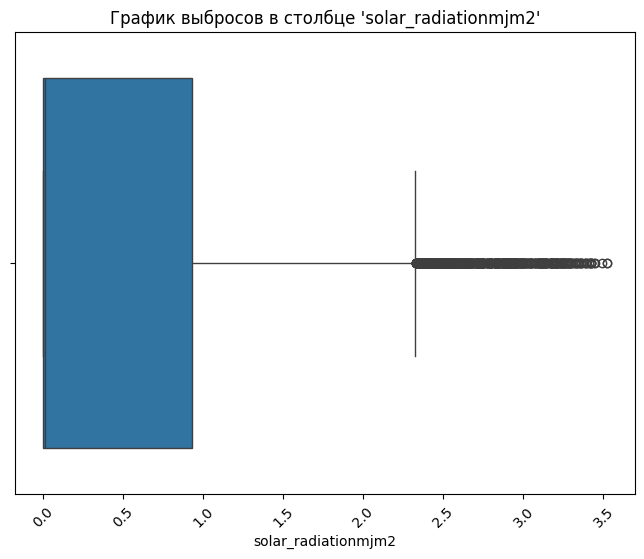

***************************************************************************

Выбросы в столбце 'rainfallmm':
Количество выбросов: 516
Процент выбросов от общего количества наблюдений: 6.10%
Значения выбросов: 0.5, 1.0, 2.5, 0.1, 0.1, 0.2, 0.3, 0.7, 2.5, 1.6, 0.3, 0.4, 1.6, 1.1, 0.1, 0.1, 0.1, 6.4, 9.5, 3.5, 0.5, 0.3, 0.2, 0.2, 1.0, 0.9, 0.5, 0.3, 0.2, 0.2, 0.2, 3.3, 1.4, 1.5, 0.1, 0.4, 0.4, 3.7, 4.5, 9.5, 9.0, 2.0, 0.1, 0.4, 0.1, 0.2, 0.2, 2.0, 9.0, 1.5, 2.0, 0.5, 2.0, 1.5, 0.5, 8.0, 17.0, 2.0, 0.5, 0.3, 0.2, 0.5, 0.5, 0.5, 0.1, 3.5, 7.0, 3.0, 3.0, 2.0, 0.1, 0.4, 1.5, 2.0, 0.5, 0.5, 1.0, 1.0, 1.5, 1.0, 0.5, 0.5, 0.5, 1.5, 2.0, 2.0, 0.5, 0.1, 0.1, 0.1, 1.9, 1.0, 0.5, 1.5, 3.0, 0.2, 0.8, 1.0, 2.0, 1.0, 1.5, 1.5, 0.5, 0.5, 0.3, 0.2, 1.0, 0.5, 0.5, 1.5, 2.5, 4.0, 3.0, 2.0, 0.1, 0.9, 0.5, 3.5, 2.5, 7.0, 6.0, 5.0, 8.0, 4.0, 1.5, 5.5, 2.5, 4.0, 1.5, 1.0, 0.5, 1.0, 1.5, 1.0, 1.5, 0.1, 2.4, 0.5, 0.4, 0.1, 1.0, 3.5, 4.0, 0.5, 0.5, 1.0, 1.0, 0.1, 0.4, 0.5, 0.5, 1.5, 1.5, 2.0, 3.0, 2.5, 2.0, 1.0, 

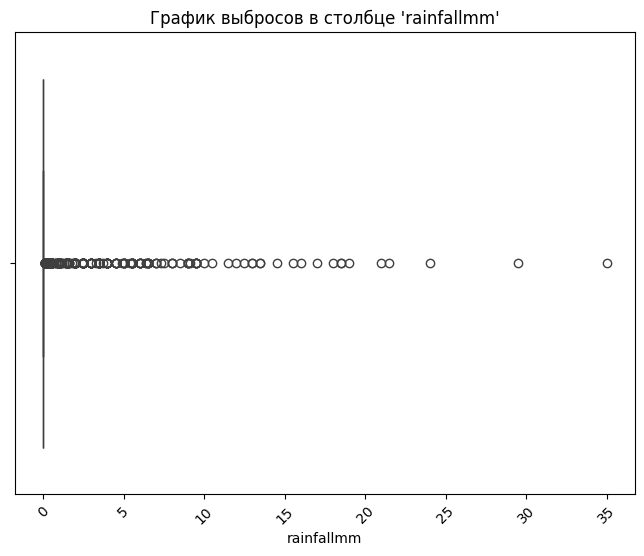

***************************************************************************

Выбросы в столбце 'snowfallcm':
Количество выбросов: 443
Процент выбросов от общего количества наблюдений: 5.23%
Значения выбросов: 0.1, 0.3, 0.4, 0.4, 0.4, 0.4, 0.4, 0.3, 0.2, 0.2, 0.2, 0.3, 1.0, 1.0, 1.0, 1.0, 1.0, 0.9, 0.9, 0.9, 0.9, 0.9, 0.9, 0.9, 0.9, 0.8, 0.8, 0.7, 0.6, 0.3, 0.7, 2.7, 4.0, 4.1, 4.3, 4.3, 3.9, 3.1, 2.1, 1.4, 1.0, 0.5, 0.4, 0.2, 0.5, 0.7, 0.8, 1.3, 1.8, 2.0, 4.0, 4.8, 4.8, 5.1, 5.0, 4.2, 3.2, 2.7, 2.7, 2.7, 2.7, 2.7, 2.6, 2.6, 2.6, 2.6, 2.6, 2.6, 2.6, 2.6, 2.6, 2.6, 2.6, 2.5, 2.5, 2.5, 2.5, 2.3, 2.2, 2.2, 2.1, 2.0, 2.0, 2.0, 2.0, 2.0, 2.0, 2.0, 2.0, 2.0, 2.0, 2.0, 2.0, 2.0, 2.0, 2.0, 2.0, 2.0, 2.0, 2.0, 1.9, 1.9, 1.7, 1.7, 1.6, 1.6, 2.2, 2.2, 2.2, 2.4, 2.4, 2.3, 2.2, 2.2, 2.2, 2.2, 2.2, 2.2, 2.2, 2.2, 2.2, 2.2, 2.2, 2.1, 2.0, 1.9, 1.8, 1.6, 1.0, 0.9, 0.8, 0.8, 0.8, 0.8, 0.8, 0.8, 0.8, 0.8, 0.8, 0.8, 0.7, 0.7, 0.7, 0.7, 0.7, 0.7, 0.6, 0.5, 0.2, 0.6, 1.2, 1.2, 1.2, 1.2, 1.2, 1.2, 1.2, 1.2, 1

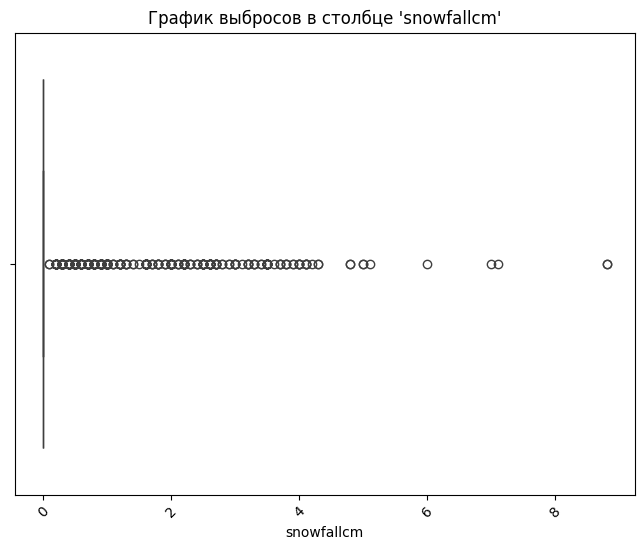

***************************************************************************

В столбце 'hour_sin' нет выбросов.
***************************************************************************

В столбце 'hour_cos' нет выбросов.
***************************************************************************

В столбце 'day_sin' нет выбросов.
***************************************************************************

В столбце 'day_cos' нет выбросов.
***************************************************************************

В столбце 'spring' нет выбросов, так как он имеет бинарные значения.
***************************************************************************

В столбце 'summer' нет выбросов, так как он имеет бинарные значения.
***************************************************************************

В столбце 'winter' нет выбросов, так как он имеет бинарные значения.
***************************************************************************

В столбце 'no holiday' нет выбросов, та

,Столбец,Количество выбросов,Процент выбросов
0,rented_bikecount,152,1.795629
1,temperaturec,0,0.0
2,humidity,0,0.0
3,wind_speedms,154,1.819256
4,visibility10m,0,0.0
5,dew_pointtemperaturec,0,0.0
6,solar_radiationmjm2,620,7.324276
7,rainfallmm,516,6.095688
8,snowfallcm,443,5.233314
9,hour_sin,0,0.0


In [ ]:
# Добавление библиотеки для работы с выбросами
from scipy.stats import zscore

def detect_outliers(data_copy):
    outlier_table = pd.DataFrame(columns=['Столбец', 'Количество выбросов', 'Процент выбросов'])

    for column in data_copy.columns:
        if data_copy[column].dtype != 'object' and len(data_copy[column].unique()) == 2:
            print(f"В столбце '{column}' нет выбросов, так как он имеет бинарные значения.")
            outlier_table = pd.concat([outlier_table, pd.DataFrame({'Столбец': [column],
                                                                    'Количество выбросов': ['NaN'],
                                                                    'Процент выбросов': ['NaN']})],ignore_index=True)
            print('*' * 75)
            print()
            continue

        q1 = data_copy[column].quantile(0.25)
        q3 = data_copy[column].quantile(0.75)
        iqr = q3 - q1
        lower_bound = q1 - 1.5 * iqr
        upper_bound = q3 + 1.5 * iqr

        outliers = data_copy[(data_copy[column] < lower_bound) | (data_copy[column] > upper_bound)]
        num_outliers = len(outliers)
        column_len = len(data_copy[column])

        if num_outliers == 0:
            print(f"В столбце '{column}' нет выбросов.")
            outlier_table = pd.concat([outlier_table, pd.DataFrame({'Столбец': [column],
                                                                    'Количество выбросов': [0],
                                                                    'Процент выбросов': [0]})], ignore_index=True)
        else:
            print(f"Выбросы в столбце '{column}':")
            print(f"Количество выбросов: {num_outliers}")
            print(f"Процент выбросов от общего количества наблюдений: {(num_outliers / column_len) * 100:.2f}%")
            print("Значения выбросов:", ", ".join(outliers[column].astype(str)))

            outlier_table = pd.concat([outlier_table, pd.DataFrame({'Столбец': [column],
                                                                    'Количество выбросов': [num_outliers],
                                                                    'Процент выбросов': [(num_outliers / column_len) * 100]})], ignore_index=True)

            # Построение графика с отображением выбросов
            fig, ax = plt.subplots(figsize=(8, 6))
            sns.boxplot(data=data_copy, x=column, ax=ax)
            ax.set_title(f"График выбросов в столбце '{column}'")
            ax.tick_params(axis='x', rotation=45)  # Вращение меток оси x
            plt.show()

        print('*' * 75)
        print()

    display(outlier_table)

# Пример использования функции
detect_outliers(data_copy)

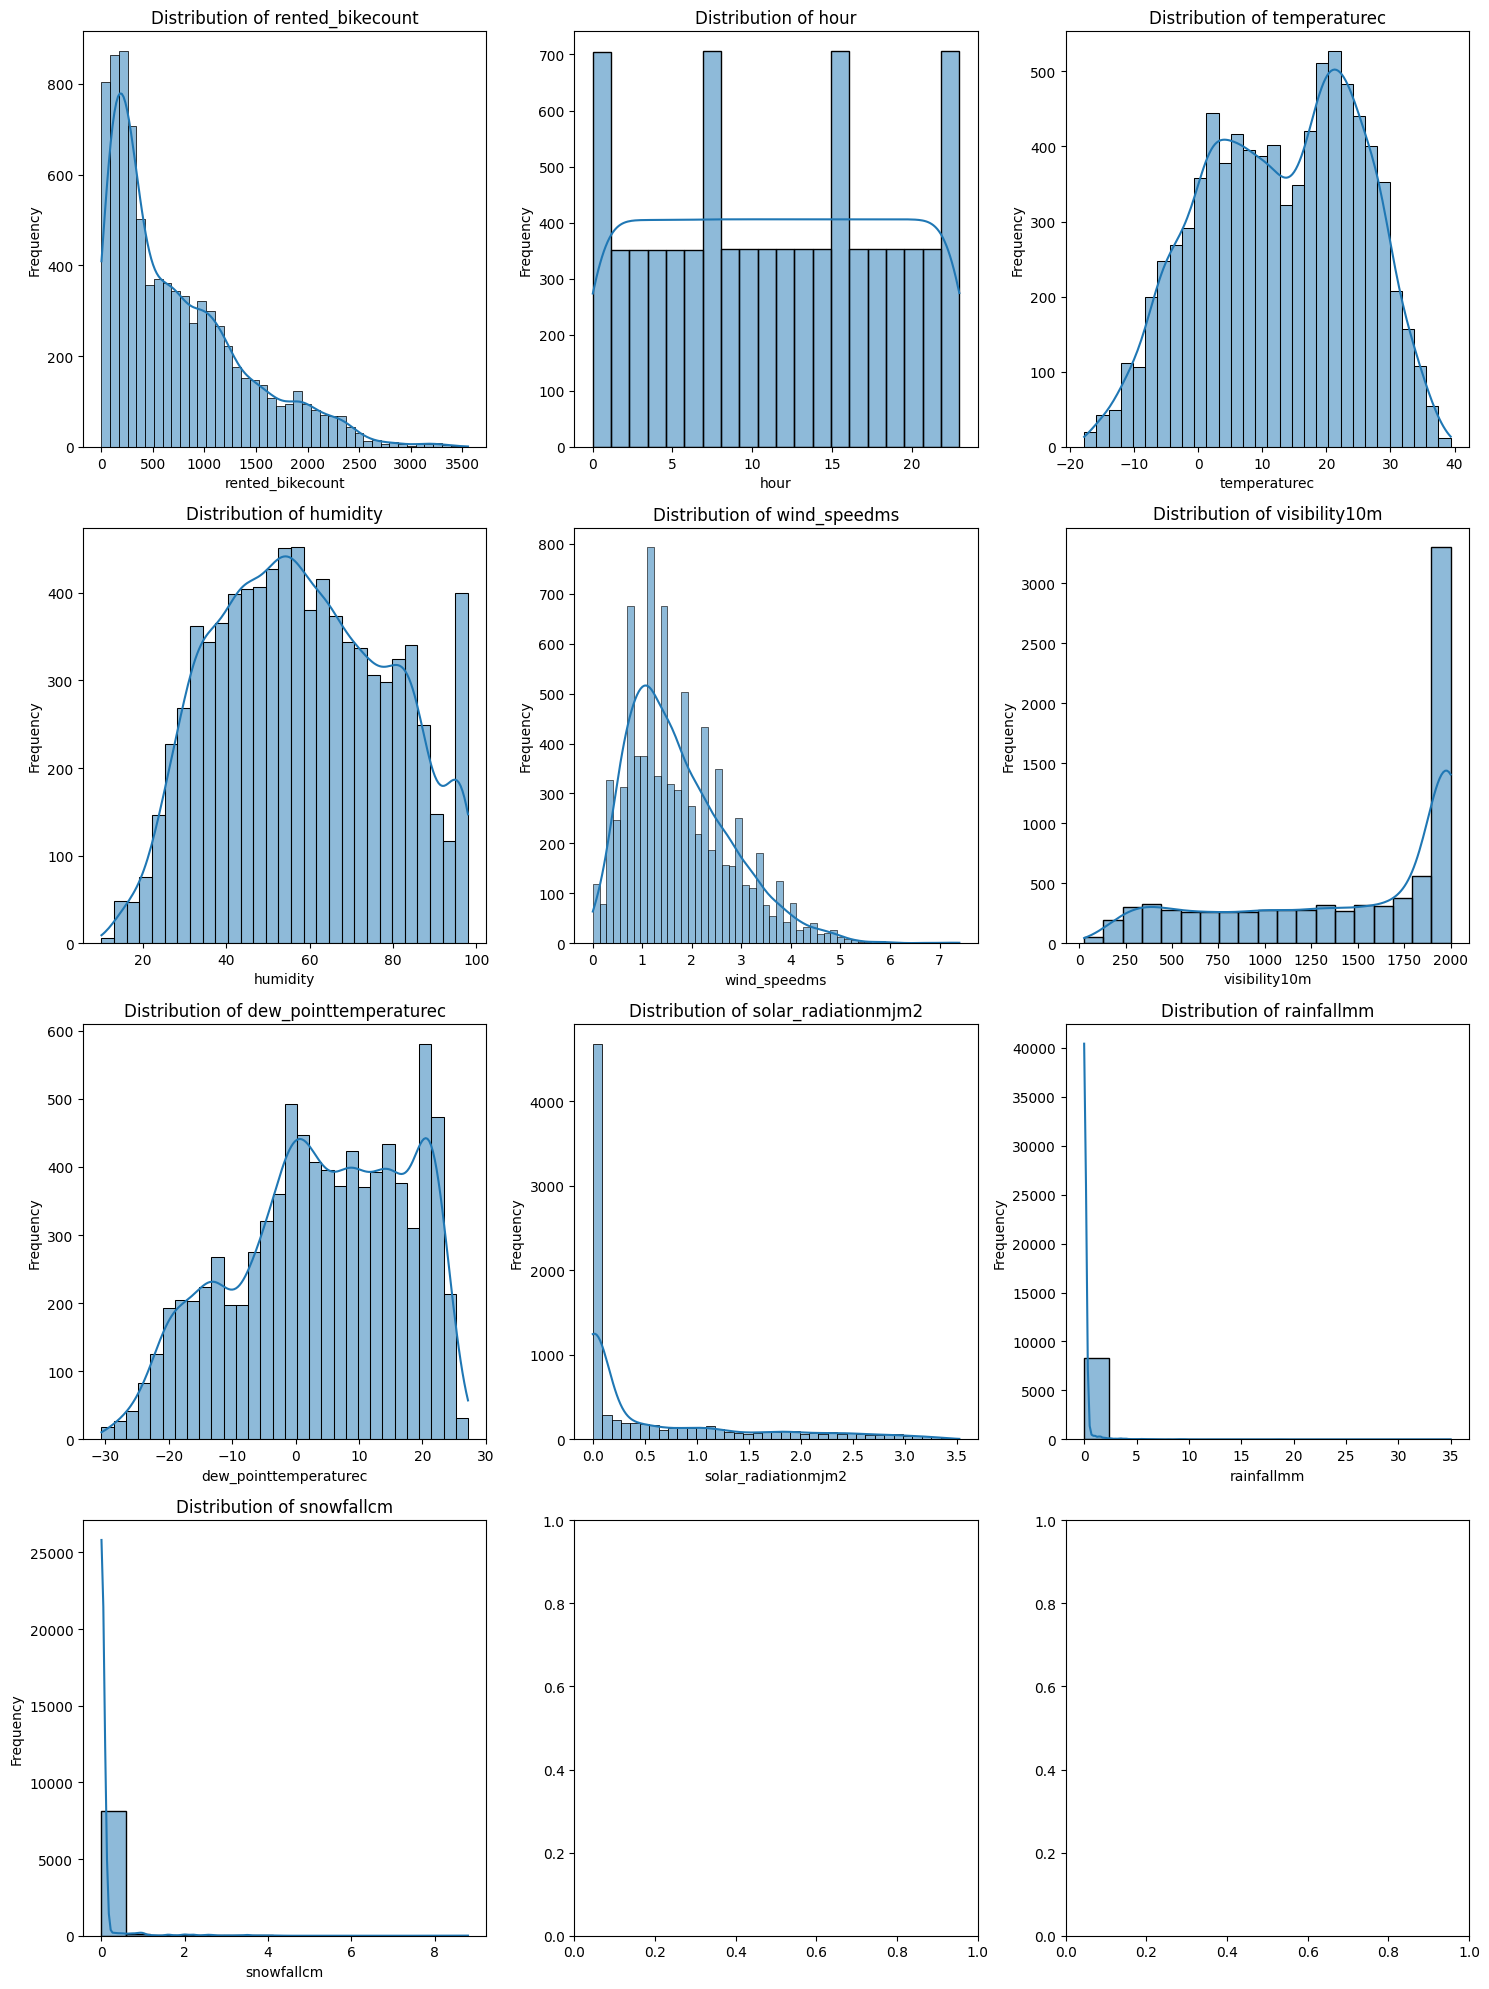

In [ ]:
def visualize_distribution(data_copy):
    # Определение числовых признаков
    numerical_columns = data.select_dtypes(include=[np.number]).columns

    # Создание сетки графиков
    num_plots = len(numerical_columns)
    num_cols = 3  # количество столбцов в сетке
    num_rows = (num_plots // num_cols) + (num_plots % num_cols)  # вычисление количества строк

    # Размер сетки
    fig, axes = plt.subplots(num_rows, num_cols, figsize=(15, 5 * num_rows))

    # Проход по числовым признакам и отрисовка гистограмм
    for i, column in enumerate(numerical_columns):
        ax = axes[i // num_cols, i % num_cols] if num_rows > 1 else axes[i % num_cols]
        sns.histplot(data[column], kde=True, ax=ax)
        ax.set_title(f'Distribution of {column}')
        ax.set_xlabel(column)
        ax.set_ylabel('Frequency')

    # Размещение графиков в сетке
    plt.tight_layout()
    plt.show()

# Использование функции для визуализации распределения данных
visualize_distribution(data_copy)

Для рассчета корреляций Спирмена, Пирсона, Кендалла и Фай-квадрат (Phik) используем библиотеку phik:

t-test results for temperaturec: t-statistic=-5.3425230682663765, p-value=9.404533940213426e-08
Spearman correlation results for temperaturec: correlation=0.6117257587949343, p-value=0.0
Kendall correlation results for temperaturec: correlation=0.42853853933289815, p-value=0.0
t-test results for humidity: t-statistic=-4.401969418192554, p-value=1.085891737664584e-05
Spearman correlation results for humidity: correlation=-0.22647715358174608, p-value=6.589127226686243e-99
Kendall correlation results for humidity: correlation=-0.15545963368224988, p-value=1.1788377666573306e-100
t-test results for wind_speedms: t-statistic=2.893044545657676, p-value=0.0038250050611716045
Spearman correlation results for wind_speedms: correlation=0.15498422020590294, p-value=1.1610689795786036e-46
Kendall correlation results for wind_speedms: correlation=0.10591373269714435, p-value=5.653691475395265e-47
t-test results for visibility10m: t-statistic=2.0436614929113124, p-value=0.041017896260677394
Spearma

/usr/local/lib/python3.10/dist-packages/scipy/stats/_axis_nan_policy.py:523: RuntimeWarning: Precision loss occurred in moment calculation due to catastrophic cancellation. This occurs when the data are nearly identical. Results may be unreliable.
  res = hypotest_fun_out(*samples, **kwds)


Spearman correlation results for no holiday: correlation=0.08873103356971442, p-value=2.8700089821012516e-16
Kendall correlation results for no holiday: correlation=0.07247731990162809, p-value=3.261147956973883e-16
t-test results for morning: t-statistic=-0.004235336743505223, p-value=0.9966208001310043
Spearman correlation results for morning: correlation=-0.039308693162863055, p-value=0.0002974883428300217
Kendall correlation results for morning: correlation=-0.03210814316776065, p-value=0.0002987289097588001
t-test results for day: t-statistic=-0.0098808975038081, p-value=0.9921165456171972
Spearman correlation results for day: correlation=0.1964348021022223, p-value=2.128167526231484e-74
Kendall correlation results for day: correlation=0.16045195710010476, p-value=5.295690428919568e-73
t-test results for evening: t-statistic=-0.0098808975038081, p-value=0.9921165456171972
Spearman correlation results for evening: correlation=0.26786563923030315, p-value=4.785147304242428e-139
Kend

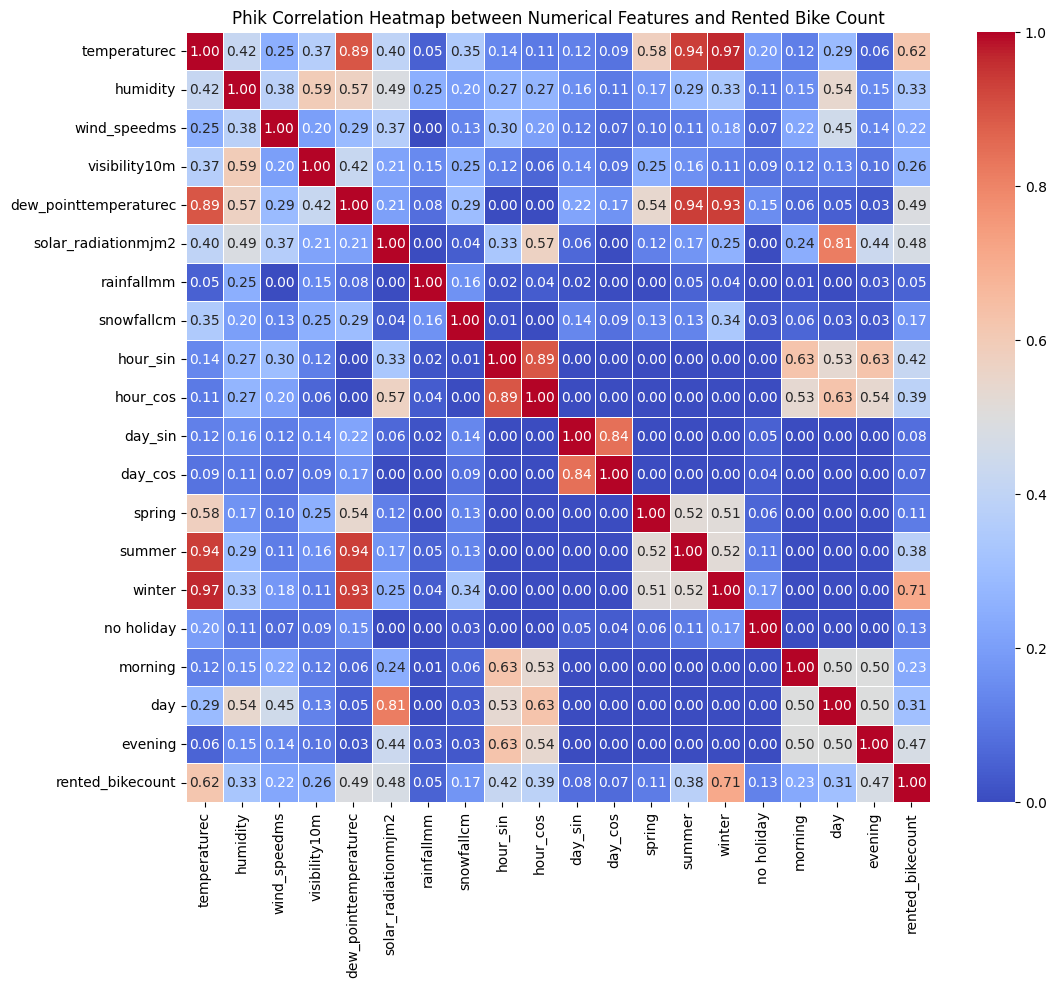

In [ ]:
from scipy.stats import ttest_ind, spearmanr, kendalltau
from phik import phik_matrix
import matplotlib.pyplot as plt
import seaborn as sns

# Проверка столбца на числовой тип данных и добавление в numerical_columns
numerical_columns = [column for column in data_copy.columns if pd.api.types.is_numeric_dtype(data_copy[column])]

# Фильтрация числовых признаков
numerical_columns_only = [column for column in numerical_columns if column != 'rented_bikecount']

for column in numerical_columns_only:
    # t-тест для двух групп (например, праздничные и непраздничные дни)
    t_statistic, t_p_value = ttest_ind(data_copy.loc[data_copy['no holiday'] == 0, column],
                                       data_copy.loc[data_copy['no holiday'] == 1, column])
    print(f"t-test results for {column}: t-statistic={t_statistic}, p-value={t_p_value}")

    # Корреляция Спирмена
    spearman_corr, spearman_p_value = spearmanr(data_copy[column], data_copy['rented_bikecount'])
    print(f"Spearman correlation results for {column}: correlation={spearman_corr}, p-value={spearman_p_value}")

    # Корреляция Кендалла
    kendall_corr, kendall_p_value = kendalltau(data_copy[column], data_copy['rented_bikecount'])
    print(f"Kendall correlation results for {column}: correlation={kendall_corr}, p-value={kendall_p_value}")

# Корреляция Phik
phik_corr_matrix = phik_matrix(data_copy[numerical_columns_only + ['rented_bikecount']])
plt.figure(figsize=(12, 10))
sns.heatmap(phik_corr_matrix, annot=True, cmap='coolwarm', fmt='.2f', linewidths=.5)
plt.title('Phik Correlation Heatmap between Numerical Features and Rented Bike Count')
plt.show()

В этом коде был использован `.loc` для индексации данных и проверку на пустоту с использованием `np.isnan`. Это поможет избежать проблем с `ValueError` при использовании условных выражений для DataFrame.

>>> Phik работает для категориальных переменных, поэтому может потребоваться преобразовать числовые признаки в категориальные, если это необходимо.

interval columns not set, guessing: ['temperaturec', 'humidity', 'wind_speedms', 'visibility10m', 'dew_pointtemperaturec', 'solar_radiationmjm2', 'rainfallmm', 'snowfallcm', 'hour_sin', 'hour_cos', 'day_sin', 'day_cos', 'spring', 'summer', 'winter', 'no holiday', 'morning', 'day', 'evening', 'rented_bikecount']
Feature with maximum Phik correlation: winter
Maximum Phik correlation value: 0.7095120450057615


<ipython-input-200-078e75776e04>:24: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=phik_corr_with_target.index, y=phik_corr_with_target.abs(), palette='viridis')


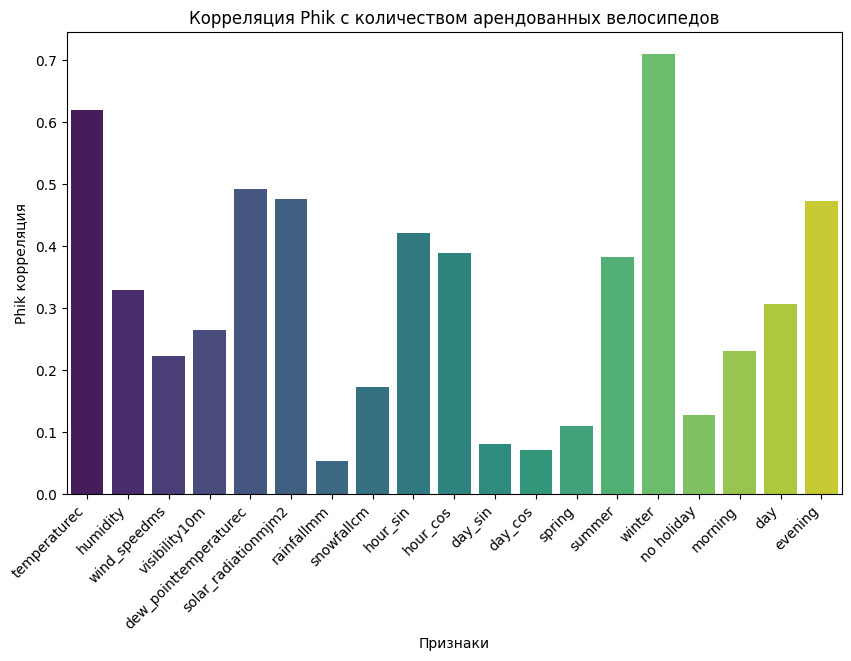

In [ ]:
from scipy.stats import ttest_ind, spearmanr, kendalltau
from phik import phik_matrix

# Проверка столбца на числовой тип данных и добавление в numerical_columns
numerical_columns = [column for column in data_copy.columns if pd.api.types.is_numeric_dtype(data_copy[column])]

# Фильтрация числовых признаков
numerical_columns_only = [column for column in numerical_columns if column != 'rented_bikecount']

# Рассчет корреляции Phik
phik_corr_matrix = phik_matrix(data_copy[numerical_columns_only + ['rented_bikecount']])
phik_corr_with_target = phik_corr_matrix['rented_bikecount'][:-1]  # исключаем целевую переменную

# Определение признака с наибольшей корреляцией Phik
max_corr_feature = phik_corr_with_target.abs().idxmax()
max_corr_value = phik_corr_with_target.abs().max()

# Вывод информации о признаке с наибольшей корреляцией Phik
print(f"Feature with maximum Phik correlation: {max_corr_feature}")
print(f"Maximum Phik correlation value: {max_corr_value}")

# Визуализация корреляции Phik
plt.figure(figsize=(10, 6))
sns.barplot(x=phik_corr_with_target.index, y=phik_corr_with_target.abs(), palette='viridis')
plt.title('Корреляция Phik с количеством арендованных велосипедов')
plt.xlabel('Признаки')
plt.ylabel('Phik корреляция')
plt.xticks(rotation=45, ha='right')
plt.show()

,level_0,level_1,pearson,kendall,spearman,phik
0,dew_pointtemperaturec,temperaturec,0.914467,0.740973,0.913720,0.892736
1,summer,temperaturec,0.677872,0.574780,0.703112,0.935591
2,dew_pointtemperaturec,summer,0.664183,0.575910,0.704503,0.936662
3,day,solar_radiationmjm2,0.625960,0.579133,0.657588,0.813252
4,hour_sin,morning,0.585311,0.500171,0.598289,0.626645
...,...,...,...,...,...,...
185,evening,hour_sin,-0.584775,-0.511569,-0.611923,0.626015
186,day,hour_cos,-0.584775,-0.505751,-0.604961,0.626015
187,hour_cos,solar_radiationmjm2,-0.704713,-0.688712,-0.855623,0.566836
188,dew_pointtemperaturec,winter,-0.723221,-0.565510,-0.691781,0.933646


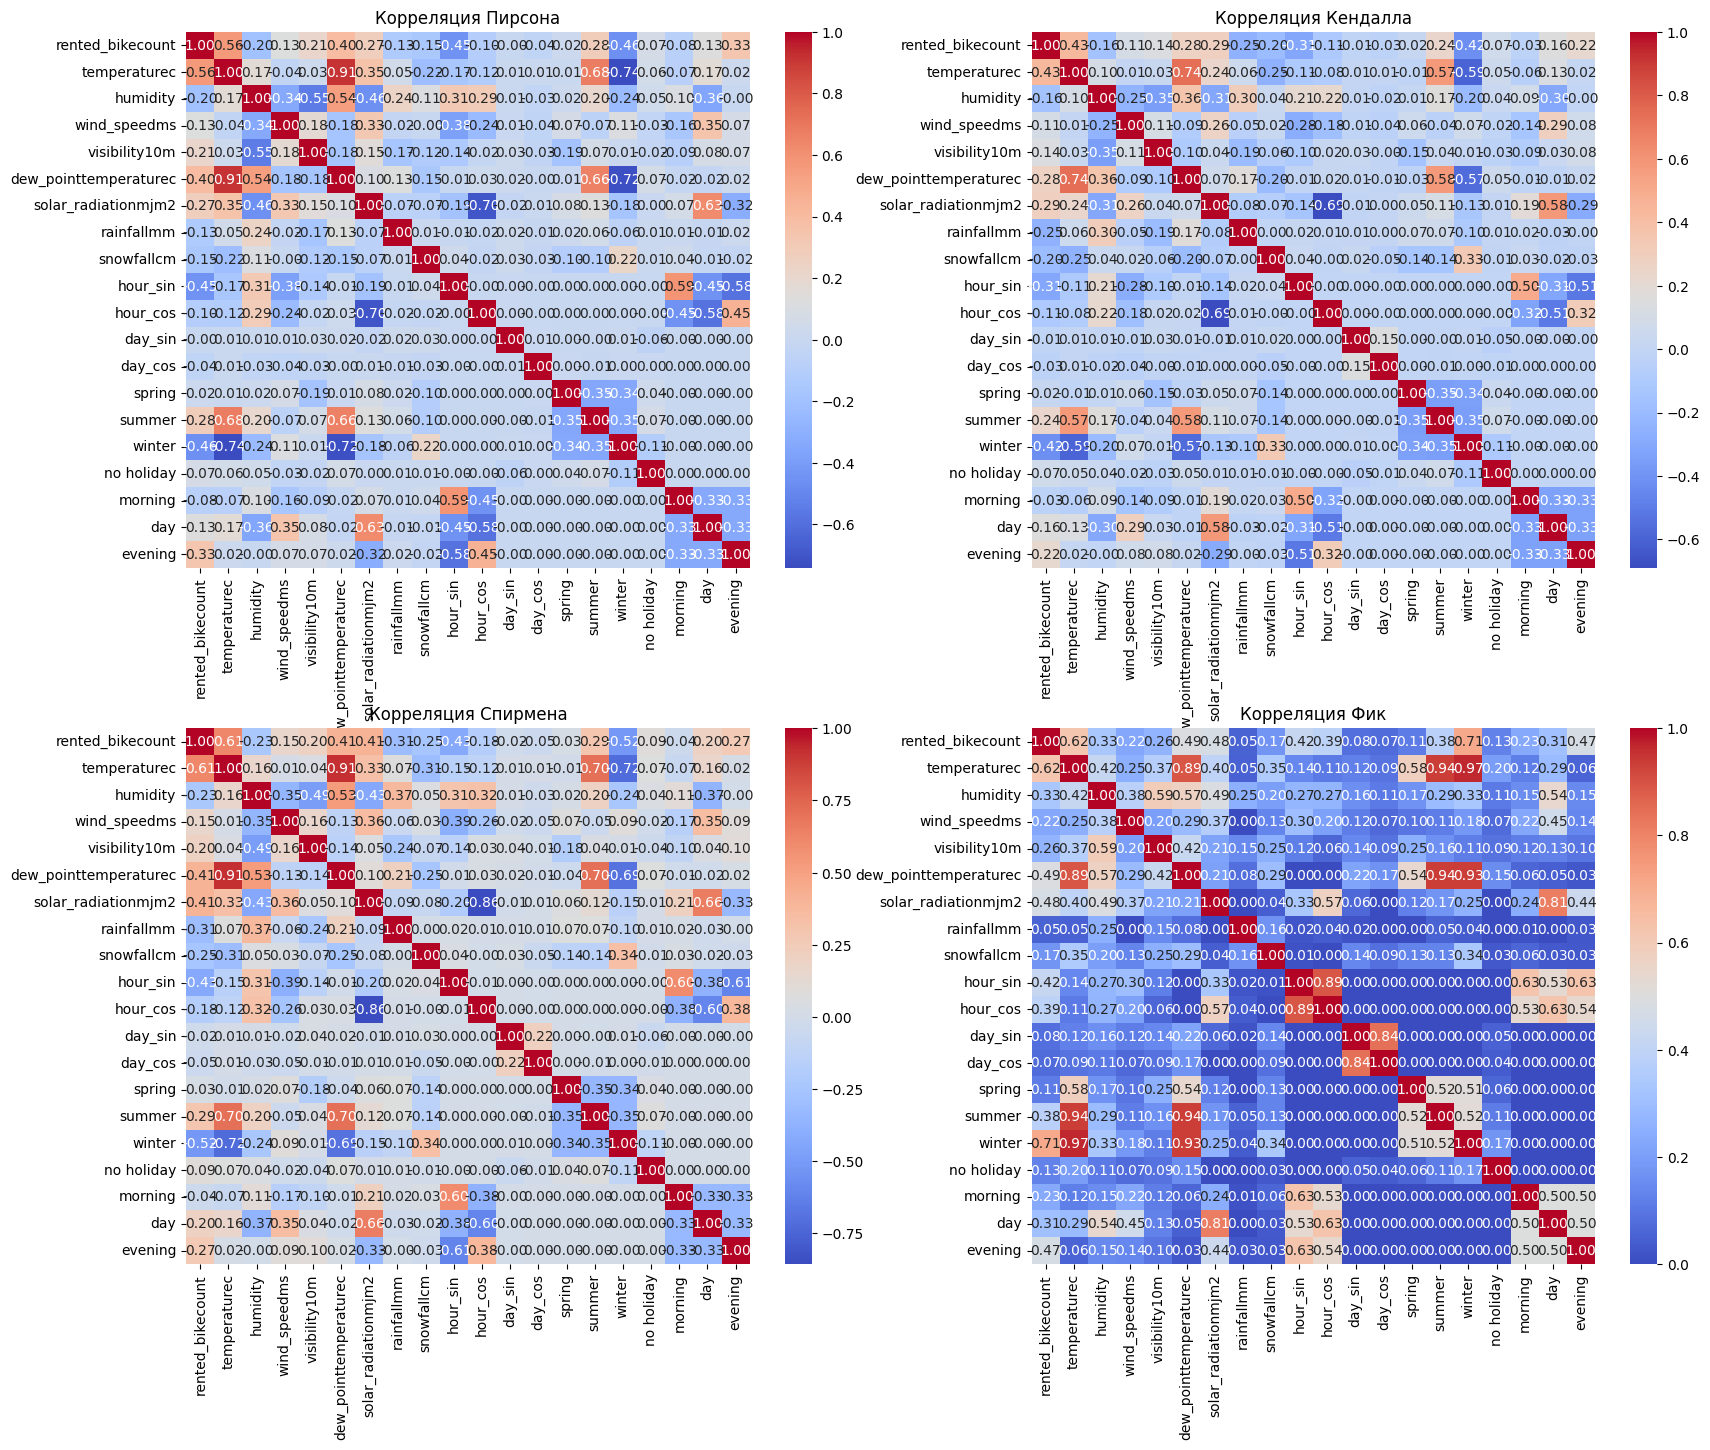

In [ ]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from phik import phik_matrix  # Make sure to import phik_matrix from the appropriate library

def correlation_data_full(data, sort_method='pearson', apply_abs=False):
    sort_method = sort_method.lower()

    # Вычисление корреляции
    if apply_abs:
        pearson_corr = abs(data.corr(method='pearson'))
        kendall_corr = abs(data.corr(method='kendall'))
        spearman_corr = abs(data.corr(method='spearman'))
    else:
        pearson_corr = data.corr(method='pearson')
        kendall_corr = data.corr(method='kendall')
        spearman_corr = data.corr(method='spearman')

    # Распаковка и объединение данных
    pearson_corr_unstack = pearson_corr.unstack().reset_index().rename(columns={0: 'pearson'})
    pearson_corr_unstack = pearson_corr_unstack[pearson_corr_unstack['level_0'] < pearson_corr_unstack['level_1']]  # удаление повторяющихся пар
    kendall_corr_unstack = kendall_corr.unstack().reset_index().rename(columns={0: 'kendall'})
    kendall_corr_unstack = kendall_corr_unstack[kendall_corr_unstack['level_0'] < kendall_corr_unstack['level_1']]  # удаление повторяющихся пар
    spearman_corr_unstack = spearman_corr.unstack().reset_index().rename(columns={0: 'spearman'})
    spearman_corr_unstack = spearman_corr_unstack[spearman_corr_unstack['level_0'] < spearman_corr_unstack['level_1']]  # удаление повторяющихся пар

    interval_cols = [col for col in data.columns]
    phik_corr = phik_matrix(data, interval_cols=interval_cols)
    phik_corr_unstack = phik_corr.unstack().reset_index().rename(columns={0: 'phik'})
    phik_corr_unstack = phik_corr_unstack[phik_corr_unstack['level_0'] < phik_corr_unstack['level_1']]  # удаление повторяющихся пар

    # Сортировка и объединение таблиц
    if sort_method == 'pearson':
        merged_table = pd.merge(pearson_corr_unstack.sort_values(by='pearson', ascending=False), kendall_corr_unstack, on=['level_0', 'level_1'])
        merged_table = pd.merge(merged_table, spearman_corr_unstack, on=['level_0', 'level_1'])
        merged_table = pd.merge(merged_table, phik_corr_unstack, on=['level_0', 'level_1'])
    elif sort_method == 'kendall':
        merged_table = pd.merge(kendall_corr_unstack.sort_values(by='kendall', ascending=False), spearman_corr_unstack, on=['level_0', 'level_1'])
        merged_table = pd.merge(merged_table, phik_corr_unstack, on=['level_0', 'level_1'])
        merged_table = pd.merge(merged_table, pearson_corr_unstack, on=['level_0', 'level_1'])
    elif sort_method == 'spearman':
        merged_table = pd.merge(spearman_corr_unstack.sort_values(by='spearman', ascending=False), kendall_corr_unstack, on=['level_0', 'level_1'])
        merged_table = pd.merge(merged_table, phik_corr_unstack, on=['level_0', 'level_1'])
        merged_table = pd.merge(merged_table, pearson_corr_unstack, on=['level_0', 'level_1'])
    elif sort_method == 'phik':
        merged_table = pd.merge(phik_corr_unstack.sort_values(by='phik', ascending=False), pearson_corr_unstack, on=['level_0', 'level_1'])
        merged_table = pd.merge(merged_table, kendall_corr_unstack, on=['level_0', 'level_1'])
        merged_table = pd.merge(merged_table, spearman_corr_unstack, on=['level_0', 'level_1'])

    display(merged_table)

    # Визуализация корреляционных матриц
    fig, ax = plt.subplots(2, 2, figsize=(20, 16))
    fig.subplots_adjust(hspace=0.3)

    # Корреляция Пирсона
    sns.heatmap(pearson_corr, annot=True, fmt=".2f", cmap='coolwarm', ax=ax[0, 0])
    ax[0, 0].set_title("Корреляция Пирсона")

    # Корреляция Кендалла
    sns.heatmap(kendall_corr, annot=True, fmt=".2f", cmap='coolwarm', ax=ax[0, 1])
    ax[0, 1].set_title("Корреляция Кендалла")

    # Корреляция Спирмена
    sns.heatmap(spearman_corr, annot=True, fmt=".2f", cmap='coolwarm', ax=ax[1, 0])
    ax[1, 0].set_title("Корреляция Спирмена")

    # Корреляция Фик
    sns.heatmap(phik_corr, annot=True, fmt=".2f", cmap='coolwarm', ax=ax[1, 1])
    ax[1, 1].set_title("Корреляция Фик")

    plt.show()

correlation_data_full(data_copy)

Для оценки мультиколлинеарности в данных можно использовать VIF (Variance Inflation Factor). VIF измеряет, насколько вариация коэффициента регрессии увеличивается из-за корреляции с другими предикторами. Большие значения VIF могут указывать на проблемы с мультиколлинеарностью.

Для оценки VIF, вам может потребоваться выполнить следующие шаги:

In [ ]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

# Выбор только числовых признаков для data_copy
numerical_columns_copy = [column for column in data_copy.columns if pd.api.types.is_numeric_dtype(data_copy[column])]
numerical_data_copy = data_copy[numerical_columns_copy]

# Рассчет VIF для каждого числового признака в data_copy
vif_data_copy = pd.DataFrame()
vif_data_copy["Variable"] = numerical_data_copy.columns
vif_data_copy["VIF"] = [variance_inflation_factor(numerical_data_copy.values, i) for i in range(numerical_data_copy.shape[1])]

# Вывод результатов для data_copy
print("VIF for data_copy:")
print(vif_data_copy)

VIF for data_copy:
                 Variable        VIF
0        rented_bikecount   5.608312
1            temperaturec  49.390538
2                humidity  24.602601
3            wind_speedms   5.250555
4           visibility10m  10.199067
5   dew_pointtemperaturec  30.483173
6     solar_radiationmjm2   5.332687
7              rainfallmm   1.142378
8              snowfallcm   1.151096
9                hour_sin   6.132313
10               hour_cos   6.883220
11                day_sin   1.010902
12                day_cos   1.018218
13                 spring   2.348882
14                 summer   3.693442
15                 winter   4.589892
16             no holiday  20.412617
17                morning   6.704922
18                    day  10.703379
19                evening   6.515561


VIF обычно считается для каждого числового признака по отдельности. Значения VIF выше 10 или 5 могут сигнализировать о мультиколлинеарности.

In [ ]:
# Пороговое значение для определения высокой мультиколлинеарности (можете изменить по необходимости)
vif_threshold = 10.0

# Выбор признаков с высокими значениями VIF
high_vif_features = vif_data_copy[vif_data_copy["VIF"] > vif_threshold]["Variable"].tolist()

# Вывод признаков с самыми высокими значениями VIF
print("\nFeatures with high multicollinearity (VIF > 10.0):")
print(high_vif_features)


Features with high multicollinearity (VIF > 10.0):
['temperaturec', 'humidity', 'visibility10m', 'dew_pointtemperaturec', 'no holiday', 'day']


Запомним эти признпаки и будем работать над улучшением моделей, начиная с их удаления.

У нас есть признаки с высокими значениями VIF (VIF > 10.0):
['temperaturec', 'humidity', 'visibility10m', 'dew_pointtemperaturec', 'no holiday', 'day'].

При первичной обработке данных были признаки с высокими значениями VIF следующие:

* temperaturec - 90.222112
* humidity      -         20.632588
* dew_point_temperaturec - 118.193139
* autumn -  98.038331
* spring - 108.408599
* summer - 114.105213
* winter - 104.658824

Это может потребовать дополнительного анализа. Мы рассмотрим не возможность удаления некоторых признаков, а использование методов регуляризации в моделях, чтобы справиться с мультиколлинеарностью.

# Бейзлайн модель регрессии

## Стандартизация данных и создание полиномиальных признаков

Поскольку задачей стоито предсказать число велосипедов, для этого используем модель линейно-линейной регрессии.

In [ ]:
# Импортируем все необзодимые библиотеки
from sklearn import preprocessing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, MinMaxScaler, OneHotEncoder, LabelEncoder, FunctionTransformer
from sklearn.linear_model import LinearRegression, Lasso, Ridge
from sklearn.metrics import r2_score, mean_squared_error
from sklearn.model_selection import cross_val_score
from hyperopt import fmin, tpe, hp, STATUS_OK, Trials
from hyperopt.pyll.base import scope
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.model_selection import GridSearchCV
from scipy.stats import norm, probplot
import time



Выделим зависимую переменную и независимые факторы для ее предсказания.

In [ ]:
# Укажем функции и целевую переменную
X = data_copy.drop('rented_bikecount', axis=1) # Функции (исключая целевой столбец)
y = data_copy['rented_bikecount'] # Целевая переменная

# Разделим данные на обучающий и проверочный наборы
X_train, X_valid, y_train, y_valid = train_test_split(X, y, test_size=0.2, random_state=42)

# Теперь у нас есть:
# X_train: Возможности для обучения
# X_valid: Функции для проверки
# y_train: целевая переменная для обучения
# y_valid: целевая переменная для проверки

Сначала приведем независимые переменных к нормальному распределению с помощью стандартизации.

Далее создадим полиномиальные признаки для построения полиномиальной регрессии.

In [ ]:
# Инициализируем StandardScaler
scaler = StandardScaler()

# Используем функции обучения
X_train_scaled = scaler.fit_transform(X_train)

# Преобразуем функции проверки
X_valid_scaled = scaler.transform(X_valid)

Журнал для запоминания и сравнивания результатов моделей

In [ ]:
# Для соддания или очистки лога назначим пустой DataFrame существующей переменной
model_log = pd.DataFrame(columns=['Model', 'r2_train', 'r2_valid', 'adjusted_r2_valid', 'mse_train', 'mse_valid', 'training_time', 'prediction_time_train', 'prediction_time_valid'])


In [ ]:
n = X_train.shape[0] # Number of samples
p = X_train.shape[1] # Number of predictors

# Выполняем линейную регрессию и получаем прогнозы
model = LinearRegression()
model.fit(X_train, y_train)
y_train_pred = model.predict(X_train)
y_valid_pred = model.predict(X_valid)

# Рассчитываем метрики оценки модели
mse_train = mean_squared_error(y_train, y_train_pred)
mse_valid = mean_squared_error(y_valid, y_valid_pred)
r2_valid = r2_score(y_valid, y_valid_pred)
adjusted_r2_valid = 1 - ((1 - r2_valid) * (n - 1)) / (n - p - 1) # Adjusted R-squared

# Рассчитываем время обучения
start_time = time.time()
model.fit(X_train, y_train)
training_time = time.time() - start_time

# Рассчитываем время прогноза для обучающего набора
start_time = time.time()
_ = model.predict(X_train)
prediction_time_train = time.time() - start_time

# Рассчитываем время прогноза для валидационного набора
start_time = time.time()
_ = model.predict(X_valid)
prediction_time_valid = time.time() - start_time

# Зарегистрируем результаты модели
log_model_results('Linear Regression', y_train, y_train_pred, y_valid, y_valid_pred,
                  training_time, prediction_time_train, prediction_time_valid)

<ipython-input-45-b0aeba877b43>:26: FutureWarning: The frame.append method is deprecated and will be removed from pandas in a future version. Use pandas.concat instead.
  model_log = model_log.append({'Model': model_name,


In [ ]:
def log_model_results(model_name, y_true_train, y_pred_train, y_true_valid, y_pred_valid,
                      training_time, prediction_time_train, prediction_time_valid):
    """
    Log model results into the model_log DataFrame.

    Parameters:
    - model_name: str, name of the model.
    - y_true_train, y_pred_train: true and predicted values for the training set.
    - y_true_valid, y_pred_valid: true and predicted values for the validation set.
    - training_time: float, time taken for training the model.
    - prediction_time_train, prediction_time_valid: float, time taken for predictions.

    Returns:
    - None
    """
    r2_train = r2_score(y_true_train, y_pred_train)
    mse_train = mean_squared_error(y_true_train, y_pred_train)

    r2_valid = r2_score(y_true_valid, y_pred_valid)
    mse_valid = mean_squared_error(y_true_valid, y_pred_valid)

    adjusted_r2_valid = 1 - (1 - r2_valid) * (len(y_true_valid) - 1) / (len(y_true_valid) - X_valid_scaled.shape[1] - 1)

    global model_log  # Assuming model_log is a global variable

    model_log = model_log.append({'Model': model_name,
                                  'r2_train': r2_train,
                                  'r2_valid': r2_valid,
                                  'adjusted_r2_valid': adjusted_r2_valid,
                                  'mse_train': mse_train,
                                  'mse_valid': mse_valid,
                                  'training_time': training_time,
                                  'prediction_time_train': prediction_time_train,
                                  'prediction_time_valid': prediction_time_valid}, ignore_index=True)

# Example usage:
log_model_results('Linear Regression', y_train, y_train_pred, y_valid, y_valid_pred,
                  training_time, prediction_time_train, prediction_time_valid)

<ipython-input-210-b0aeba877b43>:26: FutureWarning: The frame.append method is deprecated and will be removed from pandas in a future version. Use pandas.concat instead.
  model_log = model_log.append({'Model': model_name,


In [ ]:
model_log

,Model,r2_train,r2_valid,adjusted_r2_valid,mse_train,mse_valid,training_time,prediction_time_train,prediction_time_valid
0,Linear Regression,0.592931,0.613316,0.608924,169965.981667,151806.92699,0.027225,0.009439,0.011888
1,Linear Regression,0.592931,0.613316,0.608924,169965.981667,151806.92699,0.027225,0.009439,0.011888


>>>Важно отметить, что это всего лишь базовая модель, и для улучшения ее производительности мы будем пробовать другие алгоритмы машинного обучения, подбирать гиперпараметры и проводить дополнительный анализ данных.

# Линейная регрессия L1-регуляризацией (Lasso)

Выполним  L1-регуляризацию (Lasso), тк она помогает справится с мультиколлинеарностью. Для этого сначала сделаем поиск гиперпараметра для параметра регуляризации (альфа) в регрессии Лассо. Используем диапазон альфа-значений от 0 до 5, создавая список из 50 возможных значений. Для каждого значения альфа обучим модель регрессии Лассо на обучающих данных (X_train_scaled, y_train) и оценим ее производительность как на обучающем, так и на проверочном наборе. Таким образом мы подберем наиболее оптимальное значение alpha:

In [ ]:
# Создаём список из 50 возможных значений alpha от 0 до 5
alpha_list = np.linspace(0, 10, 50)

# Создаём пустые списки для сохранения результатов
train_r2_scores = []
valid_r2_scores = []

# Перебираем значения alpha
for alpha in alpha_list:
    # Создаём объект класса линейной регрессии с L1-регуляризацией (Lasso)
    lasso_model = Lasso(alpha=alpha, max_iter=10000)

    # Обучаем модель на тренировочных данных
    lasso_model.fit(X_train_scaled, y_train)

    # Делаем предсказания на тренировочном и валидационном наборах
    y_train_pred = lasso_model.predict(X_train_scaled)
    y_valid_pred = lasso_model.predict(X_valid_scaled)

    # Рассчитываем метрику R-squared для тренировочного и валидационного наборов
    train_r2 = r2_score(y_train, y_train_pred)
    valid_r2 = r2_score(y_valid, y_valid_pred)

    # Сохраняем результаты
    train_r2_scores.append(train_r2)
    valid_r2_scores.append(valid_r2)

<ipython-input-212-37383bb2406f>:14: UserWarning: With alpha=0, this algorithm does not converge well. You are advised to use the LinearRegression estimator
  lasso_model.fit(X_train_scaled, y_train)
/usr/local/lib/python3.10/dist-packages/sklearn/linear_model/_coordinate_descent.py:631: UserWarning: Coordinate descent with no regularization may lead to unexpected results and is discouraged.
  model = cd_fast.enet_coordinate_descent(
/usr/local/lib/python3.10/dist-packages/sklearn/linear_model/_coordinate_descent.py:631: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 5.755e+08, tolerance: 2.828e+05 Linear regression models with null weight for the l1 regularization term are more efficiently fitted using one of the solvers implemented in sklearn.linear_model.Ridge/RidgeCV instead.
  model = cd_fast.enet_coordinate_descent(


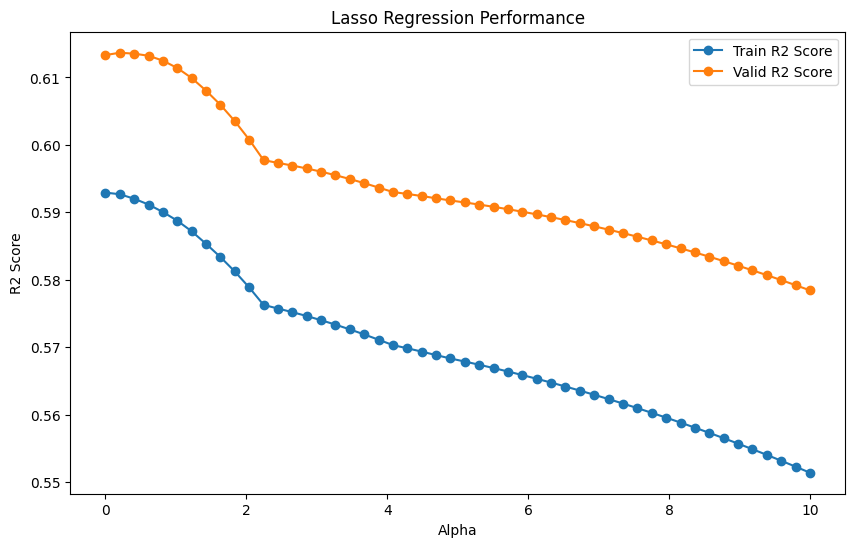

In [ ]:
# Визуализация результатов
plt.figure(figsize=(10, 6))
plt.plot(alpha_list, train_r2_scores, label='Train R2 Score', marker='o')
plt.plot(alpha_list, valid_r2_scores, label='Valid R2 Score', marker='o')
plt.xlabel('Alpha')
plt.ylabel('R2 Score')
plt.title('Lasso Regression Performance')
plt.legend()
plt.show()

In [ ]:
alpha = 0.1

# Создаем объект класса линейной регрессии с L1-регуляризацией (Lasso)
lasso_model = Lasso(alpha=alpha, max_iter=10000)
# Обучаем модель на тренировочных данных
lasso_model.fit(X_train_scaled, y_train)
# Делаем предсказания на тренировочном и валидационном наборах
y_train_pred = lasso_model.predict(X_train_scaled)
y_valid_pred = lasso_model.predict(X_valid_scaled)

# Рассчитываем метрики оценки модели с Lasso
mse_train = mean_squared_error(y_train, y_train_pred)
mse_valid = mean_squared_error(y_valid, y_valid_pred)
r2_valid = r2_score(y_valid, y_valid_pred)
adjusted_r2_valid = 1 - ((1 - r2_valid) * (n - 1)) / (n - p - 1)  # Adjusted R-squared

# Рассчитываем время обучения с Lasso
start_time = time.time()
lasso_model.fit(X_train_scaled, y_train)
training_time = time.time() - start_time

# Рассчитываем время прогноза для обучающего набора с Lasso
start_time = time.time()
_ = lasso_model.predict(X_train_scaled)
prediction_time_train = time.time() - start_time

# Рассчитываем время прогноза для валидационного набора с Lasso
start_time = time.time()
_ = lasso_model.predict(X_valid_scaled)
prediction_time_valid = time.time() - start_time

# Зарегистрируем результаты модели с Lasso
log_model_results('Lasso Regression', y_train, y_train_pred, y_valid, y_valid_pred,
                  training_time, prediction_time_train, prediction_time_valid)

<ipython-input-210-b0aeba877b43>:26: FutureWarning: The frame.append method is deprecated and will be removed from pandas in a future version. Use pandas.concat instead.
  model_log = model_log.append({'Model': model_name,


In [ ]:
model_log

,Model,r2_train,r2_valid,adjusted_r2_valid,mse_train,mse_valid,training_time,prediction_time_train,prediction_time_valid
0,Linear Regression,0.592931,0.613316,0.608924,169965.981667,151806.926990,0.027225,0.009439,0.011888
1,Linear Regression,0.592931,0.613316,0.608924,169965.981667,151806.926990,0.027225,0.009439,0.011888
2,Lasso Regression,0.592873,0.613561,0.609172,169990.501632,151710.626012,0.142605,0.002248,0.001199


Вспомним, что у нас при проверке на мультиколлинеарность были признаки с превышающими VIF показателями:

Features with high multicollinearity (VIF > 10.0):
['temperaturec', 'humidity', 'visibility10m', 'dew_pointtemperaturec', 'holiday_No Holiday', 'part_of_day_day']

Проверим, как обстоят дела сейчас:

Для оценки мультиколлинеарности после применения L1-регуляризации (Lasso), мы можем использовать коэффициенты, которые модель Lasso устанавливает для каждого признака. Поскольку L1-регуляризация может уменьшить веса некоторых признаков до нуля, мы можем рассмотреть ненулевые коэффициенты как наличие важных признаков, а нулевые коэффициенты - как признаки, которые Lasso исключил.

Вот как можно проверить коэффициенты Lasso и оценить их важность:

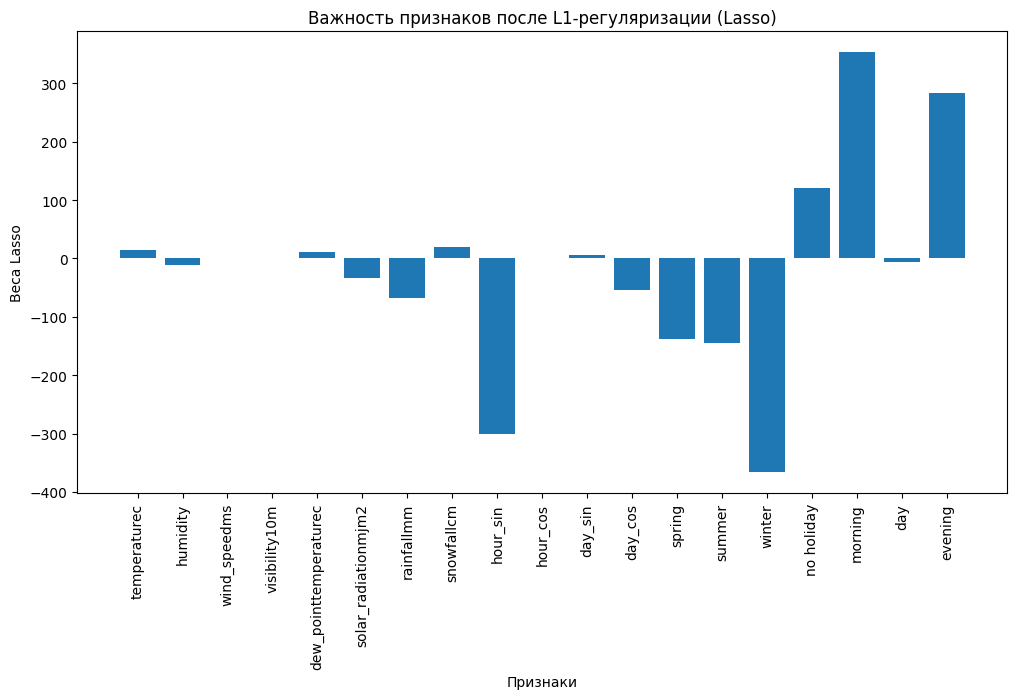

In [ ]:
lasso_model = Lasso(alpha=0.1, max_iter=10000)
lasso_model.fit(X_train, y_train)

# Получение весов от Lasso
lasso_weights = lasso_model.coef_

# Визуализация важности признаков
plt.figure(figsize=(12, 6))
plt.bar(range(len(lasso_weights)), lasso_weights, align='center')
plt.xticks(range(len(X.columns)), X.columns, rotation=90)
plt.xlabel('Признаки')
plt.ylabel('Веса Lasso')
plt.title('Важность признаков после L1-регуляризации (Lasso)')
plt.show()

In [ ]:
# Получим названия признаков с ненулевыми коэффициентами
selected_features = X_train.columns[model.coef_ == 0]

# Выведем на печать или используем по мере необходимости
print("Selected Features:")
print(selected_features)

Selected Features:
Index([], dtype='object')


Этот код строит столбчатую диаграмму, отображающую важность каждого признака после применения L1-регуляризации. Признаки с ненулевыми весами считаются важными, а те, у которых веса равны нулю, могут считаться исключенными. Это позволяет оценить влияние L1-регуляризации на мультиколлинеарность.

# Линейная регрессия с с L2-регуляризацией (Ridge)

In [ ]:
# Укажем функции и целевую переменную
X = data_copy.drop('rented_bikecount', axis=1) # Функции (исключая целевой столбец)
y = data_copy['rented_bikecount'] # Целевая переменная

# Разделим данные на обучающий и проверочный наборы
X_train, X_valid, y_train, y_valid = train_test_split(X, y, test_size=0.2, random_state=42)

# Инициализируем StandardScaler
scaler = StandardScaler()

# Используем функции обучения
X_train_scaled = scaler.fit_transform(X_train)

# Преобразуем функции проверки
X_valid_scaled = scaler.transform(X_valid)

# Инициализируем MinMaxScaler
scaler = MinMaxScaler()

# Fit and transform the training features
X_train_scaled = scaler.fit_transform(X_train)

# Transform the validation features using the same scaler
X_valid_scaled = scaler.transform(X_valid)

# Создаём список из 30 возможных значений alpha от 1 до 3000
alpha_list_ridge = np.linspace(1, 3000, 30)

# Создаём пустые списки для сохранения результатов
train_r2_scores_ridge = []
valid_r2_scores_ridge = []

# Перебираем значения alpha
for alpha_ridge in alpha_list_ridge:
    # Создаём объект класса линейной регрессии с L2-регуляризацией (Ridge)
    ridge_model = Ridge(alpha=alpha_ridge)

    # Обучаем модель на тренировочных данных
    ridge_model.fit(X_train_scaled, y_train)

    # Делаем предсказания на тренировочном и валидационном наборах
    y_train_pred_ridge = ridge_model.predict(X_train_scaled)
    y_valid_pred_ridge = ridge_model.predict(X_valid_scaled)

    # Рассчитываем метрику R-squared для тренировочного и валидационного наборов
    train_r2_ridge = r2_score(y_train, y_train_pred_ridge)
    valid_r2_ridge = r2_score(y_valid, y_valid_pred_ridge)

    # Сохраняем результаты
    train_r2_scores_ridge.append(train_r2_ridge)
    valid_r2_scores_ridge.append(valid_r2_ridge)

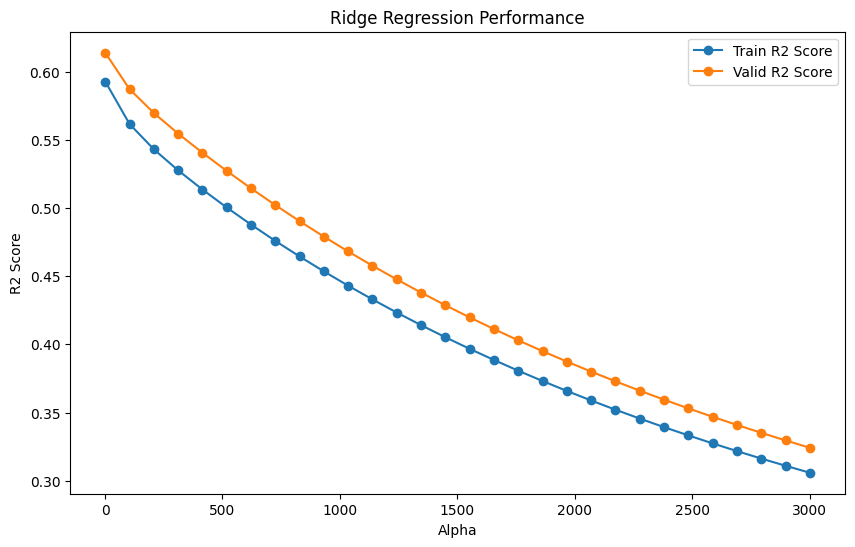

In [ ]:
# Визуализация результатов
plt.figure(figsize=(10, 6))
plt.plot(alpha_list_ridge, train_r2_scores_ridge, label='Train R2 Score', marker='o')
plt.plot(alpha_list_ridge, valid_r2_scores_ridge, label='Valid R2 Score', marker='o')
plt.xlabel('Alpha')
plt.ylabel('R2 Score')
plt.title('Ridge Regression Performance')
plt.legend()
plt.show()

Для Ridge выполнение модели при alpha=0 не целесообразно, так как лучший показтель модели при alpha=0 приравнивается к результатам L1-регуляризации (Lasso).

Чтобы вычислить метрики оценки и другие параметры для модели Ridge с  alpha = 3000, нам следует:

In [ ]:
# Инициализируем Ridge модель
ridge_model = Ridge(alpha=3000.0, max_iter=10000)

# Обучение модели
start_time = time.time()
ridge_model.fit(X_train_scaled, y_train)
training_time = time.time() - start_time

# Прогнозы для обучающей и валидационной выборок
start_time = time.time()
y_train_pred = ridge_model.predict(X_train_scaled)
prediction_time_train = time.time() - start_time

start_time = time.time()
y_valid_pred = ridge_model.predict(X_valid_scaled)
prediction_time_valid = time.time() - start_time

# Рассчет метрик
mse_train = mean_squared_error(y_train, y_train_pred)
mse_valid = mean_squared_error(y_valid, y_valid_pred)
r2_train = r2_score(y_train, y_train_pred)
r2_valid = r2_score(y_valid, y_valid_pred)
adjusted_r2_valid = 1 - (1 - r2_valid) * (len(y_valid) - 1) / (len(y_valid) - X_valid.shape[1] - 1)

# Вывод результатов и времени
print("Training MSE: {:.4f}".format(mse_train))
print("Validation MSE: {:.4f}".format(mse_valid))
print("Training R^2: {:.4f}".format(r2_train))
print("Validation R^2: {:.4f}".format(r2_valid))
print("Adjusted Validation R^2: {:.4f}".format(adjusted_r2_valid))
print("Training Time: {:.4f} seconds".format(training_time))
print("Prediction Time (Training): {:.6f} seconds".format(prediction_time_train))
print("Prediction Time (Validation): {:.6f} seconds".format(prediction_time_valid))

Training MSE: 289832.4980
Validation MSE: 265328.8193
Training R^2: 0.3059
Validation R^2: 0.3242
Adjusted Validation R^2: 0.3165
Training Time: 0.0146 seconds
Prediction Time (Training): 0.002748 seconds
Prediction Time (Validation): 0.000490 seconds


In [ ]:
log_model_results(ridge_model, y_train, y_train_pred, y_valid, y_valid_pred,
                  training_time, prediction_time_train, prediction_time_valid)

# Полиномиальная регрессия

Для того чтобы обучить модель мы так же используем метод fit(), а чтобы сгенерировать новую таблицу признаков, в которую будут включены полиномиальные признаки, используется метод transform(), в который нужно передать выборки:

In [ ]:
# Засекаем начальное время
start_time = time.time()

from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.model_selection import GridSearchCV

# Укажем функции и целевую переменную
X = data_copy.drop('rented_bikecount', axis=1) # Функции (исключая целевой столбец)
y = data_copy['rented_bikecount'] # Целевая переменная

# Разделим данные на обучающий и проверочный наборы
X_train, X_valid, y_train, y_valid = train_test_split(X, y, test_size=0.2, random_state=42)

# Определим степень многочлена
degree = 2  # Можно настроить по своему усмотрению

# Создадим полиномиальные признаки
poly_features = PolynomialFeatures(degree=degree, include_bias=False)
X_train_poly = poly_features.fit_transform(X_train)
X_valid_poly = poly_features.transform(X_valid)

# Масштабируем функции
scaler = StandardScaler()
X_train_poly_scaled = scaler.fit_transform(X_train_poly)
X_valid_poly_scaled = scaler.transform(X_valid_poly)

# Создадим Lasso model
lasso_model_poly = Lasso(max_iter=10000)

# Определим параметры для перебора
param_grid = {'alpha': np.linspace(0, 5, 30)}

# Создадим объект GridSearchCV
grid_search = GridSearchCV(estimator=lasso_model_poly, param_grid=param_grid, scoring='r2', cv=5)

# Выполним подгонку с перебором параметров
grid_search.fit(X_train_poly_scaled, y_train)

# Получим лучшие параметры
best_alpha = grid_search.best_params_['alpha']

# Создадим Lasso model с лучшими параметрами
lasso_model_poly_best = Lasso(alpha=best_alpha, max_iter=10000)

# Подсчет времени выполнения
execution_time = time.time() - start_time
print()
print('*' * 75)
print()
print(f"Время выполнения кода: {execution_time} секунд")
print(f"Лучшие параметры модели достигаются при alpha={best_alpha}")

/usr/local/lib/python3.10/dist-packages/sklearn/model_selection/_validation.py:686: UserWarning: With alpha=0, this algorithm does not converge well. You are advised to use the LinearRegression estimator
  estimator.fit(X_train, y_train, **fit_params)
/usr/local/lib/python3.10/dist-packages/sklearn/linear_model/_coordinate_descent.py:631: UserWarning: Coordinate descent with no regularization may lead to unexpected results and is discouraged.
  model = cd_fast.enet_coordinate_descent(
/usr/local/lib/python3.10/dist-packages/sklearn/linear_model/_coordinate_descent.py:631: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 1.848e+08, tolerance: 2.250e+05 Linear regression models with null weight for the l1 regularization term are more efficiently fitted using one of the solvers implemented in sklearn.linear_model.Ridge/RidgeCV instead.
  model = cd_fast.e


***************************************************************************

Время выполнения кода: 777.5320088863373 секунд
Лучшие параметры модели достигаются при alpha=0.0


/usr/local/lib/python3.10/dist-packages/sklearn/linear_model/_coordinate_descent.py:631: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 2.354e+08, tolerance: 2.828e+05 Linear regression models with null weight for the l1 regularization term are more efficiently fitted using one of the solvers implemented in sklearn.linear_model.Ridge/RidgeCV instead.
  model = cd_fast.enet_coordinate_descent(


In [ ]:
# Создадим полиномиальную Lasso model с лучшими параметрами
lasso_model_poly_best = Lasso(alpha=0.0, max_iter=10000)
# Обучение модели
lasso_model_poly_best.fit(X_train_poly_scaled, y_train)

# Прогнозы для обучающей и валидационной выборок
y_train_pred = lasso_model_poly_best.predict(X_train_poly_scaled)
y_valid_pred = lasso_model_poly_best.predict(X_valid_poly_scaled)

# Рассчитаем метрики оценки модели lasso_mode
mse_train = mean_squared_error(y_train, y_train_pred)
mse_valid = mean_squared_error(y_valid, y_valid_pred)
r2_valid = r2_score(y_valid, y_valid_pred)
adjusted_r2_valid = 1 - ((1 - r2_valid) * (n - 1)) / (n - p - 1)  # Поправленный R-квадрат

# Рассчитаем время обучения модели lasso_model_poly_best
start_time = time.time()
lasso_model_poly_best.fit(X_train_poly_scaled, y_train)
training_time = time.time() - start_time

# Рассчитаем время прогнозирования для выборки обучения для модели lasso_model_poly_best
start_time = time.time()
_ = lasso_model_poly_best.predict(X_train_poly_scaled)
prediction_time_train = time.time() - start_time

# Рассчитаем время прогнозирования для выборки валидации для модели lasso_model_poly_best
start_time = time.time()
_ = lasso_model_poly_best.predict(X_valid_poly_scaled)
prediction_time_valid = time.time() - start_time

<ipython-input-222-77f3b459ab05>:4: UserWarning: With alpha=0, this algorithm does not converge well. You are advised to use the LinearRegression estimator
  lasso_model_poly_best.fit(X_train_poly_scaled, y_train)
/usr/local/lib/python3.10/dist-packages/sklearn/linear_model/_coordinate_descent.py:631: UserWarning: Coordinate descent with no regularization may lead to unexpected results and is discouraged.
  model = cd_fast.enet_coordinate_descent(
/usr/local/lib/python3.10/dist-packages/sklearn/linear_model/_coordinate_descent.py:631: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 2.354e+08, tolerance: 2.828e+05 Linear regression models with null weight for the l1 regularization term are more efficiently fitted using one of the solvers implemented in sklearn.linear_model.Ridge/RidgeCV instead.
  model = cd_fast.enet_coordinate_descent(
<ipython-input

In [ ]:
# Example usage:
log_model_results(lasso_model_poly_best, y_train, y_train_pred, y_valid, y_valid_pred,
                  training_time, prediction_time_train, prediction_time_valid)

<ipython-input-210-b0aeba877b43>:26: FutureWarning: The frame.append method is deprecated and will be removed from pandas in a future version. Use pandas.concat instead.
  model_log = model_log.append({'Model': model_name,


# Регрессия с применением log y

In [ ]:
X = data_copy.drop(['rented_bikecount'], axis=1)
y = data_copy['rented_bikecount']

<ipython-input-242-93dc82c56261>:11: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(log_y, fit=norm);



 mu = 729.16 and sigma = 642.31



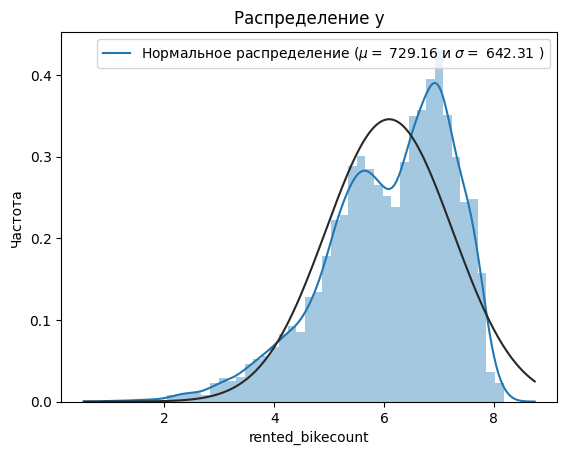

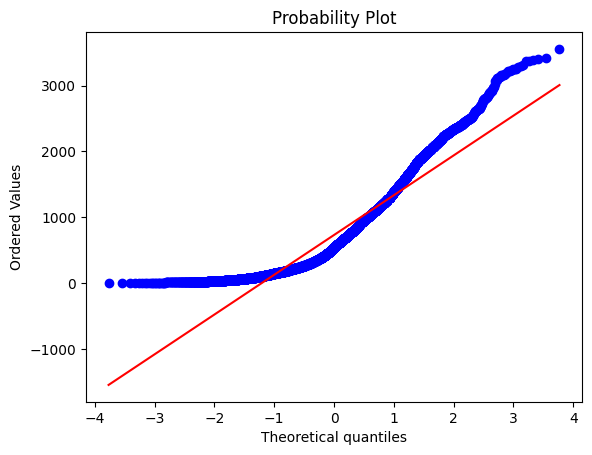

In [ ]:
from scipy.stats import norm, probplot
from sklearn.preprocessing import FunctionTransformer

# Копируем целевую переменную для преобразования
log_y = y.copy()

# Применяем логарифмическое преобразование log(1+x) ко всем элементам столбца
log_y = np.log1p(log_y)

# Проверяем новое распределение
sns.distplot(log_y, fit=norm);

# Получаем параметры распределения, которые использовались в функции
(mu, sigma) = norm.fit(y)
print('\n mu = {:.2f} and sigma = {:.2f}\n'.format(mu, sigma))

# Теперь строим гистограмму с распределением
plt.legend(['Нормальное распределение ($\mu=$ {:.2f} и $\sigma=$ {:.2f} )'.format(mu, sigma)],
           loc='best')
plt.ylabel('Частота')
plt.title('Распределение y')

# Строим QQ-график
fig = plt.figure()
probplot(y, plot=plt)
plt.show()

In [ ]:
# Делим данные на обучающий и валидационный наборы
X_train, X_valid, y_train, y_valid = train_test_split(X, log_y, test_size=0.2, random_state=42)

# X_train и y_train будут содержать обучающие данные
# X_valid и y_valid будут содержать валидационные данные

In [ ]:
# Создаем объект StandardScaler
scaler = StandardScaler()

# Стандартизируем обучающий набор
X_train_scaled = scaler.fit_transform(X_train)

# Применяем ту же стандартизацию к валидационному набору
X_valid_scaled = scaler.transform(X_valid)

In [ ]:
# Инициируем и обучаем linear regression model
linear_model_y = LinearRegression()

# Измеряем время, потраченное на обучение
start_time_train = time.time()
linear_model_y.fit(X_train_scaled, y_train)
end_time_train = time.time()
training_time = end_time_train - start_time_train

# Предсказание на train
start_time_pred_train = time.time()
y_train_pred = linear_model_y.predict(X_train_scaled)
end_time_pred_train = time.time()
prediction_time_train = end_time_pred_train - start_time_pred_train

# Предсказание на validation set
start_time_pred_valid = time.time()
y_valid_pred = linear_model_y.predict(X_valid_scaled)
end_time_pred_valid = time.time()
prediction_time_valid = end_time_pred_valid - start_time_pred_valid

# Считаем метрики для train
r2_train = r2_score(y_train, y_train_pred)
mse_train = mean_squared_error(y_train, y_train_pred)

# Считаем метрики для valid
r2_valid = r2_score(y_valid, y_valid_pred)
mse_valid = mean_squared_error(y_valid, y_valid_pred)

# Скорректированный R-квадрат для valid
adjusted_r2_valid = 1 - (1 - r2_valid) * (len(y_valid) - 1) / (len(y_valid) - X_valid_scaled.shape[1] - 1)

In [ ]:
log_model_results(linear_model_y, y_train, y_train_pred, y_valid, y_valid_pred,
                  training_time, prediction_time_train, prediction_time_valid)

<ipython-input-210-b0aeba877b43>:26: FutureWarning: The frame.append method is deprecated and will be removed from pandas in a future version. Use pandas.concat instead.
  model_log = model_log.append({'Model': model_name,


In [ ]:
model_log

,Model,r2_train,r2_valid,adjusted_r2_valid,mse_train,mse_valid,training_time,prediction_time_train,prediction_time_valid
0,Linear Regression,0.592931,0.613316,0.608924,169965.981667,151806.926990,0.027225,0.009439,0.011888
1,Linear Regression,0.592931,0.613316,0.608924,169965.981667,151806.926990,0.027225,0.009439,0.011888
2,Lasso Regression,0.592873,0.613561,0.609172,169990.501632,151710.626012,0.142605,0.002248,0.001199
3,"Lasso(alpha=0.0, max_iter=10000)",0.833509,0.817344,0.815269,69516.056268,71708.427584,29.352898,0.002799,0.006345
4,"Ridge(alpha=3000.0, max_iter=10000)",0.833509,0.817344,0.815269,69516.056268,71708.427584,29.352898,0.002799,0.006345
5,"Lasso(alpha=0.1, max_iter=10000)",0.551833,0.572452,0.567597,187125.979871,167849.409460,0.023543,0.008075,0.002619
6,"Lasso(alpha=0.1, max_iter=10000)",0.538753,0.565828,0.560897,192587.395888,170450.088958,0.008926,0.003017,0.002496
7,"Lasso(alpha=0.1, max_iter=10000)",0.531274,0.556177,0.551137,195710.076139,174238.801235,0.016536,0.006315,0.002586
8,LinearRegression(),0.674129,0.673210,0.669499,0.442157,0.401001,0.007915,0.000842,0.000440


In [ ]:
# Создаём список из 50 возможных значений alpha от 0 до 5
alpha_list = np.linspace(0, 5, 50)

# Создаём пустые списки для сохранения результатов
train_r2_scores = []
valid_r2_scores = []

# Перебираем значения alpha
for alpha in alpha_list:
    # Создаём объект класса линейной регрессии с L1-регуляризацией (Lasso)
    lasso_model = Lasso(alpha=alpha, max_iter=10000)

    # Обучаем модель на тренировочных данных
    lasso_model.fit(X_train_scaled, y_train)

    # Делаем предсказания на тренировочном и валидационном наборах
    y_train_pred = lasso_model.predict(X_train_scaled)
    y_valid_pred = lasso_model.predict(X_valid_scaled)

    # Рассчитываем метрику R-squared для тренировочного и валидационного наборов
    train_r2 = r2_score(y_train, y_train_pred)
    valid_r2 = r2_score(y_valid, y_valid_pred)

    # Сохраняем результаты
    train_r2_scores.append(train_r2)
    valid_r2_scores.append(valid_r2)

<ipython-input-248-f827717188a4>:14: UserWarning: With alpha=0, this algorithm does not converge well. You are advised to use the LinearRegression estimator
  lasso_model.fit(X_train_scaled, y_train)
/usr/local/lib/python3.10/dist-packages/sklearn/linear_model/_coordinate_descent.py:631: UserWarning: Coordinate descent with no regularization may lead to unexpected results and is discouraged.
  model = cd_fast.enet_coordinate_descent(
/usr/local/lib/python3.10/dist-packages/sklearn/linear_model/_coordinate_descent.py:631: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 1.497e+03, tolerance: 9.189e-01 Linear regression models with null weight for the l1 regularization term are more efficiently fitted using one of the solvers implemented in sklearn.linear_model.Ridge/RidgeCV instead.
  model = cd_fast.enet_coordinate_descent(


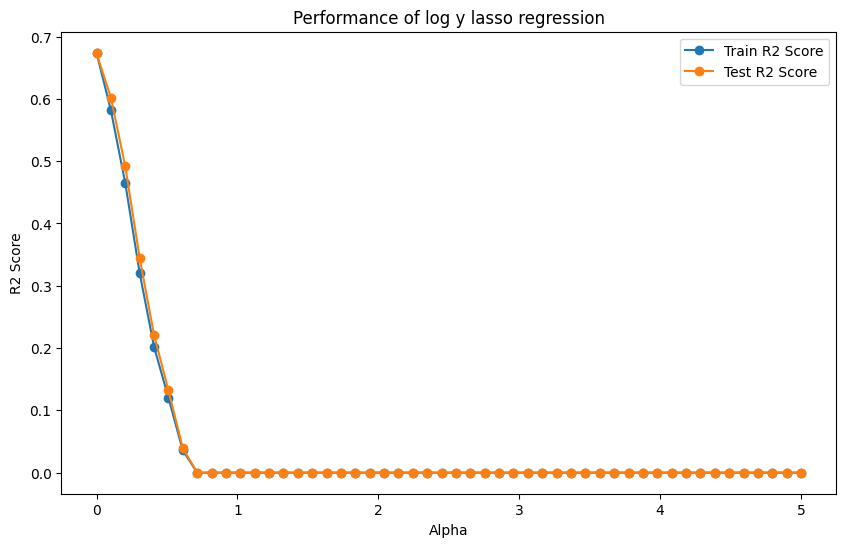

In [ ]:
# Визуализация результатов
plt.figure(figsize=(10, 6))
plt.plot(alpha_list, train_r2_scores, label='Train R2 Score', marker='o')
plt.plot(alpha_list, valid_r2_scores, label='Test R2 Score', marker='o')
plt.xlabel('Alpha')
plt.ylabel('R2 Score')
plt.title('Performance of log y lasso regression')
plt.legend()
plt.show()

In [ ]:
# Инициируем и обучаем Lasso regression model
lasso_model_y = Lasso(alpha=0.0, max_iter=10000)

# Измеряем время, потраченное на обучение
start_time_train_lasso = time.time()
lasso_model_y.fit(X_train_scaled, y_train)
end_time_train_lasso = time.time()
training_time = end_time_train_lasso - start_time_train_lasso

# Предсказание на train
start_time_pred_train_lasso = time.time()
y_train_pred_lasso = lasso_model_y.predict(X_train_scaled)
end_time_pred_train_lasso = time.time()
prediction_time_train = end_time_pred_train_lasso - start_time_pred_train_lasso

# Предсказание на validation set
start_time_pred_valid_lasso = time.time()
y_valid_pred_lasso = lasso_model_y.predict(X_valid_scaled)
end_time_pred_valid_lasso = time.time()
prediction_time_valid = end_time_pred_valid_lasso - start_time_pred_valid_lasso

# Считаем метрики для train
r2_train = r2_score(y_train, y_train_pred_lasso)
mse_train = mean_squared_error(y_train, y_train_pred_lasso)

# Считаем метрики для valid
r2_valid = r2_score(y_valid, y_valid_pred_lasso)
mse_valid = mean_squared_error(y_valid, y_valid_pred_lasso)

# Скорректированный R-квадрат для valid
adjusted_r2_valid = 1 - (1 - r2_valid) * (len(y_valid) - 1) / (len(y_valid) - X_valid_scaled.shape[1] - 1)

In [ ]:
log_model_results(lasso_model_y, y_train, y_train_pred, y_valid, y_valid_pred,
                  training_time, prediction_time_train, prediction_time_valid)

<ipython-input-210-b0aeba877b43>:26: FutureWarning: The frame.append method is deprecated and will be removed from pandas in a future version. Use pandas.concat instead.
  model_log = model_log.append({'Model': model_name,


In [ ]:
model_log

,Model,r2_train,r2_valid,adjusted_r2_valid,mse_train,mse_valid,training_time,prediction_time_train,prediction_time_valid
0,Linear Regression,0.592931,0.613316,0.608924,169965.981667,151806.926990,0.027225,0.009439,0.011888
1,Linear Regression,0.592931,0.613316,0.608924,169965.981667,151806.926990,0.027225,0.009439,0.011888
2,Lasso Regression,0.592873,0.613561,0.609172,169990.501632,151710.626012,0.142605,0.002248,0.001199
3,"Lasso(alpha=0.0, max_iter=10000)",0.833509,0.817344,0.815269,69516.056268,71708.427584,29.352898,0.002799,0.006345
4,"Ridge(alpha=3000.0, max_iter=10000)",0.833509,0.817344,0.815269,69516.056268,71708.427584,29.352898,0.002799,0.006345
5,"Lasso(alpha=0.1, max_iter=10000)",0.551833,0.572452,0.567597,187125.979871,167849.409460,0.023543,0.008075,0.002619
6,"Lasso(alpha=0.1, max_iter=10000)",0.538753,0.565828,0.560897,192587.395888,170450.088958,0.008926,0.003017,0.002496
7,"Lasso(alpha=0.1, max_iter=10000)",0.531274,0.556177,0.551137,195710.076139,174238.801235,0.016536,0.006315,0.002586
8,LinearRegression(),0.674129,0.673210,0.669499,0.442157,0.401001,0.007915,0.000842,0.000440
9,"Lasso(alpha=0.5, max_iter=10000)",0.000000,-0.000181,-0.011540,1.356846,1.227313,0.003742,0.004709,0.001147


In [ ]:
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.model_selection import GridSearchCV

# Определим степень многочлена
degree = 2  # Можно настроить по своему усмотрению

# Создадим полиномиальные признаки
poly_features = PolynomialFeatures(degree=degree, include_bias=False)
X_train_poly = poly_features.fit_transform(X_train)
X_valid_poly = poly_features.transform(X_valid)

# Масштабируем функции
scaler = StandardScaler()
X_train_poly_scaled = scaler.fit_transform(X_train_poly)
X_valid_poly_scaled = scaler.transform(X_valid_poly)

# Создадим Lasso model
lasso_model_poly = Lasso(max_iter=10000)

# Определим параметры для перебора
param_grid = {'alpha': np.linspace(0, 5, 30)}

# Создадим объект GridSearchCV
grid_search = GridSearchCV(estimator=lasso_model_poly, param_grid=param_grid, scoring='r2', cv=5)

# Выполним подгонку с перебором параметров
grid_search.fit(X_train_poly_scaled, y_train)

# Получим лучшие параметры
best_alpha = grid_search.best_params_['alpha']

# Создадим Lasso model с лучшими параметрами
lasso_model_poly_best = Lasso(alpha=best_alpha, max_iter=10000)

# Тренируем
start_time_train = time.time()
lasso_model_poly_best.fit(X_train_poly_scaled, y_train)
end_time_train = time.time()
training_time = end_time_train - start_time_train

# Делаем предсказание на train
start_time_pred_train = time.time()
y_train_pred = lasso_model_poly_best.predict(X_train_poly_scaled)
end_time_pred_train = time.time()
prediction_time_train = end_time_pred_train - start_time_pred_train

# Делаем предсказание на valid
start_time_pred_valid = time.time()
y_valid_pred = lasso_model_poly_best.predict(X_valid_poly_scaled)
end_time_pred_valid = time.time()
prediction_time_valid = end_time_pred_valid - start_time_pred_valid

# Calculate R-squared for training set
r2_train = r2_score(y_train, y_train_pred)

# Calculate R-squared for validation set
r2_valid = r2_score(y_valid, y_valid_pred)

# Print best alpha and R-squared scores
print(f"Best alpha: {best_alpha}")
print(f"R-squared (Training): {r2_train}")
print(f"R-squared (Validation): {r2_valid}")

/usr/local/lib/python3.10/dist-packages/sklearn/model_selection/_validation.py:686: UserWarning: With alpha=0, this algorithm does not converge well. You are advised to use the LinearRegression estimator
  estimator.fit(X_train, y_train, **fit_params)
/usr/local/lib/python3.10/dist-packages/sklearn/linear_model/_coordinate_descent.py:631: UserWarning: Coordinate descent with no regularization may lead to unexpected results and is discouraged.
  model = cd_fast.enet_coordinate_descent(
/usr/local/lib/python3.10/dist-packages/sklearn/linear_model/_coordinate_descent.py:631: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 5.488e+02, tolerance: 7.354e-01 Linear regression models with null weight for the l1 regularization term are more efficiently fitted using one of the solvers implemented in sklearn.linear_model.Ridge/RidgeCV instead.
  model = cd_fast.e

Best alpha: 0.0
R-squared (Training): 0.8504965131006675
R-squared (Validation): 0.8160508346679375


/usr/local/lib/python3.10/dist-packages/sklearn/linear_model/_coordinate_descent.py:631: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 6.869e+02, tolerance: 9.189e-01 Linear regression models with null weight for the l1 regularization term are more efficiently fitted using one of the solvers implemented in sklearn.linear_model.Ridge/RidgeCV instead.
  model = cd_fast.enet_coordinate_descent(


In [ ]:
log_model_results(lasso_model_poly_best, y_train, y_train_pred, y_valid, y_valid_pred,
                  training_time, prediction_time_train, prediction_time_valid)

<ipython-input-210-b0aeba877b43>:26: FutureWarning: The frame.append method is deprecated and will be removed from pandas in a future version. Use pandas.concat instead.
  model_log = model_log.append({'Model': model_name,


In [ ]:
model_log

,Model,r2_train,r2_valid,adjusted_r2_valid,mse_train,mse_valid,training_time,prediction_time_train,prediction_time_valid
0,Linear Regression,0.592931,0.613316,0.608924,169965.981667,151806.926990,0.027225,0.009439,0.011888
1,Linear Regression,0.592931,0.613316,0.608924,169965.981667,151806.926990,0.027225,0.009439,0.011888
2,Lasso Regression,0.592873,0.613561,0.609172,169990.501632,151710.626012,0.142605,0.002248,0.001199
3,"Lasso(alpha=0.0, max_iter=10000)",0.833509,0.817344,0.815269,69516.056268,71708.427584,29.352898,0.002799,0.006345
4,"Ridge(alpha=3000.0, max_iter=10000)",0.833509,0.817344,0.815269,69516.056268,71708.427584,29.352898,0.002799,0.006345
5,"Lasso(alpha=0.1, max_iter=10000)",0.551833,0.572452,0.567597,187125.979871,167849.409460,0.023543,0.008075,0.002619
6,"Lasso(alpha=0.1, max_iter=10000)",0.538753,0.565828,0.560897,192587.395888,170450.088958,0.008926,0.003017,0.002496
7,"Lasso(alpha=0.1, max_iter=10000)",0.531274,0.556177,0.551137,195710.076139,174238.801235,0.016536,0.006315,0.002586
8,LinearRegression(),0.674129,0.673210,0.669499,0.442157,0.401001,0.007915,0.000842,0.000440
9,"Lasso(alpha=0.5, max_iter=10000)",0.000000,-0.000181,-0.011540,1.356846,1.227313,0.003742,0.004709,0.001147


In [ ]:
# Создаём список из 30 возможных значений alpha от 1 до 3000
alpha_list_ridge = np.linspace(1, 3000, 30)

# Создаём пустые списки для сохранения результатов
train_r2_scores_ridge = []
valid_r2_scores_ridge = []

# Перебираем значения alpha
for alpha_ridge in alpha_list_ridge:
    # Создаём объект класса линейной регрессии с L2-регуляризацией (Ridge)
    ridge_model = Ridge(alpha=alpha_ridge)

    # Обучаем модель на тренировочных данных
    ridge_model.fit(X_train_scaled, y_train)

    # Делаем предсказания на тренировочном и валидационном наборах
    y_train_pred_ridge = ridge_model.predict(X_train_scaled)
    y_valid_pred_ridge = ridge_model.predict(X_valid_scaled)

    # Рассчитываем метрику R-squared для тренировочного и валидационного наборов
    train_r2_ridge = r2_score(y_train, y_train_pred_ridge)
    valid_r2_ridge = r2_score(y_valid, y_valid_pred_ridge)

    # Сохраняем результаты
    train_r2_scores_ridge.append(train_r2_ridge)
    valid_r2_scores_ridge.append(valid_r2_ridge)

In [ ]:
# Инициализируем Ridge модель
ridge_model = Ridge(alpha=3000.0, max_iter=10000)

# Обучение модели
start_time = time.time()
ridge_model.fit(X_train_scaled, y_train)
training_time = time.time() - start_time

# Прогнозы для обучающей и валидационной выборок
start_time = time.time()
y_train_pred = ridge_model.predict(X_train_scaled)
prediction_time_train = time.time() - start_time

start_time = time.time()
y_valid_pred = ridge_model.predict(X_valid_scaled)
prediction_time_valid = time.time() - start_time

# Рассчет метрик
mse_train = mean_squared_error(y_train, y_train_pred)
mse_valid = mean_squared_error(y_valid, y_valid_pred)
r2_valid = r2_score(y_valid, y_valid_pred)

# Вывод результатов и времени
print("Training MSE: {:.4f}".format(mse_train))
print("Validation MSE: {:.4f}".format(mse_valid))
print("Validation R^2: {:.4f}".format(r2_valid))
print("Training Time: {:.4f} seconds".format(training_time))
print("Prediction Time (Training): {:.6f} seconds".format(prediction_time_train))
print("Prediction Time (Validation): {:.6f} seconds".format(prediction_time_valid))

Training MSE: 0.5303
Validation MSE: 0.4598
Validation R^2: 0.6253
Training Time: 0.0152 seconds
Prediction Time (Training): 0.000839 seconds
Prediction Time (Validation): 0.019627 seconds


In [ ]:
# Example usage:
log_model_results(ridge_model, y_train, y_train_pred, y_valid, y_valid_pred,
                  training_time, prediction_time_train, prediction_time_valid)

<ipython-input-210-b0aeba877b43>:26: FutureWarning: The frame.append method is deprecated and will be removed from pandas in a future version. Use pandas.concat instead.
  model_log = model_log.append({'Model': model_name,


In [ ]:
model_log

,Model,r2_train,r2_valid,adjusted_r2_valid,mse_train,mse_valid,training_time,prediction_time_train,prediction_time_valid
0,Linear Regression,0.592931,0.613316,0.608924,169965.981667,151806.926990,0.027225,0.009439,0.011888
1,Linear Regression,0.592931,0.613316,0.608924,169965.981667,151806.926990,0.027225,0.009439,0.011888
2,Lasso Regression,0.592873,0.613561,0.609172,169990.501632,151710.626012,0.142605,0.002248,0.001199
3,"Lasso(alpha=0.0, max_iter=10000)",0.833509,0.817344,0.815269,69516.056268,71708.427584,29.352898,0.002799,0.006345
4,"Ridge(alpha=3000.0, max_iter=10000)",0.833509,0.817344,0.815269,69516.056268,71708.427584,29.352898,0.002799,0.006345
5,"Lasso(alpha=0.1, max_iter=10000)",0.551833,0.572452,0.567597,187125.979871,167849.409460,0.023543,0.008075,0.002619
6,"Lasso(alpha=0.1, max_iter=10000)",0.538753,0.565828,0.560897,192587.395888,170450.088958,0.008926,0.003017,0.002496
7,"Lasso(alpha=0.1, max_iter=10000)",0.531274,0.556177,0.551137,195710.076139,174238.801235,0.016536,0.006315,0.002586
8,LinearRegression(),0.674129,0.673210,0.669499,0.442157,0.401001,0.007915,0.000842,0.000440
9,"Lasso(alpha=0.5, max_iter=10000)",0.000000,-0.000181,-0.011540,1.356846,1.227313,0.003742,0.004709,0.001147


На данном этапе наиболее привлекательные показатели у модели плиномиальной регрессии lasso_model_poly_best с параметрами Lasso(alpha=0.0, max_iter=10000)

# Дерево решений

In [ ]:
X = data_copy.drop(['rented_bikecount'], axis=1)
y = data_copy['rented_bikecount']

In [ ]:
# Масштабируем функции
scaler_forest = StandardScaler()
X_train_scaled_forest = scaler_forest.fit_transform(X_train)
X_valid_scaled_forest = scaler_forest.transform(X_valid)

In [ ]:
from sklearn.ensemble import RandomForestRegressor

# Определяем параметры, которые хотим перебирать
param_grid = {
    'n_estimators': [50, 100, 150],
    'max_depth': [None, 10, 20],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4]
}

# Создаём модель RandomForestRegressor
forest_model = RandomForestRegressor(random_state=42)

# Создаём объект GridSearchCV
grid_search = GridSearchCV(estimator=forest_model, param_grid=param_grid, scoring='r2', cv=3, n_jobs=-1)

# Измеряем время, потраченное на поиск оптимальных параметров
start_time_grid_search = time.time()
grid_search.fit(X_train_scaled, y_train)
end_time_grid_search = time.time()
grid_search_time = end_time_grid_search - start_time_grid_search

# Получаем оптимальные параметры
best_params = grid_search.best_params_

# Используем оптимальную модель для предсказания
y_train_pred_optimal = grid_search.predict(X_train_scaled)
y_valid_pred_optimal = grid_search.predict(X_valid_scaled)

# Считаем метрики для train и valid с оптимальной моделью
r2_train_optimal = r2_score(y_train, y_train_pred_optimal)
mse_train_optimal = mean_squared_error(y_train, y_train_pred_optimal)

r2_test_optimal = r2_score(y_valid, y_valid_pred_optimal)
mse_test_optimal = mean_squared_error(y_valid, y_valid_pred_optimal)

# Скорректированный R-квадрат для valid с оптимальной моделью
adjusted_r2_test_optimal = 1 - (1 - r2_test_optimal) * (len(y_valid) - 1) / (len(y_valid) - X_valid_scaled.shape[1] - 1)

In [ ]:
log_model_results(grid_search, y_train, y_train_pred_optimal, y_valid, y_valid_pred_optimal,
                  grid_search_time, prediction_time_train, prediction_time_valid)

<ipython-input-210-b0aeba877b43>:26: FutureWarning: The frame.append method is deprecated and will be removed from pandas in a future version. Use pandas.concat instead.
  model_log = model_log.append({'Model': model_name,


In [ ]:
model_log

,Model,r2_train,r2_valid,adjusted_r2_valid,mse_train,mse_valid,training_time,prediction_time_train,prediction_time_valid
0,Linear Regression,0.592931,0.613316,0.608924,169965.981667,151806.926990,0.027225,0.009439,0.011888
1,Linear Regression,0.592931,0.613316,0.608924,169965.981667,151806.926990,0.027225,0.009439,0.011888
2,Lasso Regression,0.592873,0.613561,0.609172,169990.501632,151710.626012,0.142605,0.002248,0.001199
3,"Lasso(alpha=0.0, max_iter=10000)",0.833509,0.817344,0.815269,69516.056268,71708.427584,29.352898,0.002799,0.006345
4,"Ridge(alpha=3000.0, max_iter=10000)",0.833509,0.817344,0.815269,69516.056268,71708.427584,29.352898,0.002799,0.006345
5,"Lasso(alpha=0.1, max_iter=10000)",0.551833,0.572452,0.567597,187125.979871,167849.409460,0.023543,0.008075,0.002619
6,"Lasso(alpha=0.1, max_iter=10000)",0.538753,0.565828,0.560897,192587.395888,170450.088958,0.008926,0.003017,0.002496
7,"Lasso(alpha=0.1, max_iter=10000)",0.531274,0.556177,0.551137,195710.076139,174238.801235,0.016536,0.006315,0.002586
8,LinearRegression(),0.674129,0.673210,0.669499,0.442157,0.401001,0.007915,0.000842,0.000440
9,"Lasso(alpha=0.5, max_iter=10000)",0.000000,-0.000181,-0.011540,1.356846,1.227313,0.003742,0.004709,0.001147


In [ ]:
from hyperopt import fmin, tpe, hp, STATUS_OK, Trials
from hyperopt.pyll.base import scope
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import cross_val_score
from sklearn.metrics import r2_score

# Задаем данные
X_train, X_valid, y_train, y_valid = train_test_split(X, log_y, test_size=0.2, random_state=42)

In [ ]:
# Задание пространства поиска параметров
space = {'n_estimators': hp.quniform('n_estimators', 90, 200, 10),
         'min_samples_leaf': hp.quniform('min_samples_leaf', 1, 20, 1),
         'max_features': hp.choice('max_features', ['sqrt', 'log2']),
         'max_depth': hp.quniform('max_depth', 1, 15, 1),
         'criterion': hp.choice('criterion', ['friedman_mse', 'poisson', 'absolute_error', 'squared_error'])}

In [ ]:
random_state = 42
def hyperopt_rf(params, cv=5, X=X_train, y=y_train, random_state=random_state):
    # функция получает комбинацию гиперпараметров в "params"
    params = {'min_samples_leaf': int(params['min_samples_leaf']),
              'max_features': params['max_features'],
             'max_depth': int(params['max_depth']),
             'criterion': 'friedman_mse',
              }

    # используем эту комбинацию для построения модели
    model = RandomForestRegressor(**params, random_state=random_state)

    # обучаем модель
    model.fit(X, y)

    # обучать модель можно также с помощью кросс-валидации
    # применим  cross validation с тем же количеством фолдов
    score = cross_val_score(model, X, y, cv=cv, scoring="r2", n_jobs=-1).mean()

    # метрику необходимо минимизировать, поэтому ставим знак минус
    return -score

In [ ]:
trials = Trials() # используется для логирования результатов

best=fmin(hyperopt_rf, # наша функция
          space=space, # пространство гиперпараметров
          algo=tpe.suggest, # алгоритм оптимизации, установлен по умолчанию, задавать необязательно
          max_evals=50, # максимальное количество итераций
          trials=trials, # логирование результатов
          rstate=np.random.default_rng(random_state)# фиксируем для повторяемости результата
         )

print(f"Наилучшие значения гиперпараметров {best}")

100%|██████████| 50/50 [03:52<00:00,  4.66s/trial, best loss: -0.8900910972122921]
Наилучшие значения гиперпараметров {'criterion': 1, 'max_depth': 14.0, 'max_features': 1, 'min_samples_leaf': 1.0, 'n_estimators': 100.0}


In [ ]:
forest_model = RandomForestRegressor(n_estimators=90, criterion ='squared_error', max_depth=14, max_features=3, min_samples_leaf=2)
forest_model.fit(X_train, y_train)

RandomForestRegressor(max_depth=14, max_features=3, min_samples_leaf=2,
                      n_estimators=90)

In [ ]:
# Задание параметров
param_grid = {
    'n_estimators': [90],
    'criterion': ['squared_error'],
    'max_depth': [14],
    'max_features': [3],
    'min_samples_leaf': [2]
}

# Инициализируем RandomForestRegressor
forest_model = RandomForestRegressor()

# Инициализируем GridSearchCV
grid_search = GridSearchCV(forest_model, param_grid, cv=5, scoring='r2', n_jobs=-1)

# Замер времени для подбора гиперпараметров
start_time_grid_search = time.time()
grid_search.fit(X_train, y_train)
end_time_grid_search = time.time()
grid_search_time = end_time_grid_search - start_time_grid_search

# Используем лучшие параметры
best_params = grid_search.best_params_

# Используем оптимальную модель для прогнозирования
y_train_pred = grid_search.predict(X_train)
y_valid_pred = grid_search.predict(X_valid)

# Считаем метрики для обучения и проверить их на оптимальной модели
r2_train = r2_score(y_train, y_train_pred)
mse_train = mean_squared_error(y_train, y_train_pred)

r2_valid = r2_score(y_valid, y_valid_pred)
mse_valid = mean_squared_error(y_valid, y_valid_pred)

# Скорректированный R-квадрат для соответствия оптимальной модели
adjusted_r2_valid = 1 - (1 - r2_valid) * (len(y_valid) - 1) / (len(y_valid) - X_valid.shape[1] - 1)

# Выводим результаты
print("Best hyperparameters:", best_params)
print("Training Time (Grid Search):", grid_search_time)
print("R-squared (Training - Optimal):", r2_train)
print("MSE (Training - Optimal):", mse_train)
print("R-squared (Validation - Optimal):", r2_valid)
print("MSE (Validation - Optimal):", mse_valid)
print("Adjusted R-squared (Validation - Optimal):", adjusted_r2_valid)

Best hyperparameters: {'criterion': 'squared_error', 'max_depth': 14, 'max_features': 3, 'min_samples_leaf': 2, 'n_estimators': 90}
Training Time (Grid Search): 4.114685297012329
R-squared (Training - Optimal): 0.9510558963203132
MSE (Training - Optimal): 0.06640962422346815
R-squared (Validation - Optimal): 0.8805799279163927
MSE (Validation - Optimal): 0.14653928201396074
Adjusted R-squared (Validation - Optimal): 0.879223692788127


In [ ]:
log_model_results(grid_search, y_train, y_train_pred, y_valid, y_valid_pred,
                  training_time, prediction_time_train, prediction_time_valid)

<ipython-input-210-b0aeba877b43>:26: FutureWarning: The frame.append method is deprecated and will be removed from pandas in a future version. Use pandas.concat instead.
  model_log = model_log.append({'Model': model_name,


In [ ]:
# Инициализируем RandomForestRegressor с лучшими гиперпараметрами
forest_model = RandomForestRegressor(n_estimators=100, criterion= 'squared_error', max_depth=14, max_features=2, min_samples_leaf=1)

# Замер времени для подбора гиперпараметров
start_time_train = time.time()
forest_model.fit(X_train, y_train)
end_time_train = time.time()
training_time = end_time_train - start_time_train

# Делаем предсказание на тренировочном наборе
start_time_pred_train = time.time()
y_train_pred = forest_model.predict(X_train)
end_time_pred_train = time.time()
prediction_time_train = end_time_pred_train - start_time_pred_train

# Делаем предсказание на валидационном наборе
start_time_pred_valid = time.time()
y_valid_pred = forest_model.predict(X_valid)
end_time_pred_valid = time.time()
prediction_time_valid = end_time_pred_valid - start_time_pred_valid

# Расчет метрик для тренировочного набора
r2_train = r2_score(y_train, y_train_pred)
mse_train = mean_squared_error(y_train, y_train_pred)

# Расчет метрик для валидационного набора
r2_valid = r2_score(y_valid, y_valid_pred)
mse_valid = mean_squared_error(y_valid, y_valid_pred)

# Скорректированный R-квадрат для валидационного набора
adjusted_r2_valid = 1 - (1 - r2_valid) * (len(y_valid) - 1) / (len(y_valid) - X_valid.shape[1] - 1)

# Выводим результаты на печать
print("Best hyperparameters:", best_params)
print("Training Time (Grid Search):", grid_search_time)
print("R-squared (Training - Optimal):", r2_train)
print("MSE (Training - Optimal):", mse_train)
print("R-squared (Validation - Optimal):", r2_valid)
print("MSE (Validation - Optimal):", mse_valid)
print("Adjusted R-squared (Validation - Optimal):", adjusted_r2_valid)

Best hyperparameters: {'criterion': 'squared_error', 'max_depth': 14, 'max_features': 3, 'min_samples_leaf': 2, 'n_estimators': 90}
Training Time (Grid Search): 4.114685297012329
R-squared (Training - Optimal): 0.9652835628216687
MSE (Training - Optimal): 0.04710486808541703
R-squared (Validation - Optimal): 0.87749339122735
MSE (Validation - Optimal): 0.15032674305321886
Adjusted R-squared (Validation - Optimal): 0.8761021027834287


In [ ]:
log_model_results(forest_model, y_train, y_train_pred, y_valid, y_valid_pred,
                  training_time, prediction_time_train, prediction_time_valid)

<ipython-input-210-b0aeba877b43>:26: FutureWarning: The frame.append method is deprecated and will be removed from pandas in a future version. Use pandas.concat instead.
  model_log = model_log.append({'Model': model_name,


# GradientBoosting

In [ ]:
from sklearn.ensemble import GradientBoostingRegressor

X = data_copy.drop(['rented_bikecount'], axis=1)
y = data_copy['rented_bikecount']

# Задаем данные
X_train, X_valid, y_train, y_valid = train_test_split(X, y, test_size=0.2, random_state=42)

In [ ]:
# Определение модели GradientBoostingRegressor
gb_model = GradientBoostingRegressor()

# Определение гиперпараметров для поиска
param_grid = {
    'n_estimators': [100, 200],  #
    'learning_rate': [0.1, 0.5],
    'max_depth': [3, 5],
    'min_samples_split': [2, 10],
    'min_samples_leaf': [1, 4]
}

# Использование GridSearchCV для настройки гиперпараметров
grid_search = GridSearchCV(estimator=gb_model, param_grid=param_grid, scoring='r2', cv=5, n_jobs=-1)

# Замер времени для подбора гиперпараметров
start_time_grid_search = time.time()
grid_search.fit(X_train, y_train)
end_time_grid_search = time.time()
grid_search_time = end_time_grid_search - start_time_grid_search

# Получение лучших гиперпараметров
best_params = grid_search.best_params_

# Использование лучшей модели для прогнозирования
y_train_pred = grid_search.predict(X_train)
y_valid_pred = grid_search.predict(X_valid)

# Расчет метрик для обучающего набора
r2_train = r2_score(y_train, y_train_pred)
mse_train = mean_squared_error(y_train, y_train_pred)

# Расчет метрик для валидационного набора
r2_valid = r2_score(y_valid, y_valid_pred)
mse_valid = mean_squared_error(y_valid, y_valid_pred)

# Скорректированный R-квадрат для валидационного набора
adjusted_r2_valid = 1 - (1 - r2_valid) * (len(y_valid) - 1) / (len(y_valid) - X_valid.shape[1] - 1)

In [ ]:
# Выводим результаты на печать
print("Best hyperparameters:", best_params)
print("Training Time (Grid Search):", grid_search_time)
print("R-squared (Training - Optimal):", r2_train)
print("MSE (Training - Optimal):", mse_train)
print("R-squared (Validation - Optimal):", r2_valid)
print("MSE (Validation - Optimal):", mse_valid)
print("Adjusted R-squared (Validation - Optimal):", adjusted_r2_valid)

Best hyperparameters: {'learning_rate': 0.1, 'max_depth': 5, 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 200}
Training Time (Grid Search): 310.3693222999573
R-squared (Training - Optimal): 0.9672746656537031
MSE (Training - Optimal): 13664.015493278519
R-squared (Validation - Optimal): 0.9166966813263797
MSE (Validation - Optimal): 32703.74685687052
Adjusted R-squared (Validation - Optimal): 0.9157506185321186


In [ ]:
start_time_prediction_train = time.time()
y_train_pred = grid_search.predict(X_train)
end_time_prediction_train = time.time()
prediction_time_train = end_time_prediction_train - start_time_prediction_train

start_time_prediction_valid = time.time()
y_valid_pred = grid_search.predict(X_valid)
end_time_prediction_valid = time.time()
prediction_time_valid = end_time_prediction_valid - start_time_prediction_valid

print(f'Время предсказания на тренировочном наборе после поиска гиперпараметров: {prediction_time_train:.4f} секунд')
print(f'Время предсказания на валидационном наборе после поиска гиперпараметров: {prediction_time_valid:.4f} секунд')

In [ ]:
log_model_results(grid_search, y_train, y_train_pred, y_valid, y_valid_pred,
                  grid_search_time, prediction_time_train, prediction_time_valid)

<ipython-input-210-b0aeba877b43>:26: FutureWarning: The frame.append method is deprecated and will be removed from pandas in a future version. Use pandas.concat instead.
  model_log = model_log.append({'Model': model_name,


In [ ]:
# Определение модели GradientBoostingRegressor
gb_model = GradientBoostingRegressor()

# Определение гиперпараметров для поиска
param_grid = {
    'n_estimators': [300, 500],  #
    'learning_rate': [0.01, 0.2, 0.75],  #
    'max_depth': [4, 7, 9],  #
    'min_samples_split': [5], # Оставлено только одно значение для ускорения поиска
    'min_samples_leaf': [2]  # Оставлено только одно значение для ускорения поиска
}

# Использование GridSearchCV для настройки гиперпараметров
grid_search = GridSearchCV(estimator=gb_model, param_grid=param_grid, scoring='r2', cv=5, n_jobs=-1)

# Замер времени для подбора гиперпараметров
start_time_grid_search = time.time()
grid_search.fit(X_train, y_train)
end_time_grid_search = time.time()
grid_search_time = end_time_grid_search - start_time_grid_search

# Получение лучших гиперпараметров
best_params = grid_search.best_params_

# Использование лучшей модели для прогнозирования
y_train_pred = grid_search.predict(X_train)
y_valid_pred = grid_search.predict(X_valid)

# Расчет метрик для обучающего набора
r2_train = r2_score(y_train, y_train_pred)
mse_train = mean_squared_error(y_train, y_train_pred)

# Расчет метрик для валидационного набора
r2_valid = r2_score(y_valid, y_valid_pred)
mse_valid = mean_squared_error(y_valid, y_valid_pred)

# Скорректированный R-квадрат для валидационного набора
adjusted_r2_valid = 1 - (1 - r2_valid) * (len(y_valid) - 1) / (len(y_valid) - X_valid.shape[1] - 1)

In [ ]:
# Print the results
print("Best hyperparameters:", best_params)
print("Training Time (Grid Search):", grid_search_time)
print("R-squared (Training - Optimal):", r2_train)
print("MSE (Training - Optimal):", mse_train)
print("R-squared (Validation - Optimal):", r2_valid)
print("MSE (Validation - Optimal):", mse_valid)
print("Adjusted R-squared (Validation - Optimal):", adjusted_r2_valid)

Best hyperparameters: {'learning_rate': 0.2, 'max_depth': 7, 'min_samples_leaf': 2, 'min_samples_split': 5, 'n_estimators': 300}
Training Time (Grid Search): 733.7239382266998
R-squared (Training - Optimal): 0.9991730717713222
MSE (Training - Optimal): 345.27256494666335
R-squared (Validation - Optimal): 0.9197522396741444
MSE (Validation - Optimal): 31504.17631991256
Adjusted R-squared (Validation - Optimal): 0.9188408783793499


In [ ]:
start_time_prediction_train = time.time()
y_train_pred = grid_search.predict(X_train)
end_time_prediction_train = time.time()
prediction_time_train = end_time_prediction_train - start_time_prediction_train

start_time_prediction_valid = time.time()
y_valid_pred = grid_search.predict(X_valid)
end_time_prediction_valid = time.time()
prediction_time_valid = end_time_prediction_valid - start_time_prediction_valid

print(f'Время предсказания на тренировочном наборе после поиска гиперпараметров: {prediction_time_train:.4f} секунд')
print(f'Время предсказания на валидационном наборе после поиска гиперпараметров: {prediction_time_valid:.4f} секунд')

In [ ]:
log_model_results(grid_search, y_train, y_train_pred, y_valid, y_valid_pred,
                  grid_search_time, prediction_time_train, prediction_time_valid)

<ipython-input-210-b0aeba877b43>:26: FutureWarning: The frame.append method is deprecated and will be removed from pandas in a future version. Use pandas.concat instead.
  model_log = model_log.append({'Model': model_name,


# Настройка гиперпараметров

In [ ]:
# сначала определяем оптимальное количество n_estimators
param_test1 = {'n_estimators':range(20, 81, 10)}

gsearch1 = GridSearchCV(estimator = GradientBoostingRegressor(learning_rate=0.1,
                                                               min_samples_split=50,
                                                               min_samples_leaf=5,
                                                               max_depth=5,
                                                               max_features='sqrt',
                                                               subsample=0.8,
                                                               random_state=10),
param_grid = param_test1, scoring='r2',n_jobs=4, cv=5)
gsearch1.fit(X_train,y_train)

GridSearchCV(cv=5,
             estimator=GradientBoostingRegressor(max_depth=5,
                                                 max_features='sqrt',
                                                 min_samples_leaf=5,
                                                 min_samples_split=50,
                                                 random_state=10,
                                                 subsample=0.8),
             n_jobs=4, param_grid={'n_estimators': range(20, 81, 10)},
             scoring='r2')

In [ ]:
gsearch1.best_params_

{'n_estimators': 80}

In [ ]:
gsearch1.best_score_

0.8954172739069456

In [ ]:
start_time_prediction_train = time.time()
y_train_pred = grid_search1.predict(X_train)
end_time_prediction_train = time.time()
prediction_time_train = end_time_prediction_train - start_time_prediction_train

start_time_prediction_valid = time.time()
y_valid_pred = grid_search1.predict(X_valid)
end_time_prediction_valid = time.time()
prediction_time_valid = end_time_prediction_valid - start_time_prediction_valid

print(f'Время предсказания на тренировочном наборе после поиска гиперпараметров: {prediction_time_train:.4f} секунд')
print(f'Время предсказания на валидационном наборе после поиска гиперпараметров: {prediction_time_valid:.4f} секунд')

In [ ]:
log_model_results(gsearch1, y_train, y_train_pred, y_valid, y_valid_pred,
                  training_time, prediction_time_train, prediction_time_valid)

<ipython-input-210-b0aeba877b43>:26: FutureWarning: The frame.append method is deprecated and will be removed from pandas in a future version. Use pandas.concat instead.
  model_log = model_log.append({'Model': model_name,


In [ ]:
# Настройка max_depth и min_samples_split поскольку они оказывают максимальное влиние на модель

param_test2 = {'max_depth':range(5,15,2), 'min_samples_split':range(5,10)}
gsearch2 = GridSearchCV(estimator = GradientBoostingRegressor(learning_rate=0.1,
                                                              n_estimators=80,
                                                              max_features='sqrt',
                                                              subsample=0.8,
                                                              random_state=10),
param_grid = param_test2, scoring='r2',n_jobs=4, cv=5)
gsearch2.fit(X_train,y_train)

GridSearchCV(cv=5,
             estimator=GradientBoostingRegressor(max_features='sqrt',
                                                 n_estimators=80,
                                                 random_state=10,
                                                 subsample=0.8),
             n_jobs=4,
             param_grid={'max_depth': range(5, 15, 2),
                         'min_samples_split': range(5, 10)},
             scoring='r2')

In [ ]:
gsearch2.best_params_

{'max_depth': 11, 'min_samples_split': 7}

In [ ]:
gsearch2.best_score_

0.9322234570604279

In [ ]:
start_time_prediction_train = time.time()
y_train_pred = grid_search2.predict(X_train)
end_time_prediction_train = time.time()
prediction_time_train = end_time_prediction_train - start_time_prediction_train

start_time_prediction_valid = time.time()
y_valid_pred = grid_search2.predict(X_valid)
end_time_prediction_valid = time.time()
prediction_time_valid = end_time_prediction_valid - start_time_prediction_valid

print(f'Время предсказания на тренировочном наборе после поиска гиперпараметров: {prediction_time_train:.4f} секунд')
print(f'Время предсказания на валидационном наборе после поиска гиперпараметров: {prediction_time_valid:.4f} секунд')

In [ ]:
log_model_results(gsearch2, y_train, y_train_pred, y_valid, y_valid_pred,
                  training_time, prediction_time_train, prediction_time_valid)

<ipython-input-210-b0aeba877b43>:26: FutureWarning: The frame.append method is deprecated and will be removed from pandas in a future version. Use pandas.concat instead.
  model_log = model_log.append({'Model': model_name,


In [ ]:
gbr_params_tuned = {'n_estimators': 80,
          'max_depth': 9,
          'min_samples_split': 7,
          'learning_rate': 0.1,
          'loss': 'squared_error'}

In [ ]:
gbr_tuned = GradientBoostingRegressor(**gbr_params_tuned, random_state=10)

In [ ]:
gbr_tuned.fit(X_train, y_train)

GradientBoostingRegressor(max_depth=9, min_samples_split=7, n_estimators=80,
                          random_state=10)

In [ ]:
y_train_pred = gbr_tuned.predict(X_train)
y_valid_pred = gbr_tuned.predict(X_valid)

In [ ]:
start_time_prediction_train = time.time()
y_train_pred = gbr_tuned.predict(X_train)
end_time_prediction_train = time.time()
prediction_time_train = end_time_prediction_train - start_time_prediction_train

start_time_prediction_valid = time.time()
y_valid_pred = gbr_tuned.predict(X_valid)
end_time_prediction_valid = time.time()
prediction_time_valid = end_time_prediction_valid - start_time_prediction_valid

print(f'Время предсказания на тренировочном наборе после поиска гиперпараметров: {prediction_time_train:.4f} секунд')
print(f'Время предсказания на валидационном наборе после поиска гиперпараметров: {prediction_time_valid:.4f} секунд')

In [ ]:
log_model_results(gbr_tuned, y_train, y_train_pred, y_valid, y_valid_pred,
                  training_time, prediction_time_train, prediction_time_valid)

<ipython-input-210-b0aeba877b43>:26: FutureWarning: The frame.append method is deprecated and will be removed from pandas in a future version. Use pandas.concat instead.
  model_log = model_log.append({'Model': model_name,


In [ ]:
model_log

,Model,r2_train,r2_valid,adjusted_r2_valid,mse_train,mse_valid,training_time,prediction_time_train,prediction_time_valid
0,Linear Regression,0.592931,0.613316,0.608924,169965.981667,151806.926990,0.027225,0.009439,0.011888
1,Linear Regression,0.592931,0.613316,0.608924,169965.981667,151806.926990,0.027225,0.009439,0.011888
2,Lasso Regression,0.592873,0.613561,0.609172,169990.501632,151710.626012,0.142605,0.002248,0.001199
3,"Lasso(alpha=0.0, max_iter=10000)",0.833509,0.817344,0.815269,69516.056268,71708.427584,29.352898,0.002799,0.006345
4,"Ridge(alpha=3000.0, max_iter=10000)",0.833509,0.817344,0.815269,69516.056268,71708.427584,29.352898,0.002799,0.006345
5,"Lasso(alpha=0.1, max_iter=10000)",0.551833,0.572452,0.567597,187125.979871,167849.409460,0.023543,0.008075,0.002619
6,"Lasso(alpha=0.1, max_iter=10000)",0.538753,0.565828,0.560897,192587.395888,170450.088958,0.008926,0.003017,0.002496
7,"Lasso(alpha=0.1, max_iter=10000)",0.531274,0.556177,0.551137,195710.076139,174238.801235,0.016536,0.006315,0.002586
8,LinearRegression(),0.674129,0.673210,0.669499,0.442157,0.401001,0.007915,0.000842,0.000440
9,"Lasso(alpha=0.5, max_iter=10000)",0.000000,-0.000181,-0.011540,1.356846,1.227313,0.003742,0.004709,0.001147


# Пайплайн

В библиотеке scikit-learn пайплайны реализованы как класс sklearn.pipeline.Pipeline(). Этот класс может быть использован для сбора воедино отбора и обработки данных вместе с итоговой моделью.

In [ ]:
from sklearn.pipeline import Pipeline

In [ ]:
X = data_copy.drop(['rented_bikecount'], axis=1)
y = data_copy['rented_bikecount']

# Задаем данные
X_train, X_valid, y_train, y_valid = train_test_split(X, y, test_size=0.2, random_state=42)

Определимся с метрикой, по которой будем оценивать качество модели — Root Mean Squared Error (RMSE), корень из среднего квадрата отклонения. Для этого на метод mean_squared_error подадим атрибут squared = False, который позволяет управлять возведением метрики в квадрат. Помимо RMSE для оценки качества модели будем использовать метрику R2.

In [ ]:
def rmse(y_hat, y):
    return mean_squared_error(y_hat, y, squared = False)

Обучим простейший пайплайн, вызвав метод fit(), состоящий из случайного леса и стандартизации (StandardScaler). На вход пайплайна подается список из преобразований в формате кортежа (название метода преобразования, по которому мы будем обращаться в дальнейшем к нашему преобразованию, объект  метода преобразования). Например:


In [ ]:
pipeline = Pipeline([('scaler', StandardScaler()), ('rf', RandomForestRegressor())])
pipeline.fit(X_train, y_train)

Pipeline(steps=[('scaler', StandardScaler()), ('rf', RandomForestRegressor())])

Посмотрим на метрики. Для этого сделаем предсказание пайплайном с помощью метода predict() и посчитаем R2 и RMSE с помощью функций r2_score() и rmse() соответственно. Округлим результат до четырёх цифр после запятой.

In [ ]:
# Получение прогнозов модели на тренировочном и валидационном наборах
start_time = time.time()

y_train_pred = pipeline.predict(X_train)
y_valid_pred = pipeline.predict(X_valid)

end_time = time.time()
training_time = end_time - start_time
print(f'Время выполнения: {training_time:.2f} секунд')

# Замер времени предсказания на тренировочном наборе
start_time_train = time.time()
y_train_pred = pipeline.predict(X_train)
end_time_train = time.time()
prediction_time_train = end_time_train - start_time_train

# Замер времени предсказания на валидационном наборе
start_time_valid = time.time()
y_valid_pred = pipeline.predict(X_valid)
end_time_valid = time.time()
prediction_time_valid = end_time_valid - start_time_valid

print(f'Время выполнения предсказаний на тренировочном наборе: {prediction_time_train:.4f} секунд')
print(f'Время выполнения предсказаний на валидационном наборе: {prediction_time_valid:.4f} секунд')


# Расчет и вывод метрик на тренировочном наборе
r2_train = r2_score(y_train, y_train_pred)
rmse_train = rmse(y_train_pred, y_train)
print(f'Тренировочные данные: R2 = {r2_train:.4f}, RMSE = {rmse_train:.4f}')

# Расчет и вывод метрик на валидационном наборе
r2_valid = r2_score(y_valid, y_valid_pred)
rmse_valid = rmse(y_valid_pred, y_valid)
print(f'Валидационные данные: R2 = {r2_valid:.4f}, RMSE = {rmse_valid:.4f}')

# Расчет и вывод adjusted R2 на валидационном наборе
n = len(X_valid)
p = X_valid.shape[1]
adjusted_r2_valid = 1 - (1 - r2_valid) * (n - 1) / (n - p - 1)
print(f'Adjusted R2 на валидационных данных: {adjusted_r2_valid:.4f}')

Время выполнения: 0.25 секунд
Время выполнения предсказаний на тренировочном наборе: 0.1740 секунд
Время выполнения предсказаний на валидационном наборе: 0.0694 секунд
Тренировочные данные: R2 = 0.9893, RMSE = 66.7582
Валидационные данные: R2 = 0.9110, RMSE = 186.9313
Adjusted R2 на валидационных данных: 0.9100


In [ ]:
log_model_results(pipeline, y_train, y_train_pred, y_valid, y_valid_pred,
                  training_time, prediction_time_train, prediction_time_valid)

<ipython-input-210-b0aeba877b43>:26: FutureWarning: The frame.append method is deprecated and will be removed from pandas in a future version. Use pandas.concat instead.
  model_log = model_log.append({'Model': model_name,


Теперь попробуем задать параметру n_estimators значение 200. Можно это сделать, используя метод set_params(), на вход которого надо подавать конструкцию <название модуля>__<название параметра>.

Используем GridSearch и попробуем взять 100, 200, 500 базовых моделей и сделать поиск оптимального параметра StardardScaler with_mean.

In [ ]:
param_grid = {'rf__max_features':['sqrt','log2'],
              'rf__max_depth':[5, 50, None]}
grid_search = GridSearchCV(pipeline, param_grid=param_grid, verbose = True, n_jobs=-1)


grid_search.fit(X_train, y_train)
print(grid_search.best_estimator_)

Fitting 5 folds for each of 6 candidates, totalling 30 fits
Pipeline(steps=[('scaler', StandardScaler()),
                ('rf',
                 RandomForestRegressor(max_depth=50, max_features='sqrt'))])


In [ ]:
y_pred = grid_search.best_estimator_.predict(X_valid)

In [ ]:
# Получение прогнозов модели на тренировочном и валидационном наборах
start_time = time.time()

y_train_pred = pipeline.predict(X_train)
y_valid_pred = pipeline.predict(X_valid)

end_time = time.time()
training_time = end_time - start_time
print(f'Время выполнения: {training_time:.2f} секунд')

# Расчет и вывод метрик на тренировочном наборе
r2_train = r2_score(y_train, y_train_pred)
rmse_train = rmse(y_train_pred, y_train)
print(f'Тренировочные данные: R2 = {r2_train:.4f}, RMSE = {rmse_train:.4f}')

# Расчет и вывод метрик на валидационном наборе
r2_valid = r2_score(y_valid, y_valid_pred)
rmse_valid = rmse(y_valid_pred, y_valid)
print(f'Валидационные данные: R2 = {r2_valid:.4f}, RMSE = {rmse_valid:.4f}')

# Расчет и вывод adjusted R2 на валидационном наборе
n = len(X_valid)
p = X_valid.shape[1]
adjusted_r2_valid = 1 - (1 - r2_valid) * (n - 1) / (n - p - 1)
print(f'Adjusted R2 на валидационных данных: {adjusted_r2_valid:.4f}')

Время выполнения: 0.20 секунд
Тренировочные данные: R2 = 0.9893, RMSE = 66.7582
Валидационные данные: R2 = 0.9110, RMSE = 186.9313
Adjusted R2 на валидационных данных: 0.9100


In [ ]:
# Замер времени предсказания на тренировочном наборе
start_time_train = time.time()
y_train_pred = pipeline.predict(X_train)
end_time_train = time.time()
prediction_time_train = end_time_train - start_time_train

# Замер времени предсказания на валидационном наборе
start_time_valid = time.time()
y_valid_pred = pipeline.predict(X_valid)
end_time_valid = time.time()
prediction_time_valid = end_time_valid - start_time_valid

print(f'Время выполнения предсказаний на тренировочном наборе: {prediction_time_train:.4f} секунд')
print(f'Время выполнения предсказаний на валидационном наборе: {prediction_time_valid:.4f} секунд')

Время выполнения предсказаний на тренировочном наборе: 0.1489 секунд
Время выполнения предсказаний на валидационном наборе: 0.0515 секунд


In [ ]:
log_model_results(pipeline, y_train, y_train_pred, y_valid, y_valid_pred,
                  training_time, prediction_time_train, prediction_time_valid)

<ipython-input-210-b0aeba877b43>:26: FutureWarning: The frame.append method is deprecated and will be removed from pandas in a future version. Use pandas.concat instead.
  model_log = model_log.append({'Model': model_name,


In [ ]:
# Ваш пайплайн с GradientBoostingRegressor
pipeline = Pipeline([('scaler', StandardScaler()), ('gb', GradientBoostingRegressor())])

# Параметры для GridSearchCV
param_grid = {'gb__max_depth': [5, 50, None],
              'gb__min_samples_split': [2, 5, 7],
              'gb__n_estimators': [50, 80, 100],
              'gb__random_state': [10]}

# Создание объекта GridSearchCV
grid_search = GridSearchCV(pipeline, param_grid=param_grid, verbose=True, n_jobs=-1)

# Замер времени обучения модели
start_time = time.time()

# Обучение GridSearchCV на тренировочных данных
grid_search.fit(X_train, y_train)

end_time = time.time()
training_time = end_time - start_time
print(f'Время обучения: {training_time:.2f} секунд')

# Вывод лучших параметров
print("Лучшие параметры:", grid_search.best_params_)

# Получение прогнозов модели на тренировочном и валидационном наборах
y_train_pred = grid_search.predict(X_train)
y_valid_pred = grid_search.predict(X_valid)

# Расчет и вывод метрик на тренировочном наборе
r2_train = r2_score(y_train, y_train_pred)
rmse_train = np.sqrt(mean_squared_error(y_train, y_train_pred))
print(f'Тренировочные данные: R2 = {r2_train:.4f}, RMSE = {rmse_train:.4f}')

# Расчет и вывод метрик на валидационном наборе
r2_valid = r2_score(y_valid, y_valid_pred)
rmse_valid = np.sqrt(mean_squared_error(y_valid, y_valid_pred))
print(f'Валидационные данные: R2 = {r2_valid:.4f}, RMSE = {rmse_valid:.4f}')

# Расчет и вывод adjusted R2 на валидационном наборе
n = len(X_valid)
p = X_valid.shape[1]
adjusted_r2_valid = 1 - (1 - r2_valid) * (n - 1) / (n - p - 1)
print(f'Adjusted R2 на валидационных данных: {adjusted_r2_valid:.4f}')

Fitting 5 folds for each of 27 candidates, totalling 135 fits
Время обучения: 298.33 секунд
Лучшие параметры: {'gb__max_depth': 5, 'gb__min_samples_split': 7, 'gb__n_estimators': 100, 'gb__random_state': 10}
Тренировочные данные: R2 = 0.9498, RMSE = 144.7704
Валидационные данные: R2 = 0.9088, RMSE = 189.1710
Adjusted R2 на валидационных данных: 0.9078


In [ ]:
# Замер времени предсказания на тренировочном наборе
start_time_train = time.time()
y_train_pred = pipeline.predict(X_train)
end_time_train = time.time()
prediction_time_train = end_time_train - start_time_train

# Замер времени предсказания на валидационном наборе
start_time_valid = time.time()
y_valid_pred = pipeline.predict(X_valid)
end_time_valid = time.time()
prediction_time_valid = end_time_valid - start_time_valid

print(f'Время выполнения предсказаний на тренировочном наборе: {prediction_time_train:.4f} секунд')
print(f'Время выполнения предсказаний на валидационном наборе: {prediction_time_valid:.4f} секунд')

NotFittedError: This StandardScaler instance is not fitted yet. Call 'fit' with appropriate arguments before using this estimator.

In [ ]:
log_model_results(pipeline, y_train, y_train_pred, y_valid, y_valid_pred,
                  training_time, prediction_time_train, prediction_time_valid)

Посмотрим как поведет себя наша модель на лучших параметрах{'max_depth': 11, 'min_samples_split': 7}, которые были в GradientBoostingRegressor у gsearch2

In [ ]:
# Известные параметры
known_params = {'max_depth': 11, 'min_samples_split': 7}

# Создание объекта GradientBoostingRegressor с известными параметрами
model = GradientBoostingRegressor(**known_params)

# Пайплайн с преобразованием данных
pipeline = Pipeline([('scaler', StandardScaler()), ('gb', model)])

# Замер времени обучения модели
start_time = time.time()

# Обучение пайплайна на тренировочных данных
pipeline.fit(X_train, y_train)

end_time = time.time()
training_time = end_time - start_time
print(f'Время обучения: {training_time:.2f} секунд')

# Получение прогнозов модели на тренировочном и валидационном наборах
y_train_pred = pipeline.predict(X_train)
y_valid_pred = pipeline.predict(X_valid)

# Расчет и вывод метрик на тренировочном наборе
r2_train = r2_score(y_train, y_train_pred)
rmse_train = np.sqrt(mean_squared_error(y_train, y_train_pred))
print(f'Тренировочные данные: R2 = {r2_train:.4f}, RMSE = {rmse_train:.4f}')

# Расчет и вывод метрик на валидационном наборе
r2_valid = r2_score(y_valid, y_valid_pred)
rmse_valid = np.sqrt(mean_squared_error(y_valid, y_valid_pred))
print(f'Валидационные данные: R2 = {r2_valid:.4f}, RMSE = {rmse_valid:.4f}')

# Расчет и вывод adjusted R2 на валидационном наборе
n = len(X_valid)
p = X_valid.shape[1]
adjusted_r2_valid = 1 - (1 - r2_valid) * (n - 1) / (n - p - 1)
print(f'Adjusted R2 на валидационных данных: {adjusted_r2_valid:.4f}')

In [ ]:
# Замер времени предсказания на тренировочном наборе
start_time_train = time.time()
y_train_pred = pipeline.predict(X_train)
end_time_train = time.time()
prediction_time_train = end_time_train - start_time_train

# Замер времени предсказания на валидационном наборе
start_time_valid = time.time()
y_valid_pred = pipeline.predict(X_valid)
end_time_valid = time.time()
prediction_time_valid = end_time_valid - start_time_valid

print(f'Время выполнения предсказаний на тренировочном наборе: {prediction_time_train:.4f} секунд')
print(f'Время выполнения предсказаний на валидационном наборе: {prediction_time_valid:.4f} секунд')

In [ ]:
log_model_results(pipeline, y_train, y_train_pred, y_valid, y_valid_pred,
                  training_time, prediction_time_train, prediction_time_valid)

In [ ]:
model_log

Теперь, когда наглядно представлены интересующие нас метрики разных моделей, мы можем выбрать наиболее оптимальную и работать с ней.